# MSNet Behavioral Fusion for EMS Schizophrenia Recognition

This notebook reproduces the official pretrained MSNet validation baseline, builds behavioral eye-movement features, evaluates conventional machine-learning baselines, performs probability-level MSNet + behavioral fusion, generates XAI/UMAP outputs, and prepares the additional analyses requested by the instructor.

Added final outputs include:

- comparison with Logistic Regression, Random Forest, HistGradientBoosting and the official EMS benchmark;
- validation confusion matrices for reproduced MSNet and the proposed fusion;
- subject-level examples corrected by fusion and remaining failure cases;
- a clear separation between 4-fold validation results and the held-out EMS test set;
- generation of the final `prob_test.txt` for the proposed fusion model, ready to email to the EMS authors;
- a submission metadata file and email template.

Main package output: `outputs/improve_behavioral_final_results.zip`.

## 1. Environment and input discovery

Inspect the Kaggle environment and locate the EMS dataset, pretrained MSNet files, and RINet feature dictionary.

In [1]:
import os
import sys
import glob
import torch
from pathlib import Path


def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "EMS").is_dir() and (candidate / "EMS_repo").is_dir():
            return candidate
    raise FileNotFoundError(
        "Cannot locate the project root containing EMS and EMS_repo. "
        "Start Jupyter from the RVIF_2026_Experiment directory."
    )


PROJECT_ROOT = find_project_root()
WORK_DIR = str(PROJECT_ROOT)
REPO_DIR = str(PROJECT_ROOT / "EMS_repo")
DATASET_DIR = str(PROJECT_ROOT / "EMS")
FEATURE_DICT = str(PROJECT_ROOT / "feature_dict_RINet.npy")
MODEL_SRC = str(PROJECT_ROOT / "model_parameters")
OUT_DIR = str(PROJECT_ROOT / "outputs" / "improve_behavioral")
BASELINE_BACKUP_DIR = str(PROJECT_ROOT / "work" / "result_pretrained_backup")

Path(OUT_DIR).mkdir(parents=True, exist_ok=True)
(PROJECT_ROOT / "work").mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Python:", sys.executable)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
print("Dataset:", DATASET_DIR)
print("Feature dictionary:", FEATURE_DICT)
print("Feature size (GB):", round(Path(FEATURE_DICT).stat().st_size / 1024**3, 2))
print("Windows safety: DataLoader workers are fixed at 0 to avoid duplicating the 11 GB feature dictionary.")

Project root: C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy
Python: c:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\.venv\Scripts\python.exe
CUDA available: True
GPU: NVIDIA GeForce RTX 2050
Dataset: C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\EMS
Feature dictionary: C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\feature_dict_RINet.npy
Feature size (GB): 10.88
Windows safety: DataLoader workers are fixed at 0 to avoid duplicating the 11 GB feature dictionary.


## 2. Repository and dataset setup

Use the local official EMS repository and prepare writable Windows paths.

In [2]:
import os
import sys
from pathlib import Path

required_repo_files = [
    "MSNet.py",
    "val.py",
    "test.py",
    "data_process/split_fix.py",
    "data_process/metrics_val.py",
    "data_process/metrics_ostu.py",
]

print("Using the local official EMS repository:", REPO_DIR)
for relative in required_repo_files:
    path = Path(REPO_DIR) / relative
    print(relative, "->", path.exists())
    assert path.exists(), f"Missing EMS source file: {path}"

venv_python = PROJECT_ROOT / ".venv" / "Scripts" / "python.exe"
if venv_python.exists() and Path(sys.executable).resolve() != venv_python.resolve():
    print("WARNING: select the 'RVIF EMS (Windows GPU)' kernel before continuing.")

Using the local official EMS repository: C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\EMS_repo
MSNet.py -> True
val.py -> True
test.py -> True
data_process/split_fix.py -> True
data_process/metrics_val.py -> True
data_process/metrics_ostu.py -> True


In [3]:
import os
import shutil
from pathlib import Path

RESULT_DIR = str(PROJECT_ROOT / "work" / "msnet_results")

required_paths = {
    "RINet feature dictionary": Path(FEATURE_DICT),
    "pretrained model directory": Path(MODEL_SRC),
    "EMS dataset": Path(DATASET_DIR),
    "official EMS repository": Path(REPO_DIR),
    "fold workbook": Path(DATASET_DIR) / "Train_Valid.xlsx",
}
for name, path in required_paths.items():
    print(name, "->", path, "->", path.exists())
    assert path.exists(), f"Missing {name}: {path}"

# Copy only the small checkpoints to a writable result directory. The 11 GB
# feature dictionary and the dataset remain in place and are never duplicated.
for set_name in ["Set_0", "Set_1", "Set_2", "Set_3"]:
    source_weight = Path(MODEL_SRC) / set_name / "best_model.pt"
    target_dir = Path(RESULT_DIR) / set_name
    target_dir.mkdir(parents=True, exist_ok=True)
    target_weight = target_dir / "best_model.pt"
    assert source_weight.exists(), f"Missing pretrained checkpoint: {source_weight}"
    if not target_weight.exists() or target_weight.stat().st_size != source_weight.stat().st_size:
        shutil.copy2(source_weight, target_weight)

print("Local setup completed without copying the dataset or feature dictionary.")
print("Writable MSNet results:", RESULT_DIR)

RINet feature dictionary -> C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\feature_dict_RINet.npy -> True
pretrained model directory -> C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\model_parameters -> True
EMS dataset -> C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\EMS -> True
official EMS repository -> C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\EMS_repo -> True
fold workbook -> C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\EMS\Train_Valid.xlsx -> True
Local setup completed without copying the dataset or feature dictionary.
Writable MSNet results: C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\work\msnet_results


## 3. MSNet baseline reproduction

Generate the official TXT inputs, run pretrained MSNet validation for four folds, and save baseline probabilities.

In [4]:
import os
import sys
import glob
import subprocess
from pathlib import Path

TXT_DIR = str(Path(DATASET_DIR) / "TXT")
expected_txt_count = 208 * 100
existing_txt = list(Path(TXT_DIR).glob("*.txt")) if Path(TXT_DIR).exists() else []

if len(existing_txt) != expected_txt_count:
    print(f"Generating fixation TXT files ({len(existing_txt)}/{expected_txt_count} currently present)...")
    cmd = [
        sys.executable,
        str(Path(REPO_DIR) / "data_process" / "split_fix.py"),
        "--dataset_dir", DATASET_DIR,
    ]
    subprocess.run(cmd, cwd=PROJECT_ROOT, check=True)
else:
    print("TXT inputs already complete; skipping regeneration.")

txt_files = sorted(glob.glob(str(Path(TXT_DIR) / "*.txt")))
assert len(txt_files) == expected_txt_count, (
    f"Expected {expected_txt_count} TXT files, found {len(txt_files)}"
)
print("TXT directory:", TXT_DIR)
print("Number of TXT files:", len(txt_files))
print("First 10 TXT files:")
for path in txt_files[:10]:
    print(path)

TXT inputs already complete; skipping regeneration.
TXT directory: C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\EMS\TXT
Number of TXT files: 20800
First 10 TXT files:
C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\EMS\TXT\000_act_001.txt
C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\EMS\TXT\000_act_002.txt
C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\EMS\TXT\000_act_003.txt
C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\EMS\TXT\000_act_004.txt
C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\EMS\TXT\000_act_005.txt
C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\EMS\TXT\000_art_006.txt
C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\EMS\TXT\000_art_007.txt
C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\EMS\TXT\000_art_008.txt
C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\EMS\TXT\000_art_009.txt
C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\EMS\TXT\000_art_010.txt


In [5]:
import os
import sys
import shutil
import glob
import subprocess
from pathlib import Path

RESULT_DIR = str(PROJECT_ROOT / "work" / "msnet_results")
BASELINE_BACKUP_DIR = str(PROJECT_ROOT / "work" / "result_pretrained_backup")

for set_name in ["Set_0", "Set_1", "Set_2", "Set_3"]:
    print(f"========== VALIDATE PRETRAINED {set_name} ==========")
    cmd = [
        sys.executable,
        str(Path(REPO_DIR) / "val.py"),
        "--dataset_dir", DATASET_DIR,
        "--feature_dict", FEATURE_DICT,
        "--result_root", RESULT_DIR,
        "--set_name", set_name,
        "--no_workers", "0",
    ]
    subprocess.run(cmd, cwd=PROJECT_ROOT, check=True)

subprocess.run(
    [sys.executable, str(Path(REPO_DIR) / "data_process" / "metrics_ostu.py"), "--result_root", RESULT_DIR],
    cwd=PROJECT_ROOT,
    check=True,
)
subprocess.run(
    [sys.executable, str(Path(REPO_DIR) / "data_process" / "metrics_val.py"), "--result_root", RESULT_DIR],
    cwd=PROJECT_ROOT,
    check=True,
)

summary_path = Path(RESULT_DIR) / "val.txt"
print("\nValidation summary:")
print(summary_path.read_text(encoding="utf-8"))

if Path(BASELINE_BACKUP_DIR).exists():
    shutil.rmtree(BASELINE_BACKUP_DIR)
shutil.copytree(RESULT_DIR, BASELINE_BACKUP_DIR)

print("Backed up baseline results to:", BASELINE_BACKUP_DIR)
for path in sorted(glob.glob(str(Path(BASELINE_BACKUP_DIR) / "Set_*" / "prob_val.txt"))):
    print(path)

========== VALIDATE PRETRAINED Set_0 ==========
========== VALIDATE PRETRAINED Set_1 ==========
========== VALIDATE PRETRAINED Set_2 ==========
========== VALIDATE PRETRAINED Set_3 ==========

Validation summary:
Set_0, acc:0.825, sentivity:0.7272727272727273, specificity:0.9444444444444444, auc:0.8964646464646464, precision:0.9411764705882353, F1_score:0.8205128205128205
Set_1, acc:0.8, sentivity:0.875, specificity:0.75, auc:0.8984375, precision:0.7, F1_score:0.7777777777777777
Set_2, acc:0.85, sentivity:0.8, specificity:0.9, auc:0.8975, precision:0.8888888888888888, F1_score:0.8421052631578948
Set_3, acc:0.85, sentivity:0.8181818181818182, specificity:0.8888888888888888, auc:0.8964646464646465, precision:0.9, F1_score:0.8571428571428572
average, acc:0.83125, sentivity:0.8051136363636364, specificity:0.8708333333333333, auc:0.8972166982323232, precision:0.857516339869281, F1_score:0.8243846796478376
best:Set_1
Backed up baseline results to: C:\Users\hweem\Documents\dav\rvif-2026-dungm

## 4. Split metadata and raw fixation inspection

Create the subject-to-fold mapping and inspect the raw fixation files used for behavioral feature engineering.

In [6]:
import os
import re
import glob
import numpy as np
import pandas as pd
from pathlib import Path

REPO_DIR = str(PROJECT_ROOT / "EMS_repo")
DATASET_DIR = str(PROJECT_ROOT / "EMS")
TXT_DIR = f"{DATASET_DIR}/TXT"
TRAIN_VALID_XLSX = f"{DATASET_DIR}/Train_Valid.xlsx"
BASELINE_RESULT_DIR = str(PROJECT_ROOT / "work" / "result_pretrained_backup")
OUT_DIR = str(PROJECT_ROOT / "outputs" / "improve_behavioral")

os.makedirs(OUT_DIR, exist_ok=True)

print("Check paths:")
for p in [REPO_DIR, DATASET_DIR, TXT_DIR, TRAIN_VALID_XLSX, BASELINE_RESULT_DIR, OUT_DIR]:
    print(p, "->", os.path.exists(p))

assert os.path.exists(TRAIN_VALID_XLSX), "Missing Train_Valid.xlsx"
assert os.path.exists(TXT_DIR), "Missing TXT folder"
assert os.path.exists(BASELINE_RESULT_DIR), "Missing result_pretrained_backup"

def subject_to_int(x):
    """
    Convert subject IDs such as 59, '059', or 'Subject_059' to integer form.
    """
    nums = re.findall(r"\d+", str(x))
    if not nums:
        return None
    return int(nums[0])

def label_from_subject_int(subject_int):
    """
    Label subjects using the EMS repository convention: HC IDs are below 200 and SZ IDs are 200 or above.
    """
    return 1 if subject_int >= 200 else 0

df_split = pd.read_excel(TRAIN_VALID_XLSX)

print("\nTrain_Valid.xlsx shape:", df_split.shape)
print("Columns:")
print(df_split.columns.tolist())

print("\nPreview Train_Valid.xlsx:")
display(df_split.head())

set_cols = [c for c in df_split.columns if str(c).startswith("Set_")]
print("\nDetected set columns:", set_cols)

subject_to_set = {}
rows = []

for set_name in set_cols:
    for v in df_split[set_name].dropna().values:
        sid = subject_to_int(v)
        if sid is None:
            continue
        
        subject_to_set[sid] = set_name
        rows.append({
            "subject_int": sid,
            "subject_id": f"{sid:03d}",
            "set_name": set_name,
            "label": label_from_subject_int(sid)
        })

split_map = (
    pd.DataFrame(rows)
    .drop_duplicates("subject_int")
    .sort_values("subject_int")
    .reset_index(drop=True)
)

print("\nNumber of train/valid subjects:", len(split_map))

print("\nSubjects per fold:")
display(split_map["set_name"].value_counts().sort_index())

print("\nLabels overall:")
display(split_map["label"].value_counts().sort_index())

print("\nLabels per fold:")
display(pd.crosstab(split_map["set_name"], split_map["label"]))

print("\nPreview split_map:")
display(split_map.head(20))

split_map_path = f"{OUT_DIR}/split_map.csv"
split_map.to_csv(split_map_path, index=False)
print("\nSaved split_map to:", split_map_path)

Check paths:
C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\EMS_repo -> True
C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\EMS -> True
C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\EMS/TXT -> True
C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\EMS/Train_Valid.xlsx -> True
C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\work\result_pretrained_backup -> True
C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\outputs\improve_behavioral -> True

Train_Valid.xlsx shape: (40, 4)
Columns:
['Set_0', 'Set_1', 'Set_2', 'Set_3']

Preview Train_Valid.xlsx:


,Set_0,Set_1,Set_2,Set_3
0,2,0,9,5
1,8,1,17,12
2,11,3,19,16
3,28,4,20,23
4,35,6,31,26



Detected set columns: ['Set_0', 'Set_1', 'Set_2', 'Set_3']

Number of train/valid subjects: 160

Subjects per fold:


set_name
Set_0    40
Set_1    40
Set_2    40
Set_3    40
Name: count, dtype: int64


Labels overall:


label
0    80
1    80
Name: count, dtype: int64


Labels per fold:


label,0,1
set_name,,
Set_0,18,22
Set_1,24,16
Set_2,20,20
Set_3,18,22



Preview split_map:


,subject_int,subject_id,set_name,label
0,0,000,Set_1,0
1,1,001,Set_1,0
2,2,002,Set_0,0
3,3,003,Set_1,0
4,4,004,Set_1,0
5,5,005,Set_3,0
6,6,006,Set_1,0
7,7,007,Set_1,0
8,8,008,Set_0,0
9,9,009,Set_2,0



Saved split_map to: C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\outputs\improve_behavioral/split_map.csv


In [7]:
import os
import glob
import pandas as pd
from pathlib import Path

RAW_FIX_DIR = f"{DATASET_DIR}/Train_Valid/Fixations"

print("RAW_FIX_DIR:", RAW_FIX_DIR)
print("Exists:", os.path.exists(RAW_FIX_DIR))

raw_files = []
for ext in ["*.xlsx", "*.xls", "*.csv", "*.txt"]:
    raw_files.extend(glob.glob(f"{RAW_FIX_DIR}/**/{ext}", recursive=True))

raw_files = sorted(raw_files)

print("\nNumber of raw fixation files:", len(raw_files))
print("First 20 raw files:")
for p in raw_files[:20]:
    print(p)

def read_any_table(path, nrows=10):
    ext = Path(path).suffix.lower()
    
    try:
        if ext in [".xlsx", ".xls"]:
            return pd.read_excel(path, nrows=nrows)
        
        if ext == ".csv":
            return pd.read_csv(path, nrows=nrows)
        
        if ext == ".txt":
            try:
                return pd.read_csv(path, sep="\t", nrows=nrows)
            except Exception:
                try:
                    return pd.read_csv(path, sep=",", nrows=nrows)
                except Exception:
                    return pd.read_csv(path, header=None, nrows=nrows)
    except Exception as e:
        return None

print("\nInspect first readable files:")
shown = 0

for p in raw_files[:50]:
    df_sample = read_any_table(p, nrows=10)
    
    if df_sample is None or df_sample.empty:
        continue
    
    print("\n" + "=" * 80)
    print("FILE:", p)
    print("Shape sample:", df_sample.shape)
    print("Columns:")
    print(df_sample.columns.tolist())
    print("\nPreview:")
    display(df_sample.head(10))
    
    shown += 1
    if shown >= 3:
        break

if shown == 0:
    print("No readable raw fixation file was found. Check RAW_FIX_DIR.")

RAW_FIX_DIR: C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\EMS/Train_Valid/Fixations
Exists: True

Number of raw fixation files: 160
First 20 raw files:
C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\EMS/Train_Valid/Fixations\000.xlsx
C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\EMS/Train_Valid/Fixations\001.xlsx
C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\EMS/Train_Valid/Fixations\002.xlsx
C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\EMS/Train_Valid/Fixations\003.xlsx
C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\EMS/Train_Valid/Fixations\004.xlsx
C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\EMS/Train_Valid/Fixations\005.xlsx
C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\EMS/Train_Valid/Fixations\006.xlsx
C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\EMS/Train_Valid/Fixations\007.xlsx
C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\EMS/Train_Valid/Fixations\008.xlsx
C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\EMS/Train_Valid/F

,IMAGE,FIX_INDEX,FIX_DURATION,FIX_X,FIX_Y,FIX_PUPIL
0,outman_054.jpg,1,205,518.5,371.3,1177
1,outman_054.jpg,2,90,275.1,282.2,1262
2,outman_054.jpg,3,305,600.3,271.1,1265
3,outman_054.jpg,4,269,635.2,269.2,1326
4,outman_054.jpg,5,318,597.3,266.0,1366
5,outman_054.jpg,6,585,575.4,269.3,1442
6,outman_054.jpg,7,531,610.9,274.1,1508
7,outman_054.jpg,8,336,595.0,333.7,1577
8,outman_054.jpg,9,400,597.8,599.6,1687
9,outman_054.jpg,10,325,550.1,580.0,1756



FILE: C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\EMS/Train_Valid/Fixations\001.xlsx
Shape sample: (10, 6)
Columns:
['IMAGE', 'FIX_INDEX', 'FIX_DURATION', 'FIX_X', 'FIX_Y', 'FIX_PUPIL']

Preview:


,IMAGE,FIX_INDEX,FIX_DURATION,FIX_X,FIX_Y,FIX_PUPIL
0,art_009.jpg,1,375,505.9,384.8,923
1,art_009.jpg,2,69,298.5,404.0,884
2,art_009.jpg,3,155,235.2,291.4,993
3,art_009.jpg,4,228,262.9,341.3,1098
4,art_009.jpg,5,286,243.7,343.8,1220
5,art_009.jpg,6,555,313.6,399.3,1275
6,art_009.jpg,7,217,394.3,563.6,1331
7,art_009.jpg,8,164,394.5,496.1,1296
8,art_009.jpg,9,154,384.0,414.9,1251
9,art_009.jpg,10,165,392.2,385.5,1248



FILE: C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\EMS/Train_Valid/Fixations\002.xlsx
Shape sample: (10, 6)
Columns:
['IMAGE', 'FIX_INDEX', 'FIX_DURATION', 'FIX_X', 'FIX_Y', 'FIX_PUPIL']

Preview:


,IMAGE,FIX_INDEX,FIX_DURATION,FIX_X,FIX_Y,FIX_PUPIL
0,noi_053.jpg,1,283,512.6,364.2,537
1,noi_053.jpg,2,302,419.2,485.5,658
2,noi_053.jpg,3,377,432.5,457.2,653
3,noi_053.jpg,4,345,443.4,415.8,735
4,noi_053.jpg,5,266,431.4,448.7,734
5,noi_053.jpg,6,278,301.2,395.7,718
6,noi_053.jpg,7,232,356.7,395.3,744
7,noi_053.jpg,8,287,658.1,550.0,824
8,noi_053.jpg,9,192,482.3,486.8,842
9,noi_053.jpg,10,207,687.7,594.7,781


## 5. Behavioral feature engineering

Extract stimulus-level duration, pupil, and scanpath features, then aggregate them into subject-level features.

In [8]:
import os
import re
import glob
import math
import numpy as np
import pandas as pd
from pathlib import Path

RAW_FIX_DIR = f"{DATASET_DIR}/Train_Valid/Fixations"
OUT_DIR = str(PROJECT_ROOT / "outputs" / "improve_behavioral")

SCREEN_W = 1024
SCREEN_H = 768
CENTER_X = SCREEN_W / 2
CENTER_Y = SCREEN_H / 2

def safe_std(x):
    x = np.asarray(x, dtype=float)
    if len(x) <= 1:
        return 0.0
    return float(np.std(x, ddof=0))

def safe_cv(mean, std):
    if mean is None or np.isnan(mean) or abs(mean) < 1e-8:
        return 0.0
    return float(std / mean)

def parse_subject_from_filename(path):
    """
    Raw fixation files are named by subject ID, for example 000.xlsx or 001.xlsx.
    """
    stem = Path(path).stem
    nums = re.findall(r"\d+", stem)
    if not nums:
        return None
    return int(nums[0])

def compute_one_stimulus_features(g):
    """
    Compute stimulus-level features from all fixations of one subject on one image.
    """
    out = {}
    
    g = g.sort_values("FIX_INDEX").reset_index(drop=True)
    
    fix_index = pd.to_numeric(g["FIX_INDEX"], errors="coerce")
    duration = pd.to_numeric(g["FIX_DURATION"], errors="coerce")
    x = pd.to_numeric(g["FIX_X"], errors="coerce")
    y = pd.to_numeric(g["FIX_Y"], errors="coerce")
    pupil = pd.to_numeric(g["FIX_PUPIL"], errors="coerce")
    
    df = pd.DataFrame({
        "fix_index": fix_index,
        "duration": duration,
        "x": x,
        "y": y,
        "pupil": pupil
    })
    
    df = df.dropna(subset=["fix_index", "x", "y"])
    df = df[
        (df["x"] >= 0) & (df["x"] < SCREEN_W) &
        (df["y"] >= 0) & (df["y"] < SCREEN_H)
    ]
    df = df.sort_values("fix_index").reset_index(drop=True)
    
    n = len(df)
    out["fixation_count"] = n
    
    if n == 0:
        return out
    
    d = df["duration"].dropna().values.astype(float)
    
    if len(d) > 0:
        d_mean = float(np.mean(d))
        d_std = safe_std(d)
        
        out["duration_mean"] = d_mean
        out["duration_std"] = d_std
        out["duration_cv"] = safe_cv(d_mean, d_std)
        out["duration_median"] = float(np.median(d))
        out["duration_min"] = float(np.min(d))
        out["duration_max"] = float(np.max(d))
        out["duration_total"] = float(np.sum(d))
        out["duration_q25"] = float(np.percentile(d, 25))
        out["duration_q75"] = float(np.percentile(d, 75))
        out["duration_iqr"] = out["duration_q75"] - out["duration_q25"]
        out["duration_first_fix"] = float(d[0])
        out["duration_first_5_mean"] = float(np.mean(d[:5]))
    else:
        for k in [
            "duration_mean", "duration_std", "duration_cv", "duration_median",
            "duration_min", "duration_max", "duration_total", "duration_q25",
            "duration_q75", "duration_iqr", "duration_first_fix", "duration_first_5_mean"
        ]:
            out[k] = np.nan
    
    p = df["pupil"].dropna().values.astype(float)
    
    if len(p) > 0:
        p_mean = float(np.mean(p))
        p_std = safe_std(p)
        
        out["pupil_mean"] = p_mean
        out["pupil_std"] = p_std
        out["pupil_cv"] = safe_cv(p_mean, p_std)
        out["pupil_median"] = float(np.median(p))
        out["pupil_min"] = float(np.min(p))
        out["pupil_max"] = float(np.max(p))
        out["pupil_q25"] = float(np.percentile(p, 25))
        out["pupil_q75"] = float(np.percentile(p, 75))
        out["pupil_iqr"] = out["pupil_q75"] - out["pupil_q25"]
        out["pupil_first_fix"] = float(p[0])
        out["pupil_first_5_mean"] = float(np.mean(p[:5]))
        
        delta_first = p - p[0]
        out["pupil_delta_first_mean"] = float(np.mean(delta_first))
        out["pupil_delta_first_std"] = safe_std(delta_first)
        out["pupil_delta_first_abs_mean"] = float(np.mean(np.abs(delta_first)))
        
        if len(p) >= 2:
            delta_step = np.diff(p)
            out["pupil_delta_step_mean"] = float(np.mean(delta_step))
            out["pupil_delta_step_std"] = safe_std(delta_step)
            out["pupil_delta_step_abs_mean"] = float(np.mean(np.abs(delta_step)))
        else:
            out["pupil_delta_step_mean"] = 0.0
            out["pupil_delta_step_std"] = 0.0
            out["pupil_delta_step_abs_mean"] = 0.0
    else:
        for k in [
            "pupil_mean", "pupil_std", "pupil_cv", "pupil_median", "pupil_min",
            "pupil_max", "pupil_q25", "pupil_q75", "pupil_iqr", "pupil_first_fix",
            "pupil_first_5_mean", "pupil_delta_first_mean", "pupil_delta_first_std",
            "pupil_delta_first_abs_mean", "pupil_delta_step_mean", "pupil_delta_step_std",
            "pupil_delta_step_abs_mean"
        ]:
            out[k] = np.nan
    
    out["pupil_missing_ratio"] = float(df["pupil"].isna().mean())
    
    xs = df["x"].values.astype(float)
    ys = df["y"].values.astype(float)
    
    out["x_mean"] = float(np.mean(xs))
    out["y_mean"] = float(np.mean(ys))
    out["x_std"] = safe_std(xs)
    out["y_std"] = safe_std(ys)
    
    out["x_dispersion"] = float(np.max(xs) - np.min(xs))
    out["y_dispersion"] = float(np.max(ys) - np.min(ys))
    out["xy_dispersion_area"] = out["x_dispersion"] * out["y_dispersion"]
    
    dist_center = np.sqrt((xs - CENTER_X) ** 2 + (ys - CENTER_Y) ** 2)
    out["distance_to_center_mean"] = float(np.mean(dist_center))
    out["distance_to_center_std"] = safe_std(dist_center)
    out["distance_to_center_max"] = float(np.max(dist_center))
    
    if n >= 2:
        dx = np.diff(xs)
        dy = np.diff(ys)
        sacc_amp = np.sqrt(dx ** 2 + dy ** 2)
        
        out["scanpath_length"] = float(np.sum(sacc_amp))
        out["saccade_amplitude_mean"] = float(np.mean(sacc_amp))
        out["saccade_amplitude_std"] = safe_std(sacc_amp)
        out["saccade_amplitude_median"] = float(np.median(sacc_amp))
        out["saccade_amplitude_max"] = float(np.max(sacc_amp))
    else:
        out["scanpath_length"] = 0.0
        out["saccade_amplitude_mean"] = 0.0
        out["saccade_amplitude_std"] = 0.0
        out["saccade_amplitude_median"] = 0.0
        out["saccade_amplitude_max"] = 0.0
    
    return out

raw_files = sorted(glob.glob(f"{RAW_FIX_DIR}/*.xlsx"))

stim_rows = []

for path in raw_files:
    sid = parse_subject_from_filename(path)
    
    if sid is None or sid not in subject_to_set:
        continue
    
    df_raw = pd.read_excel(path)
    
    required_cols = ["IMAGE", "FIX_INDEX", "FIX_DURATION", "FIX_X", "FIX_Y", "FIX_PUPIL"]
    missing = [c for c in required_cols if c not in df_raw.columns]
    if missing:
        print("Missing columns in", path, ":", missing)
        continue
    
    for image_name, g in df_raw.groupby("IMAGE"):
        feat = compute_one_stimulus_features(g)
        
        feat["subject_int"] = sid
        feat["subject_id"] = f"{sid:03d}"
        feat["set_name"] = subject_to_set[sid]
        feat["label"] = label_from_subject_int(sid)
        feat["image"] = image_name
        
        stim_rows.append(feat)

stim_behavior_features = pd.DataFrame(stim_rows)

meta_cols = ["subject_int", "subject_id", "set_name", "label", "image"]
other_cols = [c for c in stim_behavior_features.columns if c not in meta_cols]
stim_behavior_features = stim_behavior_features[meta_cols + other_cols]

stim_path = f"{OUT_DIR}/stim_behavior_features.csv"
stim_behavior_features.to_csv(stim_path, index=False)

print("Stimulus-level behavior features shape:", stim_behavior_features.shape)
print("Saved to:", stim_path)

print("\nNumber of subjects:", stim_behavior_features["subject_int"].nunique())
print("Number of unique images:", stim_behavior_features["image"].nunique())
print("Rows per subject summary:")
display(stim_behavior_features.groupby("subject_id")["image"].nunique().describe())

print("\nColumns:")
print(stim_behavior_features.columns.tolist())

print("\nPreview:")
display(stim_behavior_features.head())

Stimulus-level behavior features shape: (15912, 51)
Saved to: C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\outputs\improve_behavioral/stim_behavior_features.csv

Number of subjects: 160
Number of unique images: 100
Rows per subject summary:


count    160.00000
mean      99.45000
std        3.88158
min       63.00000
25%      100.00000
50%      100.00000
75%      100.00000
max      100.00000
Name: image, dtype: float64


Columns:
['subject_int', 'subject_id', 'set_name', 'label', 'image', 'fixation_count', 'duration_mean', 'duration_std', 'duration_cv', 'duration_median', 'duration_min', 'duration_max', 'duration_total', 'duration_q25', 'duration_q75', 'duration_iqr', 'duration_first_fix', 'duration_first_5_mean', 'pupil_mean', 'pupil_std', 'pupil_cv', 'pupil_median', 'pupil_min', 'pupil_max', 'pupil_q25', 'pupil_q75', 'pupil_iqr', 'pupil_first_fix', 'pupil_first_5_mean', 'pupil_delta_first_mean', 'pupil_delta_first_std', 'pupil_delta_first_abs_mean', 'pupil_delta_step_mean', 'pupil_delta_step_std', 'pupil_delta_step_abs_mean', 'pupil_missing_ratio', 'x_mean', 'y_mean', 'x_std', 'y_std', 'x_dispersion', 'y_dispersion', 'xy_dispersion_area', 'distance_to_center_mean', 'distance_to_center_std', 'distance_to_center_max', 'scanpath_length', 'saccade_amplitude_mean', 'saccade_amplitude_std', 'saccade_amplitude_median', 'saccade_amplitude_max']

Preview:


,subject_int,subject_id,set_name,label,image,fixation_count,duration_mean,duration_std,duration_cv,duration_median,...,y_dispersion,xy_dispersion_area,distance_to_center_mean,distance_to_center_std,distance_to_center_max,scanpath_length,saccade_amplitude_mean,saccade_amplitude_std,saccade_amplitude_median,saccade_amplitude_max
0,0,000,Set_1,0,act_001.jpg,19,224.947368,85.587428,0.380478,223.0,...,335.1,264293.37,229.053369,117.168388,451.102051,3868.191184,214.899510,120.938102,216.654704,460.068451
1,0,000,Set_1,0,act_002.jpg,17,259.058824,139.657763,0.539097,209.0,...,490.0,441686.00,257.355837,153.773985,472.083488,3165.197599,197.824850,133.353449,175.498191,393.433222
2,0,000,Set_1,0,act_003.jpg,18,243.111111,134.428374,0.552950,198.5,...,258.3,185821.02,294.654602,132.227646,516.259566,4129.817169,242.930422,196.130068,211.805217,705.710373
3,0,000,Set_1,0,act_004.jpg,16,269.187500,99.172337,0.368414,247.5,...,315.8,220302.08,239.966440,139.511348,406.026822,2835.736416,189.049094,179.647664,70.195513,652.467716
4,0,000,Set_1,0,act_005.jpg,17,260.176471,89.276329,0.343138,246.0,...,444.9,228500.64,184.000876,70.908007,397.671271,2454.217500,153.388594,100.159925,132.314600,318.429270


In [9]:
import os
import numpy as np
import pandas as pd

OUT_DIR = str(PROJECT_ROOT / "outputs" / "improve_behavioral")

stim_path = f"{OUT_DIR}/stim_behavior_features.csv"
if "stim_behavior_features" not in globals():
    stim_behavior_features = pd.read_csv(stim_path)

print("Loaded stim_behavior_features:", stim_behavior_features.shape)

meta_cols = ["subject_int", "subject_id", "set_name", "label", "image"]
numeric_cols = [c for c in stim_behavior_features.columns if c not in meta_cols]

print("Number of numeric stimulus features:", len(numeric_cols))

agg_funcs = ["mean", "std", "median", "min", "max"]

subject_agg = stim_behavior_features.groupby("subject_int")[numeric_cols].agg(agg_funcs)

subject_agg.columns = [f"{col}_{func}" for col, func in subject_agg.columns]
subject_agg = subject_agg.reset_index()

subject_meta = (
    stim_behavior_features[["subject_int", "subject_id", "set_name", "label"]]
    .drop_duplicates("subject_int")
    .copy()
)

num_valid_images = (
    stim_behavior_features.groupby("subject_int")["image"]
    .nunique()
    .reset_index()
    .rename(columns={"image": "num_valid_images"})
)

num_total_fixations = (
    stim_behavior_features.groupby("subject_int")["fixation_count"]
    .sum()
    .reset_index()
    .rename(columns={"fixation_count": "num_total_fixations"})
)

mean_fix_per_image = (
    stim_behavior_features.groupby("subject_int")["fixation_count"]
    .mean()
    .reset_index()
    .rename(columns={"fixation_count": "mean_fixations_per_image"})
)

subject_behavior_features = subject_meta.merge(subject_agg, on="subject_int", how="left")
subject_behavior_features = subject_behavior_features.merge(num_valid_images, on="subject_int", how="left")
subject_behavior_features = subject_behavior_features.merge(num_total_fixations, on="subject_int", how="left")
subject_behavior_features = subject_behavior_features.merge(mean_fix_per_image, on="subject_int", how="left")

subject_behavior_features = subject_behavior_features.sort_values("subject_int").reset_index(drop=True)

subject_path = f"{OUT_DIR}/subject_behavior_features.csv"
subject_behavior_features.to_csv(subject_path, index=False)

print("Subject-level behavior features shape:", subject_behavior_features.shape)
print("Saved to:", subject_path)

print("\nNumber of subjects:", subject_behavior_features["subject_int"].nunique())

print("\nLabels:")
display(subject_behavior_features["label"].value_counts().sort_index())

print("\nSets:")
display(subject_behavior_features["set_name"].value_counts().sort_index())

print("\nValid images summary:")
display(subject_behavior_features["num_valid_images"].describe())

print("\nMissing value ratio top 20:")
feature_cols_tmp = [c for c in subject_behavior_features.columns if c not in ["subject_int", "subject_id", "set_name", "label"]]
missing_ratio = subject_behavior_features[feature_cols_tmp].isna().mean().sort_values(ascending=False)
display(missing_ratio.head(20))

print("\nPreview subject-level features:")
display(subject_behavior_features.head())

Loaded stim_behavior_features: (15912, 51)
Number of numeric stimulus features: 46
Subject-level behavior features shape: (160, 237)
Saved to: C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\outputs\improve_behavioral/subject_behavior_features.csv

Number of subjects: 160

Labels:


label
0    80
1    80
Name: count, dtype: int64


Sets:


set_name
Set_0    40
Set_1    40
Set_2    40
Set_3    40
Name: count, dtype: int64


Valid images summary:


count    160.00000
mean      99.45000
std        3.88158
min       63.00000
25%      100.00000
50%      100.00000
75%      100.00000
max      100.00000
Name: num_valid_images, dtype: float64


Missing value ratio top 20:


fixation_count_mean              0.0
y_mean_mean                      0.0
pupil_delta_step_abs_mean_min    0.0
pupil_delta_step_abs_mean_max    0.0
pupil_missing_ratio_mean         0.0
pupil_missing_ratio_std          0.0
pupil_missing_ratio_median       0.0
pupil_missing_ratio_min          0.0
pupil_missing_ratio_max          0.0
x_mean_mean                      0.0
x_mean_std                       0.0
x_mean_median                    0.0
x_mean_min                       0.0
x_mean_max                       0.0
y_mean_std                       0.0
pupil_first_5_mean_median        0.0
y_mean_median                    0.0
y_mean_min                       0.0
y_mean_max                       0.0
x_std_mean                       0.0
dtype: float64


Preview subject-level features:


,subject_int,subject_id,set_name,label,fixation_count_mean,fixation_count_std,fixation_count_median,fixation_count_min,fixation_count_max,duration_mean_mean,...,saccade_amplitude_median_min,saccade_amplitude_median_max,saccade_amplitude_max_mean,saccade_amplitude_max_std,saccade_amplitude_max_median,saccade_amplitude_max_min,saccade_amplitude_max_max,num_valid_images,num_total_fixations,mean_fixations_per_image
0,0,000,Set_1,0,15.50,2.204220,16.0,10,20,286.436962,...,48.682959,309.244709,471.617455,137.149111,455.295592,157.228560,806.906345,100,1550,15.50
1,1,001,Set_1,0,12.25,3.435921,12.0,4,20,400.389388,...,36.122154,410.316170,428.745052,124.094176,423.017465,155.552981,777.568113,100,1225,12.25
2,2,002,Set_0,0,15.32,2.669998,16.0,5,22,278.597060,...,55.501441,323.724693,480.603823,135.558774,459.362295,229.608711,934.738648,100,1532,15.32
3,3,003,Set_1,0,16.05,3.195246,17.0,3,22,265.826614,...,45.916664,391.540583,502.939826,146.526566,494.115814,181.452611,930.574102,100,1605,16.05
4,4,004,Set_1,0,12.96,5.348312,13.5,1,23,576.514116,...,0.000000,325.253762,437.073121,175.067886,452.665657,0.000000,888.450269,100,1296,12.96


## 6. Feature groups and exploratory statistics

Define the candidate behavioral feature groups used in the controlled experiments.

In [10]:
import os
import numpy as np
import pandas as pd

OUT_DIR = str(PROJECT_ROOT / "outputs" / "improve_behavioral")
subject_path = f"{OUT_DIR}/subject_behavior_features.csv"

if "subject_behavior_features" not in globals():
    subject_behavior_features = pd.read_csv(subject_path)

print("Subject-level feature table:", subject_behavior_features.shape)

meta_cols = ["subject_int", "subject_id", "set_name", "label"]
all_feature_cols = [c for c in subject_behavior_features.columns if c not in meta_cols]

duration_cols = [
    c for c in all_feature_cols
    if c.startswith("duration_")
]

pupil_cols = [
    c for c in all_feature_cols
    if c.startswith("pupil_")
]

scanpath_keywords = [
    "fixation_count",
    "scanpath",
    "saccade",
    "x_mean", "y_mean",
    "x_std", "y_std",
    "x_dispersion", "y_dispersion",
    "xy_dispersion_area",
    "distance_to_center",
    "num_valid_images",
    "num_total_fixations",
    "mean_fixations_per_image"
]

scanpath_cols = [
    c for c in all_feature_cols
    if any(k in c for k in scanpath_keywords)
]

duration_cols = sorted(list(set(duration_cols)))
pupil_cols = sorted(list(set(pupil_cols)))
scanpath_cols = sorted(list(set(scanpath_cols)))

feature_sets = {
    "duration_only": duration_cols,
    "pupil_only": pupil_cols,
    "scanpath_only": scanpath_cols,
    "duration_pupil": sorted(list(set(duration_cols + pupil_cols))),
    "duration_scanpath": sorted(list(set(duration_cols + scanpath_cols))),
    "pupil_scanpath": sorted(list(set(pupil_cols + scanpath_cols))),
    "all_behavior": sorted(list(set(duration_cols + pupil_cols + scanpath_cols))),
}

print("\nFeature set sizes:")
for name, cols in feature_sets.items():
    print(f"{name}: {len(cols)}")

print("\nSample duration cols:")
print(duration_cols[:20])

print("\nSample pupil cols:")
print(pupil_cols[:20])

print("\nSample scanpath cols:")
print(scanpath_cols[:20])

empty_sets = [k for k, v in feature_sets.items() if len(v) == 0]
print("\nEmpty feature sets:", empty_sets)

assert len(duration_cols) > 0, "duration_cols is empty"
assert len(pupil_cols) > 0, "pupil_cols is empty"
assert len(scanpath_cols) > 0, "scanpath_cols is empty"

eda_rows = []

for col in all_feature_cols:
    hc_vals = subject_behavior_features.loc[subject_behavior_features["label"] == 0, col]
    sz_vals = subject_behavior_features.loc[subject_behavior_features["label"] == 1, col]
    
    hc_mean = hc_vals.mean()
    sz_mean = sz_vals.mean()
    hc_std = hc_vals.std()
    sz_std = sz_vals.std()
    
    pooled_std = np.sqrt(((hc_std ** 2) + (sz_std ** 2)) / 2)
    if pooled_std is None or np.isnan(pooled_std) or pooled_std == 0:
        cohen_d = 0.0
    else:
        cohen_d = (sz_mean - hc_mean) / pooled_std
    
    eda_rows.append({
        "feature": col,
        "hc_mean": hc_mean,
        "sz_mean": sz_mean,
        "diff_sz_minus_hc": sz_mean - hc_mean,
        "abs_diff": abs(sz_mean - hc_mean),
        "cohen_d": cohen_d,
        "abs_cohen_d": abs(cohen_d),
        "missing_ratio": subject_behavior_features[col].isna().mean()
    })

eda_df = pd.DataFrame(eda_rows).sort_values("abs_cohen_d", ascending=False).reset_index(drop=True)

eda_path = f"{OUT_DIR}/eda_group_mean_diff.csv"
eda_df.to_csv(eda_path, index=False)

print("\nSaved EDA to:", eda_path)

print("\nTop 30 features by abs(Cohen's d):")
display(eda_df.head(30))

import json

feature_sets_path = f"{OUT_DIR}/feature_sets.json"
with open(feature_sets_path, "w") as f:
    json.dump(feature_sets, f, indent=2)

print("\nSaved feature sets to:", feature_sets_path)

Subject-level feature table: (160, 237)

Feature set sizes:
duration_only: 60
pupil_only: 90
scanpath_only: 91
duration_pupil: 150
duration_scanpath: 147
pupil_scanpath: 177
all_behavior: 233

Sample duration cols:
['duration_cv_max', 'duration_cv_mean', 'duration_cv_median', 'duration_cv_min', 'duration_cv_std', 'duration_first_5_mean_max', 'duration_first_5_mean_mean', 'duration_first_5_mean_median', 'duration_first_5_mean_min', 'duration_first_5_mean_std', 'duration_first_fix_max', 'duration_first_fix_mean', 'duration_first_fix_median', 'duration_first_fix_min', 'duration_first_fix_std', 'duration_iqr_max', 'duration_iqr_mean', 'duration_iqr_median', 'duration_iqr_min', 'duration_iqr_std']

Sample pupil cols:
['pupil_cv_max', 'pupil_cv_mean', 'pupil_cv_median', 'pupil_cv_min', 'pupil_cv_std', 'pupil_delta_first_abs_mean_max', 'pupil_delta_first_abs_mean_mean', 'pupil_delta_first_abs_mean_median', 'pupil_delta_first_abs_mean_min', 'pupil_delta_first_abs_mean_std', 'pupil_delta_first_

,feature,hc_mean,sz_mean,diff_sz_minus_hc,abs_diff,cohen_d,abs_cohen_d,missing_ratio
0,scanpath_length_median,2309.405046,1653.159349,-656.245697,656.245697,-1.059220,1.059220,0.0
1,fixation_count_median,15.506250,12.981250,-2.525000,2.525000,-1.056803,1.056803,0.0
2,duration_median_median,238.034375,289.600000,51.565625,51.565625,1.033243,1.033243,0.0
3,scanpath_length_mean,2290.762498,1692.255448,-598.507051,598.507051,-1.027638,1.027638,0.0
4,duration_iqr_median,135.114062,177.007812,41.893750,41.893750,0.985750,0.985750,0.0
5,y_dispersion_mean,341.455229,275.454449,-66.000780,66.000780,-0.983171,0.983171,0.0
6,duration_q75_median,318.831250,398.187500,79.356250,79.356250,0.976549,0.976549,0.0
7,pupil_delta_first_mean_max,558.567576,352.260771,-206.306805,206.306805,-0.973737,0.973737,0.0
8,pupil_delta_first_abs_mean_max,558.686446,354.303772,-204.382674,204.382674,-0.967624,0.967624,0.0
9,y_dispersion_median,341.083125,265.468125,-75.615000,75.615000,-0.966119,0.966119,0.0



Saved feature sets to: C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\outputs\improve_behavioral/feature_sets.json


In [11]:
import os
import json
import pandas as pd
import numpy as np

OUT_DIR = str(PROJECT_ROOT / "outputs" / "improve_behavioral")
subject_path = f"{OUT_DIR}/subject_behavior_features.csv"

if "subject_behavior_features" not in globals():
    subject_behavior_features = pd.read_csv(subject_path)

meta_cols = ["subject_int", "subject_id", "set_name", "label"]
all_feature_cols = [c for c in subject_behavior_features.columns if c not in meta_cols]

duration_cols = sorted([
    c for c in all_feature_cols
    if c.startswith("duration_")
])

pupil_cols = sorted([
    c for c in all_feature_cols
    if c.startswith("pupil_")
])

scanpath_base_names = [
    "fixation_count",
    "x_mean",
    "y_mean",
    "x_std",
    "y_std",
    "x_dispersion",
    "y_dispersion",
    "xy_dispersion_area",
    "distance_to_center_mean",
    "distance_to_center_std",
    "distance_to_center_max",
    "scanpath_length",
    "saccade_amplitude_mean",
    "saccade_amplitude_std",
    "saccade_amplitude_median",
    "saccade_amplitude_max",
    "num_valid_images",
    "num_total_fixations",
    "mean_fixations_per_image",
]

def belongs_to_base_feature(col, base_names):
    for base in base_names:
        if col == base:
            return True
        if col.startswith(base + "_"):
            return True
    return False

scanpath_cols = sorted([
    c for c in all_feature_cols
    if belongs_to_base_feature(c, scanpath_base_names)
])

duration_in_scanpath = [c for c in scanpath_cols if c.startswith("duration_")]
pupil_in_scanpath = [c for c in scanpath_cols if c.startswith("pupil_")]

print("duration_cols:", len(duration_cols))
print("pupil_cols:", len(pupil_cols))
print("scanpath_cols:", len(scanpath_cols))

print("\nUnexpected duration features inside scanpath:", duration_in_scanpath[:20])
print("Unexpected pupil features inside scanpath:", pupil_in_scanpath[:20])

assert len(duration_in_scanpath) == 0, "scanpath_cols still contains duration features"
assert len(pupil_in_scanpath) == 0, "scanpath_cols still contains pupil features"

feature_sets = {
    "duration_only": duration_cols,
    "pupil_only": pupil_cols,
    "scanpath_only": scanpath_cols,
    "duration_pupil": sorted(list(set(duration_cols + pupil_cols))),
    "duration_scanpath": sorted(list(set(duration_cols + scanpath_cols))),
    "pupil_scanpath": sorted(list(set(pupil_cols + scanpath_cols))),
    "all_behavior": sorted(list(set(duration_cols + pupil_cols + scanpath_cols))),
}

print("\nClean feature set sizes:")
for name, cols in feature_sets.items():
    print(f"{name}: {len(cols)}")

print("\nSample clean scanpath cols:")
print(scanpath_cols[:40])

feature_sets_path = f"{OUT_DIR}/feature_sets_clean.json"
with open(feature_sets_path, "w") as f:
    json.dump(feature_sets, f, indent=2)

print("\nSaved clean feature sets to:", feature_sets_path)

duration_cols: 60
pupil_cols: 90
scanpath_cols: 83

Unexpected duration features inside scanpath: []
Unexpected pupil features inside scanpath: []

Clean feature set sizes:
duration_only: 60
pupil_only: 90
scanpath_only: 83
duration_pupil: 150
duration_scanpath: 143
pupil_scanpath: 173
all_behavior: 233

Sample clean scanpath cols:
['distance_to_center_max_max', 'distance_to_center_max_mean', 'distance_to_center_max_median', 'distance_to_center_max_min', 'distance_to_center_max_std', 'distance_to_center_mean_max', 'distance_to_center_mean_mean', 'distance_to_center_mean_median', 'distance_to_center_mean_min', 'distance_to_center_mean_std', 'distance_to_center_std_max', 'distance_to_center_std_mean', 'distance_to_center_std_median', 'distance_to_center_std_min', 'distance_to_center_std_std', 'fixation_count_max', 'fixation_count_mean', 'fixation_count_median', 'fixation_count_min', 'fixation_count_std', 'mean_fixations_per_image', 'num_total_fixations', 'num_valid_images', 'saccade_ampl

## 7. Baseline metrics and behavioral models

Load MSNet probabilities, compute benchmark metrics, and train behavioral-only models using the four-fold protocol.

In [12]:
import os
import re
import glob
import cv2
import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

REPO_DIR = str(PROJECT_ROOT / "EMS_repo")
BASELINE_RESULT_DIR = str(PROJECT_ROOT / "work" / "result_pretrained_backup")
OUT_DIR = str(PROJECT_ROOT / "outputs" / "improve_behavioral")

print("BASELINE_RESULT_DIR:", BASELINE_RESULT_DIR)
print("Exists:", os.path.exists(BASELINE_RESULT_DIR))

def subject_to_int(x):
    nums = re.findall(r"\d+", str(x))
    if not nums:
        return None
    return int(nums[0])

def label_from_subject_int(subject_int):
    return 1 if subject_int >= 200 else 0

def read_msnet_prob_val(result_dir):
    rows = []
    
    for set_name in ["Set_0", "Set_1", "Set_2", "Set_3"]:
        path = f"{result_dir}/{set_name}/prob_val.txt"
        assert os.path.exists(path), f"Missing {path}"
        
        with open(path, "r") as f:
            for line in f:
                line = line.strip()
                if not line:
                    continue
                
                parts = line.split(",")
                
                subject_raw = parts[0]
                prob = float(parts[1])
                sid = subject_to_int(subject_raw)
                
                rows.append({
                    "subject_int": sid,
                    "subject_id": f"{sid:03d}",
                    "set_name": set_name,
                    "label": label_from_subject_int(sid),
                    "msnet_prob": prob
                })
    
    df = pd.DataFrame(rows)
    df = df.sort_values(["set_name", "subject_int"]).reset_index(drop=True)
    return df

def otsu_threshold_probs(probs):
    """
    Compute the Otsu-style threshold used by the EMS repository.
    """
    probs = np.asarray(probs, dtype=float)
    vals = np.clip(probs * 255.0, 0, 255).astype(np.uint8)
    thr, _ = cv2.threshold(vals, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return float(thr / 255.0)

def compute_metrics(y_true, y_prob, threshold=None):
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob).astype(float)
    
    if threshold is None:
        threshold = otsu_threshold_probs(y_prob)
    
    y_pred = (y_prob >= threshold).astype(int)
    
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    
    acc = accuracy_score(y_true, y_pred)
    sensitivity = recall_score(y_true, y_pred, zero_division=0)
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    precision = precision_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    auc = roc_auc_score(y_true, y_prob)
    
    return {
        "threshold": threshold,
        "acc": acc,
        "sensitivity": sensitivity,
        "specificity": specificity,
        "auc": auc,
        "precision": precision,
        "f1_score": f1,
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp)
    }

msnet_probs = read_msnet_prob_val(BASELINE_RESULT_DIR)

print("\nMSNet probability table shape:", msnet_probs.shape)

print("\nPreview:")
display(msnet_probs.head())

print("\nSubjects per fold:")
display(msnet_probs["set_name"].value_counts().sort_index())

print("\nLabels:")
display(msnet_probs["label"].value_counts().sort_index())

print("\nLabels per fold:")
display(pd.crosstab(msnet_probs["set_name"], msnet_probs["label"]))

baseline_metrics = compute_metrics(msnet_probs["label"], msnet_probs["msnet_prob"])

print("\nRecomputed MSNet baseline metrics from prob_val:")
for k, v in baseline_metrics.items():
    print(f"{k}: {v}")

msnet_prob_path = f"{OUT_DIR}/msnet_prob_val.csv"
msnet_probs.to_csv(msnet_prob_path, index=False)

print("\nSaved MSNet prob to:", msnet_prob_path)

BASELINE_RESULT_DIR: C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\work\result_pretrained_backup
Exists: True

MSNet probability table shape: (160, 5)

Preview:


,subject_int,subject_id,set_name,label,msnet_prob
0,2,002,Set_0,0,0.347886
1,8,008,Set_0,0,0.349875
2,11,011,Set_0,0,0.350794
3,28,028,Set_0,0,0.350816
4,35,035,Set_0,0,0.360552



Subjects per fold:


set_name
Set_0    40
Set_1    40
Set_2    40
Set_3    40
Name: count, dtype: int64


Labels:


label
0    80
1    80
Name: count, dtype: int64


Labels per fold:


label,0,1
set_name,,
Set_0,18,22
Set_1,24,16
Set_2,20,20
Set_3,18,22



Recomputed MSNet baseline metrics from prob_val:
threshold: 0.4745098039215686
acc: 0.80625
sensitivity: 0.7375
specificity: 0.875
auc: 0.8553125
precision: 0.855072463768116
f1_score: 0.7919463087248322
tn: 70
fp: 10
fn: 21
tp: 59

Saved MSNet prob to: C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\outputs\improve_behavioral/msnet_prob_val.csv


In [13]:
import os
import numpy as np
import pandas as pd

OUT_DIR = str(PROJECT_ROOT / "outputs" / "improve_behavioral")

msnet_prob_path = f"{OUT_DIR}/msnet_prob_val.csv"
if "msnet_probs" not in globals():
    msnet_probs = pd.read_csv(msnet_prob_path)

def compute_foldwise_metrics(df, prob_col, label_col="label", set_col="set_name"):
    """
    Compute fold-wise metrics for Set_0..Set_3 and average them.
    """
    rows = []
    
    for set_name in ["Set_0", "Set_1", "Set_2", "Set_3"]:
        fold_df = df[df[set_col] == set_name].copy()
        
        assert len(fold_df) > 0, f"No data found for {set_name}"
        
        m = compute_metrics(
            y_true=fold_df[label_col].values,
            y_prob=fold_df[prob_col].values,
            threshold=None
        )
        
        row = {
            "set_name": set_name,
            **m
        }
        rows.append(row)
    
    fold_metrics = pd.DataFrame(rows)
    
    metric_cols = [
        "threshold",
        "acc",
        "sensitivity",
        "specificity",
        "auc",
        "precision",
        "f1_score"
    ]
    
    avg_row = {"set_name": "average"}
    for c in metric_cols:
        avg_row[c] = fold_metrics[c].mean()
    
    for c in ["tn", "fp", "fn", "tp"]:
        avg_row[c] = np.nan
    
    fold_metrics = pd.concat(
        [fold_metrics, pd.DataFrame([avg_row])],
        ignore_index=True
    )
    
    return fold_metrics

baseline_foldwise_metrics = compute_foldwise_metrics(msnet_probs, prob_col="msnet_prob")

baseline_foldwise_path = f"{OUT_DIR}/baseline_msnet_foldwise_metrics.csv"
baseline_foldwise_metrics.to_csv(baseline_foldwise_path, index=False)

print("Baseline MSNet fold-wise metrics:")
display(baseline_foldwise_metrics)

print("\nSaved to:", baseline_foldwise_path)

print("\nAverage row:")
display(baseline_foldwise_metrics[baseline_foldwise_metrics["set_name"] == "average"])

Baseline MSNet fold-wise metrics:


,set_name,threshold,acc,sensitivity,specificity,auc,precision,f1_score,tn,fp,fn,tp
0,Set_0,0.423529,0.82500,0.727273,0.944444,0.896465,0.941176,0.820513,17.0,1.0,6.0,16.0
1,Set_1,0.341176,0.80000,0.875000,0.750000,0.898438,0.700000,0.777778,18.0,6.0,2.0,14.0
2,Set_2,0.270588,0.85000,0.800000,0.900000,0.897500,0.888889,0.842105,18.0,2.0,4.0,16.0
3,Set_3,0.435294,0.85000,0.818182,0.888889,0.896465,0.900000,0.857143,16.0,2.0,4.0,18.0
4,average,0.367647,0.83125,0.805114,0.870833,0.897217,0.857516,0.824385,NaN,NaN,NaN,NaN



Saved to: C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\outputs\improve_behavioral/baseline_msnet_foldwise_metrics.csv

Average row:


,set_name,threshold,acc,sensitivity,specificity,auc,precision,f1_score,tn,fp,fn,tp
4,average,0.367647,0.83125,0.805114,0.870833,0.897217,0.857516,0.824385,NaN,NaN,NaN,NaN


In [14]:
import os
import json
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

OUT_DIR = str(PROJECT_ROOT / "outputs" / "improve_behavioral")

subject_path = f"{OUT_DIR}/subject_behavior_features.csv"
feature_sets_path = f"{OUT_DIR}/feature_sets_clean.json"

if "subject_behavior_features" not in globals():
    subject_behavior_features = pd.read_csv(subject_path)

if "feature_sets" not in globals():
    with open(feature_sets_path, "r") as f:
        feature_sets = json.load(f)

print("Subject behavior features:", subject_behavior_features.shape)

print("\nFeature sets:")
for k, v in feature_sets.items():
    print(k, len(v))

def make_behavior_model(model_name):
    """
    Create a preprocessing and classifier pipeline. The imputer and scaler are fit only on the training folds.
    """
    if model_name == "logreg":
        return Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("clf", LogisticRegression(
                max_iter=3000,
                class_weight="balanced",
                solver="liblinear",
                random_state=42
            ))
        ])
    
    if model_name == "rf":
        return Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("clf", RandomForestClassifier(
                n_estimators=500,
                max_depth=None,
                min_samples_leaf=2,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            ))
        ])
    
    if model_name == "hgb":
        return Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("clf", HistGradientBoostingClassifier(
                max_iter=300,
                learning_rate=0.03,
                max_leaf_nodes=15,
                l2_regularization=0.01,
                random_state=42
            ))
        ])
    
    raise ValueError(f"Unknown model_name: {model_name}")

def run_behavior_cv(feature_cols, model_name):
    """
    Train and validate using the four-fold subject split.
    """
    pred_rows = []
    
    for val_set in ["Set_0", "Set_1", "Set_2", "Set_3"]:
        train_df = subject_behavior_features[subject_behavior_features["set_name"] != val_set].copy()
        val_df = subject_behavior_features[subject_behavior_features["set_name"] == val_set].copy()
        
        X_train = train_df[feature_cols]
        y_train = train_df["label"].astype(int)
        
        X_val = val_df[feature_cols]
        y_val = val_df["label"].astype(int)
        
        model = make_behavior_model(model_name)
        model.fit(X_train, y_train)
        
        behavior_prob = model.predict_proba(X_val)[:, 1]
        
        for sid, sid_str, set_name, label, prob in zip(
            val_df["subject_int"],
            val_df["subject_id"],
            val_df["set_name"],
            y_val,
            behavior_prob
        ):
            pred_rows.append({
                "subject_int": int(sid),
                "subject_id": sid_str,
                "set_name": set_name,
                "label": int(label),
                "behavior_prob": float(prob)
            })
    
    pred_df = (
        pd.DataFrame(pred_rows)
        .sort_values(["set_name", "subject_int"])
        .reset_index(drop=True)
    )
    
    foldwise_metrics = compute_foldwise_metrics(pred_df, prob_col="behavior_prob")
    
    return pred_df, foldwise_metrics

model_names = ["logreg", "rf", "hgb"]

behavior_summary_rows = []
behavior_pred_cache = {}
behavior_metrics_cache = {}

for feature_set_name, feature_cols in feature_sets.items():
    for model_name in model_names:
        print(f"\nRunning feature_set={feature_set_name}, model={model_name}, n_features={len(feature_cols)}")
        
        pred_df, foldwise_metrics = run_behavior_cv(feature_cols, model_name)
        
        key = f"{feature_set_name}__{model_name}"
        behavior_pred_cache[key] = pred_df
        behavior_metrics_cache[key] = foldwise_metrics
        
        avg = foldwise_metrics[foldwise_metrics["set_name"] == "average"].iloc[0].to_dict()
        
        behavior_summary_rows.append({
            "key": key,
            "feature_set": feature_set_name,
            "model": model_name,
            "n_features": len(feature_cols),
            "acc": avg["acc"],
            "sensitivity": avg["sensitivity"],
            "specificity": avg["specificity"],
            "auc": avg["auc"],
            "precision": avg["precision"],
            "f1_score": avg["f1_score"],
            "threshold_mean": avg["threshold"]
        })

behavior_only_metrics = (
    pd.DataFrame(behavior_summary_rows)
    .sort_values(["auc", "f1_score", "acc"], ascending=False)
    .reset_index(drop=True)
)

behavior_metrics_path = f"{OUT_DIR}/behavior_only_metrics.csv"
behavior_only_metrics.to_csv(behavior_metrics_path, index=False)

print("\nSaved behavior-only summary to:", behavior_metrics_path)

print("\nBehavior-only results sorted by AUC:")
display(behavior_only_metrics)

best_key = behavior_only_metrics.iloc[0]["key"]
best_pred = behavior_pred_cache[best_key]
best_foldwise = behavior_metrics_cache[best_key]

best_pred_path = f"{OUT_DIR}/best_behavior_prob_val.csv"
best_foldwise_path = f"{OUT_DIR}/best_behavior_foldwise_metrics.csv"

best_pred.to_csv(best_pred_path, index=False)
best_foldwise.to_csv(best_foldwise_path, index=False)

print("\nBest behavior key:", best_key)
print("Saved best behavior predictions to:", best_pred_path)
print("Saved best behavior foldwise metrics to:", best_foldwise_path)

print("\nBest behavior foldwise metrics:")
display(best_foldwise)

Subject behavior features: (160, 237)

Feature sets:
duration_only 60
pupil_only 90
scanpath_only 83
duration_pupil 150
duration_scanpath 143
pupil_scanpath 173
all_behavior 233

Running feature_set=duration_only, model=logreg, n_features=60

Running feature_set=duration_only, model=rf, n_features=60

Running feature_set=duration_only, model=hgb, n_features=60

Running feature_set=pupil_only, model=logreg, n_features=90

Running feature_set=pupil_only, model=rf, n_features=90

Running feature_set=pupil_only, model=hgb, n_features=90

Running feature_set=scanpath_only, model=logreg, n_features=83

Running feature_set=scanpath_only, model=rf, n_features=83

Running feature_set=scanpath_only, model=hgb, n_features=83

Running feature_set=duration_pupil, model=logreg, n_features=150

Running feature_set=duration_pupil, model=rf, n_features=150

Running feature_set=duration_pupil, model=hgb, n_features=150

Running feature_set=duration_scanpath, model=logreg, n_features=143

Running feature

,key,feature_set,model,n_features,acc,sensitivity,specificity,auc,precision,f1_score,threshold_mean
0,duration_pupil__logreg,duration_pupil,logreg,150,0.82500,0.822443,0.825694,0.904153,0.826144,0.820931,0.422549
1,pupil_scanpath__hgb,pupil_scanpath,hgb,173,0.83125,0.872443,0.789583,0.897521,0.806944,0.834722,0.420588
2,pupil_only__logreg,pupil_only,logreg,90,0.79375,0.889205,0.706944,0.888975,0.748712,0.808946,0.415686
3,all_behavior__rf,all_behavior,rf,233,0.80000,0.842614,0.760417,0.888702,0.777779,0.806385,0.445098
4,pupil_scanpath__rf,pupil_scanpath,rf,173,0.78125,0.797159,0.776389,0.878067,0.776259,0.781228,0.497059
5,all_behavior__hgb,all_behavior,hgb,233,0.76250,0.844318,0.672222,0.871012,0.720363,0.775724,0.382353
6,all_behavior__logreg,all_behavior,logreg,233,0.78750,0.755114,0.806944,0.870032,0.800099,0.775444,0.464706
7,pupil_scanpath__logreg,pupil_scanpath,logreg,173,0.75000,0.757386,0.734722,0.858536,0.734525,0.744781,0.468627
8,duration_pupil__rf,duration_pupil,rf,150,0.76250,0.793750,0.742361,0.855240,0.759265,0.768592,0.467647
9,duration_pupil__hgb,duration_pupil,hgb,150,0.75000,0.774716,0.712500,0.844144,0.722513,0.746974,0.423529



Best behavior key: duration_pupil__logreg
Saved best behavior predictions to: C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\outputs\improve_behavioral/best_behavior_prob_val.csv
Saved best behavior foldwise metrics to: C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\outputs\improve_behavioral/best_behavior_foldwise_metrics.csv

Best behavior foldwise metrics:


,set_name,threshold,acc,sensitivity,specificity,auc,precision,f1_score,tn,fp,fn,tp
0,Set_0,0.337255,0.825,0.909091,0.722222,0.891414,0.800000,0.851064,13.0,5.0,2.0,20.0
1,Set_1,0.407843,0.800,0.812500,0.791667,0.830729,0.722222,0.764706,19.0,5.0,3.0,13.0
2,Set_2,0.513725,0.825,0.750000,0.900000,0.947500,0.882353,0.810811,18.0,2.0,5.0,15.0
3,Set_3,0.431373,0.850,0.818182,0.888889,0.946970,0.900000,0.857143,16.0,2.0,4.0,18.0
4,average,0.422549,0.825,0.822443,0.825694,0.904153,0.826144,0.820931,NaN,NaN,NaN,NaN


## 8. Probability-level fusion

Fuse MSNet and behavioral probabilities with nested alpha selection and choose the final model by average AUC.

In [15]:
import os
import numpy as np
import pandas as pd

OUT_DIR = str(PROJECT_ROOT / "outputs" / "improve_behavioral")

assert "msnet_probs" in globals(), "Missing msnet_probs. Run the baseline probability cell first."
assert "behavior_pred_cache" in globals(), "Missing behavior_pred_cache. Run the behavioral model cell first."
assert "behavior_only_metrics" in globals(), "Missing behavior_only_metrics. Run the behavioral model cell first."

alpha_grid = np.round(np.arange(0.0, 1.0001, 0.05), 2)

def compute_foldwise_metrics_available(df, prob_col, label_col="label", set_col="set_name"):
    """
    Compute metrics on the folds present in the dataframe.
    """
    rows = []
    available_sets = sorted(df[set_col].unique().tolist())
    
    for set_name in available_sets:
        fold_df = df[df[set_col] == set_name].copy()
        
        if len(fold_df) == 0:
            continue
        
        m = compute_metrics(
            y_true=fold_df[label_col].values,
            y_prob=fold_df[prob_col].values,
            threshold=None
        )
        
        rows.append({
            "set_name": set_name,
            **m
        })
    
    fold_metrics = pd.DataFrame(rows)
    
    metric_cols = [
        "threshold",
        "acc",
        "sensitivity",
        "specificity",
        "auc",
        "precision",
        "f1_score"
    ]
    
    avg_row = {"set_name": "average"}
    for c in metric_cols:
        avg_row[c] = fold_metrics[c].mean()
    
    for c in ["tn", "fp", "fn", "tp"]:
        avg_row[c] = np.nan
    
    fold_metrics = pd.concat(
        [fold_metrics, pd.DataFrame([avg_row])],
        ignore_index=True
    )
    
    return fold_metrics

def evaluate_alpha_on_available_folds(df, alpha):
    """
    Evaluate one alpha on the provided folds.
    """
    tmp = df.copy()
    tmp["fused_prob"] = (
        alpha * tmp["msnet_prob"].values +
        (1 - alpha) * tmp["behavior_prob"].values
    )
    
    m = compute_foldwise_metrics_available(tmp, prob_col="fused_prob")
    avg = m[m["set_name"] == "average"].iloc[0].to_dict()
    return avg

def choose_alpha_on_training_folds(merged_df, val_set, alpha_values):
    """
    Select alpha on the other three folds using AUC, then F1, then accuracy as tie-breakers.
    """
    train_like_df = merged_df[merged_df["set_name"] != val_set].copy()
    
    assert len(train_like_df) > 0, "train_like_df is empty"
    assert val_set not in train_like_df["set_name"].unique(), "val_set leaked into alpha selection"
    
    rows = []
    
    for alpha in alpha_values:
        avg = evaluate_alpha_on_available_folds(train_like_df, alpha)
        
        rows.append({
            "alpha_msnet": alpha,
            "auc": avg["auc"],
            "f1_score": avg["f1_score"],
            "acc": avg["acc"],
            "sensitivity": avg["sensitivity"],
            "specificity": avg["specificity"],
            "precision": avg["precision"]
        })
    
    alpha_df = pd.DataFrame(rows).sort_values(
        ["auc", "f1_score", "acc"],
        ascending=False
    ).reset_index(drop=True)
    
    best_alpha = float(alpha_df.iloc[0]["alpha_msnet"])
    
    return best_alpha, alpha_df

def run_nested_alpha_fusion(behavior_pred_df, msnet_probs, alpha_values):
    """
    For each validation fold, select alpha on the remaining folds and evaluate on the held-out fold.
    """
    merged = msnet_probs.merge(
        behavior_pred_df[["subject_int", "set_name", "behavior_prob"]],
        on=["subject_int", "set_name"],
        how="inner"
    )
    
    assert len(merged) == len(msnet_probs), f"Merge missed subjects: {len(merged)} vs {len(msnet_probs)}"
    
    fused_rows = []
    alpha_rows = []
    
    for val_set in ["Set_0", "Set_1", "Set_2", "Set_3"]:
        best_alpha, alpha_search_df = choose_alpha_on_training_folds(
            merged_df=merged,
            val_set=val_set,
            alpha_values=alpha_values
        )
        
        val_df = merged[merged["set_name"] == val_set].copy()
        
        assert len(val_df) > 0, f"No validation data for {val_set}"
        
        val_df["alpha_msnet"] = best_alpha
        val_df["behavior_weight"] = 1 - best_alpha
        val_df["fused_prob"] = (
            best_alpha * val_df["msnet_prob"] +
            (1 - best_alpha) * val_df["behavior_prob"]
        )
        
        fused_rows.append(val_df)
        
        alpha_rows.append({
            "val_set": val_set,
            "chosen_alpha_msnet": best_alpha,
            "chosen_behavior_weight": 1 - best_alpha,
            "alpha_search_best_auc": float(alpha_search_df.iloc[0]["auc"]),
            "alpha_search_best_f1": float(alpha_search_df.iloc[0]["f1_score"]),
            "alpha_search_best_acc": float(alpha_search_df.iloc[0]["acc"])
        })
    
    fused_df = pd.concat(fused_rows, ignore_index=True)
    alpha_df = pd.DataFrame(alpha_rows)
    
    foldwise_metrics = compute_foldwise_metrics(fused_df, prob_col="fused_prob")
    
    return fused_df, foldwise_metrics, alpha_df

fusion_summary_rows = []
fusion_pred_cache = {}
fusion_metrics_cache = {}
fusion_alpha_cache = {}

for key, behavior_pred_df in behavior_pred_cache.items():
    print("Running fusion for:", key)
    
    fused_df, foldwise_metrics, alpha_df = run_nested_alpha_fusion(
        behavior_pred_df=behavior_pred_df,
        msnet_probs=msnet_probs,
        alpha_values=alpha_grid
    )
    
    fusion_pred_cache[key] = fused_df
    fusion_metrics_cache[key] = foldwise_metrics
    fusion_alpha_cache[key] = alpha_df
    
    avg = foldwise_metrics[foldwise_metrics["set_name"] == "average"].iloc[0].to_dict()
    
    feature_set, model_name = key.split("__")
    
    fusion_summary_rows.append({
        "key": key,
        "feature_set": feature_set,
        "model": model_name,
        "acc": avg["acc"],
        "sensitivity": avg["sensitivity"],
        "specificity": avg["specificity"],
        "auc": avg["auc"],
        "precision": avg["precision"],
        "f1_score": avg["f1_score"],
        "threshold_mean": avg["threshold"],
        "alpha_mean": alpha_df["chosen_alpha_msnet"].mean(),
        "behavior_weight_mean": alpha_df["chosen_behavior_weight"].mean()
    })

fusion_metrics_df = (
    pd.DataFrame(fusion_summary_rows)
    .sort_values(["auc", "f1_score", "acc"], ascending=False)
    .reset_index(drop=True)
)

fusion_metrics_path = f"{OUT_DIR}/fusion_metrics_nested_alpha.csv"
fusion_metrics_df.to_csv(fusion_metrics_path, index=False)

print("\nSaved fusion metrics to:", fusion_metrics_path)

print("\nFusion results sorted by AUC:")
display(fusion_metrics_df)

best_fusion_key = fusion_metrics_df.iloc[0]["key"]
best_fusion_pred = fusion_pred_cache[best_fusion_key]
best_fusion_foldwise = fusion_metrics_cache[best_fusion_key]
best_fusion_alpha = fusion_alpha_cache[best_fusion_key]

best_fusion_pred_path = f"{OUT_DIR}/best_fusion_prob_val.csv"
best_fusion_foldwise_path = f"{OUT_DIR}/best_fusion_foldwise_metrics.csv"
best_fusion_alpha_path = f"{OUT_DIR}/best_fusion_alpha_by_fold.csv"

best_fusion_pred.to_csv(best_fusion_pred_path, index=False)
best_fusion_foldwise.to_csv(best_fusion_foldwise_path, index=False)
best_fusion_alpha.to_csv(best_fusion_alpha_path, index=False)

print("\nBest fusion key:", best_fusion_key)
print("Saved best fusion predictions to:", best_fusion_pred_path)
print("Saved best fusion foldwise metrics to:", best_fusion_foldwise_path)
print("Saved best fusion alpha by fold to:", best_fusion_alpha_path)

print("\nBest fusion alpha by fold:")
display(best_fusion_alpha)

print("\nBest fusion foldwise metrics:")
display(best_fusion_foldwise)

print("\nBaseline average for comparison:")
display(baseline_foldwise_metrics[baseline_foldwise_metrics["set_name"] == "average"])

print("\nBest behavior-only average for comparison:")
display(best_foldwise[best_foldwise["set_name"] == "average"])

Running fusion for: duration_only__logreg
Running fusion for: duration_only__rf
Running fusion for: duration_only__hgb
Running fusion for: pupil_only__logreg
Running fusion for: pupil_only__rf
Running fusion for: pupil_only__hgb
Running fusion for: scanpath_only__logreg
Running fusion for: scanpath_only__rf
Running fusion for: scanpath_only__hgb
Running fusion for: duration_pupil__logreg
Running fusion for: duration_pupil__rf
Running fusion for: duration_pupil__hgb
Running fusion for: duration_scanpath__logreg
Running fusion for: duration_scanpath__rf
Running fusion for: duration_scanpath__hgb
Running fusion for: pupil_scanpath__logreg
Running fusion for: pupil_scanpath__rf
Running fusion for: pupil_scanpath__hgb
Running fusion for: all_behavior__logreg
Running fusion for: all_behavior__rf
Running fusion for: all_behavior__hgb

Saved fusion metrics to: C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\outputs\improve_behavioral/fusion_metrics_nested_alpha.csv

Fusion results sorted by

,key,feature_set,model,acc,sensitivity,specificity,auc,precision,f1_score,threshold_mean,alpha_mean,behavior_weight_mean
0,pupil_scanpath__hgb,pupil_scanpath,hgb,0.84375,0.846307,0.836111,0.950253,0.840322,0.840532,0.449020,0.8000,0.2000
1,pupil_only__logreg,pupil_only,logreg,0.85625,0.866193,0.853472,0.946347,0.852114,0.855368,0.419608,0.8000,0.2000
2,duration_pupil__logreg,duration_pupil,logreg,0.84375,0.854830,0.839583,0.941277,0.845833,0.844126,0.394118,0.7375,0.2625
3,pupil_scanpath__logreg,pupil_scanpath,logreg,0.82500,0.782386,0.884722,0.936885,0.872222,0.813701,0.401961,0.9000,0.1000
4,duration_pupil__rf,duration_pupil,rf,0.83750,0.832102,0.853472,0.936824,0.851538,0.835099,0.415686,0.7875,0.2125
5,all_behavior__logreg,all_behavior,logreg,0.82500,0.793750,0.870833,0.936214,0.861508,0.816976,0.399020,0.9000,0.1000
6,all_behavior__hgb,all_behavior,hgb,0.86250,0.839205,0.895139,0.936141,0.880639,0.855584,0.445098,0.8500,0.1500
7,all_behavior__rf,all_behavior,rf,0.84375,0.854830,0.843056,0.932450,0.841869,0.842768,0.388235,0.8500,0.1500
8,duration_pupil__hgb,duration_pupil,hgb,0.83750,0.793750,0.895139,0.932398,0.880117,0.828370,0.443137,0.8625,0.1375
9,pupil_only__hgb,pupil_only,hgb,0.83125,0.786648,0.895139,0.931780,0.883406,0.820621,0.411765,0.9000,0.1000



Best fusion key: pupil_scanpath__hgb
Saved best fusion predictions to: C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\outputs\improve_behavioral/best_fusion_prob_val.csv
Saved best fusion foldwise metrics to: C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\outputs\improve_behavioral/best_fusion_foldwise_metrics.csv
Saved best fusion alpha by fold to: C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\outputs\improve_behavioral/best_fusion_alpha_by_fold.csv

Best fusion alpha by fold:


,val_set,chosen_alpha_msnet,chosen_behavior_weight,alpha_search_best_auc,alpha_search_best_f1,alpha_search_best_acc
0,Set_0,0.8,0.2,0.940405,0.829042,0.841667
1,Set_1,0.8,0.2,0.960581,0.858083,0.850000
2,Set_2,0.8,0.2,0.947838,0.840007,0.841667
3,Set_3,0.8,0.2,0.952190,0.834995,0.841667



Best fusion foldwise metrics:


,set_name,threshold,acc,sensitivity,specificity,auc,precision,f1_score,tn,fp,fn,tp
0,Set_0,0.435294,0.85000,0.954545,0.722222,0.979798,0.807692,0.875000,13.0,5.0,1.0,21.0
1,Set_1,0.478431,0.82500,0.812500,0.833333,0.919271,0.764706,0.787879,20.0,4.0,3.0,13.0
2,Set_2,0.415686,0.85000,0.800000,0.900000,0.957500,0.888889,0.842105,18.0,2.0,4.0,16.0
3,Set_3,0.466667,0.85000,0.818182,0.888889,0.944444,0.900000,0.857143,16.0,2.0,4.0,18.0
4,average,0.449020,0.84375,0.846307,0.836111,0.950253,0.840322,0.840532,NaN,NaN,NaN,NaN



Baseline average for comparison:


,set_name,threshold,acc,sensitivity,specificity,auc,precision,f1_score,tn,fp,fn,tp
4,average,0.367647,0.83125,0.805114,0.870833,0.897217,0.857516,0.824385,NaN,NaN,NaN,NaN



Best behavior-only average for comparison:


,set_name,threshold,acc,sensitivity,specificity,auc,precision,f1_score,tn,fp,fn,tp
4,average,0.422549,0.825,0.822443,0.825694,0.904153,0.826144,0.820931,NaN,NaN,NaN,NaN


In [16]:
import os
import pandas as pd
import numpy as np

OUT_DIR = str(PROJECT_ROOT / "outputs" / "improve_behavioral")

if "baseline_foldwise_metrics" not in globals():
    baseline_foldwise_metrics = pd.read_csv(f"{OUT_DIR}/baseline_msnet_foldwise_metrics.csv")

if "behavior_only_metrics" not in globals():
    behavior_only_metrics = pd.read_csv(f"{OUT_DIR}/behavior_only_metrics.csv")

if "fusion_metrics_df" not in globals():
    fusion_metrics_df = pd.read_csv(f"{OUT_DIR}/fusion_metrics_nested_alpha.csv")

if "best_foldwise" not in globals():
    best_foldwise = pd.read_csv(f"{OUT_DIR}/best_behavior_foldwise_metrics.csv")

if "best_fusion_foldwise" not in globals():
    best_fusion_foldwise = pd.read_csv(f"{OUT_DIR}/best_fusion_foldwise_metrics.csv")

baseline_avg = baseline_foldwise_metrics[baseline_foldwise_metrics["set_name"] == "average"].iloc[0]
best_behavior_avg = best_foldwise[best_foldwise["set_name"] == "average"].iloc[0]
best_fusion_avg = best_fusion_foldwise[best_fusion_foldwise["set_name"] == "average"].iloc[0]

best_behavior_row = behavior_only_metrics.iloc[0]
best_fusion_row = fusion_metrics_df.iloc[0]

comparison_rows = [
    {
        "method": "MSNet baseline",
        "feature_set": "RINet fixation features",
        "model": "official pretrained MSNet",
        "alpha_msnet": 1.0,
        "behavior_weight": 0.0,
        "acc": baseline_avg["acc"],
        "sensitivity": baseline_avg["sensitivity"],
        "specificity": baseline_avg["specificity"],
        "auc": baseline_avg["auc"],
        "precision": baseline_avg["precision"],
        "f1_score": baseline_avg["f1_score"],
    },
    {
        "method": "Behavior-only",
        "feature_set": best_behavior_row["feature_set"],
        "model": best_behavior_row["model"],
        "alpha_msnet": 0.0,
        "behavior_weight": 1.0,
        "acc": best_behavior_avg["acc"],
        "sensitivity": best_behavior_avg["sensitivity"],
        "specificity": best_behavior_avg["specificity"],
        "auc": best_behavior_avg["auc"],
        "precision": best_behavior_avg["precision"],
        "f1_score": best_behavior_avg["f1_score"],
    },
    {
        "method": "MSNet + Behavioral Fusion",
        "feature_set": best_fusion_row["feature_set"],
        "model": best_fusion_row["model"],
        "alpha_msnet": best_fusion_row["alpha_mean"],
        "behavior_weight": best_fusion_row["behavior_weight_mean"],
        "acc": best_fusion_avg["acc"],
        "sensitivity": best_fusion_avg["sensitivity"],
        "specificity": best_fusion_avg["specificity"],
        "auc": best_fusion_avg["auc"],
        "precision": best_fusion_avg["precision"],
        "f1_score": best_fusion_avg["f1_score"],
    }
]

final_comparison = pd.DataFrame(comparison_rows)

baseline_acc = final_comparison.loc[final_comparison["method"] == "MSNet baseline", "acc"].iloc[0]
baseline_auc = final_comparison.loc[final_comparison["method"] == "MSNet baseline", "auc"].iloc[0]
baseline_f1 = final_comparison.loc[final_comparison["method"] == "MSNet baseline", "f1_score"].iloc[0]
baseline_sen = final_comparison.loc[final_comparison["method"] == "MSNet baseline", "sensitivity"].iloc[0]
baseline_spe = final_comparison.loc[final_comparison["method"] == "MSNet baseline", "specificity"].iloc[0]

final_comparison["delta_acc_vs_baseline"] = final_comparison["acc"] - baseline_acc
final_comparison["delta_auc_vs_baseline"] = final_comparison["auc"] - baseline_auc
final_comparison["delta_f1_vs_baseline"] = final_comparison["f1_score"] - baseline_f1
final_comparison["delta_sensitivity_vs_baseline"] = final_comparison["sensitivity"] - baseline_sen
final_comparison["delta_specificity_vs_baseline"] = final_comparison["specificity"] - baseline_spe

display_cols = [
    "method", "feature_set", "model", "alpha_msnet", "behavior_weight",
    "acc", "sensitivity", "specificity", "auc", "precision", "f1_score",
    "delta_acc_vs_baseline", "delta_auc_vs_baseline", "delta_f1_vs_baseline",
    "delta_sensitivity_vs_baseline", "delta_specificity_vs_baseline"
]

final_comparison = final_comparison[display_cols]

final_path = f"{OUT_DIR}/final_comparison_metrics.csv"
final_comparison.to_csv(final_path, index=False)

top_fusion = fusion_metrics_df.head(10).copy()
top_fusion_path = f"{OUT_DIR}/top_fusion_results.csv"
top_fusion.to_csv(top_fusion_path, index=False)

print("Final comparison table:")
display(final_comparison)

print("\nTop 10 fusion results:")
display(top_fusion)

print("\nSaved final comparison to:", final_path)
print("Saved top fusion results to:", top_fusion_path)

print("\nBest final method:")
best_final = final_comparison.sort_values("auc", ascending=False).iloc[0]
display(best_final.to_frame().T)

Final comparison table:


,method,feature_set,model,alpha_msnet,behavior_weight,acc,sensitivity,specificity,auc,precision,f1_score,delta_acc_vs_baseline,delta_auc_vs_baseline,delta_f1_vs_baseline,delta_sensitivity_vs_baseline,delta_specificity_vs_baseline
0,MSNet baseline,RINet fixation features,official pretrained MSNet,1.0,0.0,0.83125,0.805114,0.870833,0.897217,0.857516,0.824385,0.00000,0.000000,0.000000,0.000000,0.000000
1,Behavior-only,duration_pupil,logreg,0.0,1.0,0.82500,0.822443,0.825694,0.904153,0.826144,0.820931,-0.00625,0.006937,-0.003454,0.017330,-0.045139
2,MSNet + Behavioral Fusion,pupil_scanpath,hgb,0.8,0.2,0.84375,0.846307,0.836111,0.950253,0.840322,0.840532,0.01250,0.053037,0.016147,0.041193,-0.034722



Top 10 fusion results:


,key,feature_set,model,acc,sensitivity,specificity,auc,precision,f1_score,threshold_mean,alpha_mean,behavior_weight_mean
0,pupil_scanpath__hgb,pupil_scanpath,hgb,0.84375,0.846307,0.836111,0.950253,0.840322,0.840532,0.449020,0.8000,0.2000
1,pupil_only__logreg,pupil_only,logreg,0.85625,0.866193,0.853472,0.946347,0.852114,0.855368,0.419608,0.8000,0.2000
2,duration_pupil__logreg,duration_pupil,logreg,0.84375,0.854830,0.839583,0.941277,0.845833,0.844126,0.394118,0.7375,0.2625
3,pupil_scanpath__logreg,pupil_scanpath,logreg,0.82500,0.782386,0.884722,0.936885,0.872222,0.813701,0.401961,0.9000,0.1000
4,duration_pupil__rf,duration_pupil,rf,0.83750,0.832102,0.853472,0.936824,0.851538,0.835099,0.415686,0.7875,0.2125
5,all_behavior__logreg,all_behavior,logreg,0.82500,0.793750,0.870833,0.936214,0.861508,0.816976,0.399020,0.9000,0.1000
6,all_behavior__hgb,all_behavior,hgb,0.86250,0.839205,0.895139,0.936141,0.880639,0.855584,0.445098,0.8500,0.1500
7,all_behavior__rf,all_behavior,rf,0.84375,0.854830,0.843056,0.932450,0.841869,0.842768,0.388235,0.8500,0.1500
8,duration_pupil__hgb,duration_pupil,hgb,0.83750,0.793750,0.895139,0.932398,0.880117,0.828370,0.443137,0.8625,0.1375
9,pupil_only__hgb,pupil_only,hgb,0.83125,0.786648,0.895139,0.931780,0.883406,0.820621,0.411765,0.9000,0.1000



Saved final comparison to: C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\outputs\improve_behavioral/final_comparison_metrics.csv
Saved top fusion results to: C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\outputs\improve_behavioral/top_fusion_results.csv

Best final method:


,method,feature_set,model,alpha_msnet,behavior_weight,acc,sensitivity,specificity,auc,precision,f1_score,delta_acc_vs_baseline,delta_auc_vs_baseline,delta_f1_vs_baseline,delta_sensitivity_vs_baseline,delta_specificity_vs_baseline
2,MSNet + Behavioral Fusion,pupil_scanpath,hgb,0.8,0.2,0.84375,0.846307,0.836111,0.950253,0.840322,0.840532,0.0125,0.053037,0.016147,0.041193,-0.034722


In [17]:
import os
import pandas as pd
import numpy as np

OUT_DIR = str(PROJECT_ROOT / "outputs" / "improve_behavioral")

final_path = f"{OUT_DIR}/final_comparison_metrics.csv"
assert os.path.exists(final_path), "Missing final_comparison_metrics.csv. Run the final comparison section first."

final_comparison = pd.read_csv(final_path)

rounded = final_comparison.copy()

num_cols = [
    "alpha_msnet", "behavior_weight",
    "acc", "sensitivity", "specificity", "auc", "precision", "f1_score",
    "delta_acc_vs_baseline", "delta_auc_vs_baseline", "delta_f1_vs_baseline",
    "delta_sensitivity_vs_baseline", "delta_specificity_vs_baseline"
]

for c in num_cols:
    if c in rounded.columns:
        rounded[c] = rounded[c].astype(float).round(6)

compact_cols = [
    "method",
    "feature_set",
    "model",
    "alpha_msnet",
    "behavior_weight",
    "acc",
    "sensitivity",
    "specificity",
    "auc",
    "precision",
    "f1_score",
    "delta_acc_vs_baseline",
    "delta_auc_vs_baseline",
    "delta_f1_vs_baseline"
]

rounded_compact = rounded[compact_cols]

rounded_path = f"{OUT_DIR}/final_comparison_metrics_rounded.csv"
rounded_compact.to_csv(rounded_path, index=False)

print("Compact final comparison:")
display(rounded_compact)

print("\nSaved rounded final comparison to:", rounded_path)

best_row = rounded_compact.sort_values("auc", ascending=False).iloc[0]

print("\nBest method by AUC:")
for col in compact_cols:
    print(f"{col}: {best_row[col]}")

baseline = rounded_compact[rounded_compact["method"] == "MSNet baseline"].iloc[0]
best = best_row

print("\nImprovement over MSNet baseline:")
print("Delta Acc:", round(best["acc"] - baseline["acc"], 6))
print("Delta AUC:", round(best["auc"] - baseline["auc"], 6))
print("Delta F1 :", round(best["f1_score"] - baseline["f1_score"], 6))

Compact final comparison:


,method,feature_set,model,alpha_msnet,behavior_weight,acc,sensitivity,specificity,auc,precision,f1_score,delta_acc_vs_baseline,delta_auc_vs_baseline,delta_f1_vs_baseline
0,MSNet baseline,RINet fixation features,official pretrained MSNet,1.0,0.0,0.83125,0.805114,0.870833,0.897217,0.857516,0.824385,0.00000,0.000000,0.000000
1,Behavior-only,duration_pupil,logreg,0.0,1.0,0.82500,0.822443,0.825694,0.904153,0.826144,0.820931,-0.00625,0.006937,-0.003454
2,MSNet + Behavioral Fusion,pupil_scanpath,hgb,0.8,0.2,0.84375,0.846307,0.836111,0.950253,0.840322,0.840532,0.01250,0.053037,0.016147



Saved rounded final comparison to: C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\outputs\improve_behavioral/final_comparison_metrics_rounded.csv

Best method by AUC:
method: MSNet + Behavioral Fusion
feature_set: pupil_scanpath
model: hgb
alpha_msnet: 0.8
behavior_weight: 0.2
acc: 0.84375
sensitivity: 0.846307
specificity: 0.836111
auc: 0.950253
precision: 0.840322
f1_score: 0.840532
delta_acc_vs_baseline: 0.0125
delta_auc_vs_baseline: 0.053037
delta_f1_vs_baseline: 0.016147

Improvement over MSNet baseline:
Delta Acc: 0.0125
Delta AUC: 0.053036
Delta F1 : 0.016147


## 9. Global interpretability and report outputs

Compute permutation importance and create report-ready summary files.

Best fusion key: pupil_scanpath__hgb
Best feature set: pupil_scanpath
Best behavioral model: hgb
Number of features used: 173
Model fitted on full train/valid set for interpretation only.

Saved permutation importance to: C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\outputs\improve_behavioral/permutation_importance_best_behavior.csv

Top 30 important features:


,feature,importance_mean,importance_std
0,pupil_cv_max,0.000813,0.000636
1,pupil_delta_step_abs_mean_median,0.000266,0.000271
2,saccade_amplitude_std_mean,0.000000,0.000000
3,saccade_amplitude_std_max,0.000000,0.000000
4,pupil_std_min,0.000000,0.000000
5,pupil_std_std,0.000000,0.000000
6,saccade_amplitude_max_max,0.000000,0.000000
7,saccade_amplitude_max_mean,0.000000,0.000000
8,saccade_amplitude_max_median,0.000000,0.000000
9,saccade_amplitude_max_min,0.000000,0.000000


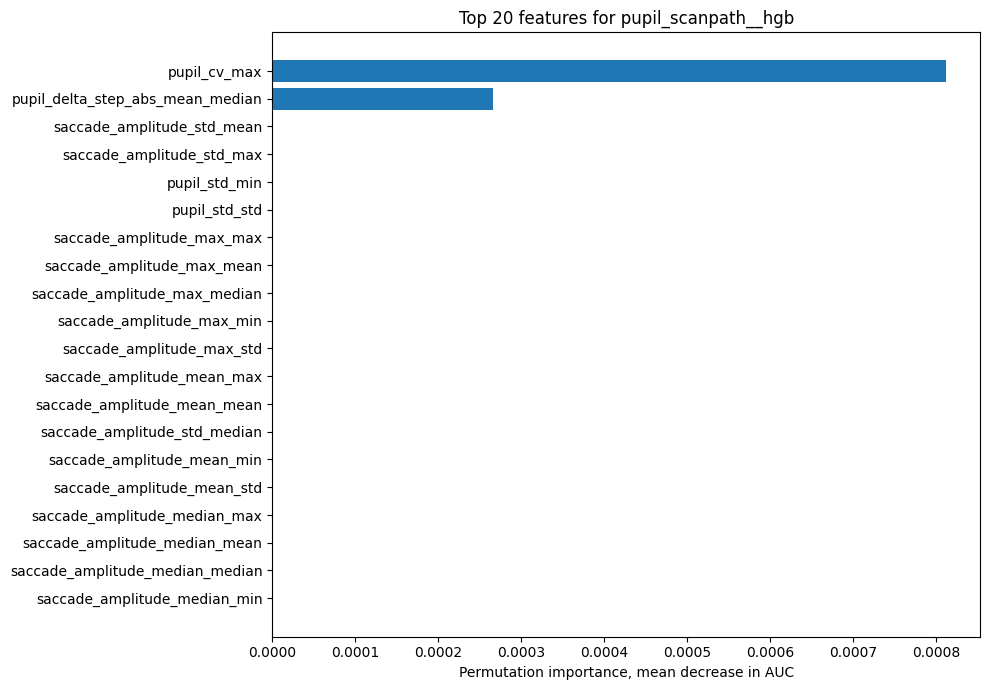


Saved plot to: C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\outputs\improve_behavioral/top_permutation_importance.png


In [18]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance

OUT_DIR = str(PROJECT_ROOT / "outputs" / "improve_behavioral")

subject_path = f"{OUT_DIR}/subject_behavior_features.csv"
feature_sets_path = f"{OUT_DIR}/feature_sets_clean.json"
fusion_metrics_path = f"{OUT_DIR}/fusion_metrics_nested_alpha.csv"

subject_behavior_features = pd.read_csv(subject_path)

with open(feature_sets_path, "r") as f:
    feature_sets = json.load(f)

fusion_metrics_df = pd.read_csv(fusion_metrics_path)

best_fusion_key = fusion_metrics_df.iloc[0]["key"]
best_feature_set, best_model_name = best_fusion_key.split("__")

print("Best fusion key:", best_fusion_key)
print("Best feature set:", best_feature_set)
print("Best behavioral model:", best_model_name)

best_cols = feature_sets[best_feature_set]

print("Number of features used:", len(best_cols))

def make_behavior_model_for_importance(model_name):
    if model_name == "logreg":
        return Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("clf", LogisticRegression(
                max_iter=3000,
                class_weight="balanced",
                solver="liblinear",
                random_state=42
            ))
        ])
    
    if model_name == "rf":
        return Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("clf", RandomForestClassifier(
                n_estimators=500,
                max_depth=None,
                min_samples_leaf=2,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            ))
        ])
    
    if model_name == "hgb":
        return Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("clf", HistGradientBoostingClassifier(
                max_iter=300,
                learning_rate=0.03,
                max_leaf_nodes=15,
                l2_regularization=0.01,
                random_state=42
            ))
        ])
    
    raise ValueError(model_name)

X = subject_behavior_features[best_cols]
y = subject_behavior_features["label"].astype(int)

model = make_behavior_model_for_importance(best_model_name)
model.fit(X, y)

print("Model fitted on full train/valid set for interpretation only.")

perm = permutation_importance(
    model,
    X,
    y,
    scoring="roc_auc",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "feature": best_cols,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
}).sort_values("importance_mean", ascending=False).reset_index(drop=True)

importance_path = f"{OUT_DIR}/permutation_importance_best_behavior.csv"
importance_df.to_csv(importance_path, index=False)

print("\nSaved permutation importance to:", importance_path)

print("\nTop 30 important features:")
display(importance_df.head(30))

top_n = 20
plot_df = importance_df.head(top_n).iloc[::-1]

plt.figure(figsize=(10, 7))
plt.barh(plot_df["feature"], plot_df["importance_mean"])
plt.xlabel("Permutation importance, mean decrease in AUC")
plt.title(f"Top {top_n} features for {best_fusion_key}")
plt.tight_layout()

plot_path = f"{OUT_DIR}/top_permutation_importance.png"
plt.savefig(plot_path, dpi=200)
plt.show()

print("\nSaved plot to:", plot_path)

In [19]:
import os
import json
import numpy as np
import pandas as pd

from sklearn.metrics import roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

OUT_DIR = str(PROJECT_ROOT / "outputs" / "improve_behavioral")

subject_path = f"{OUT_DIR}/subject_behavior_features.csv"
feature_sets_path = f"{OUT_DIR}/feature_sets_clean.json"
fusion_metrics_path = f"{OUT_DIR}/fusion_metrics_nested_alpha.csv"

subject_behavior_features = pd.read_csv(subject_path)

with open(feature_sets_path, "r") as f:
    feature_sets = json.load(f)

fusion_metrics_df = pd.read_csv(fusion_metrics_path)

best_fusion_key = fusion_metrics_df.iloc[0]["key"]
best_feature_set, best_model_name = best_fusion_key.split("__")

print("Best fusion key:", best_fusion_key)
print("Best feature set:", best_feature_set)
print("Best behavioral model:", best_model_name)

best_cols = feature_sets[best_feature_set]

pupil_group = [c for c in best_cols if c.startswith("pupil_")]

scanpath_base_names = [
    "fixation_count",
    "x_mean",
    "y_mean",
    "x_std",
    "y_std",
    "x_dispersion",
    "y_dispersion",
    "xy_dispersion_area",
    "distance_to_center_mean",
    "distance_to_center_std",
    "distance_to_center_max",
    "scanpath_length",
    "saccade_amplitude_mean",
    "saccade_amplitude_std",
    "saccade_amplitude_median",
    "saccade_amplitude_max",
    "num_valid_images",
    "num_total_fixations",
    "mean_fixations_per_image",
]

def belongs_to_base_feature(col, base_names):
    for base in base_names:
        if col == base:
            return True
        if col.startswith(base + "_"):
            return True
    return False

scanpath_group = [
    c for c in best_cols
    if belongs_to_base_feature(c, scanpath_base_names)
]

groups = {
    "pupil_group": pupil_group,
    "scanpath_group": scanpath_group,
    "all_best_behavior_features": best_cols
}

print("\nGroup sizes:")
for g, cols in groups.items():
    print(g, len(cols))

def make_model(model_name):
    if model_name == "hgb":
        return Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("clf", HistGradientBoostingClassifier(
                max_iter=300,
                learning_rate=0.03,
                max_leaf_nodes=15,
                l2_regularization=0.01,
                random_state=42
            ))
        ])
    
    if model_name == "rf":
        return Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("clf", RandomForestClassifier(
                n_estimators=500,
                max_depth=None,
                min_samples_leaf=2,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            ))
        ])
    
    if model_name == "logreg":
        return Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("clf", LogisticRegression(
                max_iter=3000,
                class_weight="balanced",
                solver="liblinear",
                random_state=42
            ))
        ])
    
    raise ValueError(model_name)

X = subject_behavior_features[best_cols].copy()
y = subject_behavior_features["label"].astype(int).values

model = make_model(best_model_name)
model.fit(X, y)

base_prob = model.predict_proba(X)[:, 1]
base_auc = roc_auc_score(y, base_prob)

print("\nBase AUC on full train/valid set for interpretation only:", base_auc)

rng = np.random.default_rng(42)
n_repeats = 30

rows = []

for group_name, group_cols in groups.items():
    drops = []
    
    for r in range(n_repeats):
        X_perm = X.copy()
        
        for col in group_cols:
            X_perm[col] = rng.permutation(X_perm[col].values)
        
        perm_prob = model.predict_proba(X_perm)[:, 1]
        perm_auc = roc_auc_score(y, perm_prob)
        drops.append(base_auc - perm_auc)
    
    rows.append({
        "group": group_name,
        "n_features": len(group_cols),
        "base_auc": base_auc,
        "mean_auc_drop": float(np.mean(drops)),
        "std_auc_drop": float(np.std(drops)),
        "min_auc_drop": float(np.min(drops)),
        "max_auc_drop": float(np.max(drops))
    })

group_importance_df = pd.DataFrame(rows).sort_values("mean_auc_drop", ascending=False).reset_index(drop=True)

group_imp_path = f"{OUT_DIR}/group_permutation_importance.csv"
group_importance_df.to_csv(group_imp_path, index=False)

print("\nGroup-level permutation importance:")
display(group_importance_df)

print("\nSaved group importance to:", group_imp_path)

Best fusion key: pupil_scanpath__hgb
Best feature set: pupil_scanpath
Best behavioral model: hgb

Group sizes:
pupil_group 90
scanpath_group 83
all_best_behavior_features 173

Base AUC on full train/valid set for interpretation only: 1.0

Group-level permutation importance:


,group,n_features,base_auc,mean_auc_drop,std_auc_drop,min_auc_drop,max_auc_drop
0,all_best_behavior_features,173,1.0,0.507312,0.040701,0.430312,0.599844
1,pupil_group,90,1.0,0.150396,0.018465,0.107969,0.188750
2,scanpath_group,83,1.0,0.139703,0.015795,0.099063,0.164844



Saved group importance to: C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\outputs\improve_behavioral/group_permutation_importance.csv


Saved summary to: C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\outputs\improve_behavioral/behavioral_fusion_summary.txt

Behavioral Fusion MSNet - Summary

1. Baseline
Method: MSNet baseline
Acc: 0.83125
Sensitivity: 0.805114
Specificity: 0.870833
AUC: 0.897217
Precision: 0.857516
F1-score: 0.824385

2. Best behavior-only model
Feature set: duration_pupil
Model: logreg
Acc: 0.825
Sensitivity: 0.822443
Specificity: 0.825694
AUC: 0.904153
Precision: 0.826144
F1-score: 0.820931

3. Best fusion model
Method: MSNet + Behavioral Fusion
Feature set: pupil_scanpath
Behavioral model: hgb
Alpha MSNet: 0.8
Behavior weight: 0.2
Acc: 0.84375
Sensitivity: 0.846307
Specificity: 0.836111
AUC: 0.950253
Precision: 0.840322
F1-score: 0.840532

4. Improvement over MSNet baseline
Delta Acc: 0.0125
Delta AUC: 0.053037
Delta F1-score: 0.016147

5. Group-level permutation importance
                     group  n_features  base_auc  mean_auc_drop  std_auc_drop  min_auc_drop  max_auc_drop
all_best_behavio

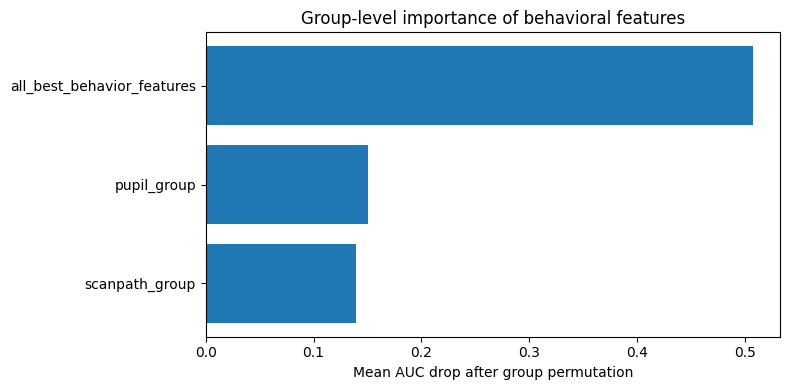

Saved group importance plot to: C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\outputs\improve_behavioral/group_permutation_importance.png


In [20]:
import os
import json
import pandas as pd
import matplotlib.pyplot as plt

OUT_DIR = str(PROJECT_ROOT / "outputs" / "improve_behavioral")

final_comparison_path = f"{OUT_DIR}/final_comparison_metrics_rounded.csv"
fusion_metrics_path = f"{OUT_DIR}/fusion_metrics_nested_alpha.csv"
behavior_metrics_path = f"{OUT_DIR}/behavior_only_metrics.csv"
group_importance_path = f"{OUT_DIR}/group_permutation_importance.csv"
best_alpha_path = f"{OUT_DIR}/best_fusion_alpha_by_fold.csv"
best_fusion_foldwise_path = f"{OUT_DIR}/best_fusion_foldwise_metrics.csv"
baseline_foldwise_path = f"{OUT_DIR}/baseline_msnet_foldwise_metrics.csv"

assert os.path.exists(final_comparison_path), "Missing final_comparison_metrics_rounded.csv"
assert os.path.exists(fusion_metrics_path), "Missing fusion_metrics_nested_alpha.csv"
assert os.path.exists(behavior_metrics_path), "Missing behavior_only_metrics.csv"
assert os.path.exists(group_importance_path), "Missing group_permutation_importance.csv"

final_comparison = pd.read_csv(final_comparison_path)
fusion_metrics = pd.read_csv(fusion_metrics_path)
behavior_metrics = pd.read_csv(behavior_metrics_path)
group_importance = pd.read_csv(group_importance_path)
best_alpha = pd.read_csv(best_alpha_path)
best_fusion_foldwise = pd.read_csv(best_fusion_foldwise_path)
baseline_foldwise = pd.read_csv(baseline_foldwise_path)

baseline = final_comparison[final_comparison["method"] == "MSNet baseline"].iloc[0]
best_behavior = final_comparison[final_comparison["method"] == "Behavior-only"].iloc[0]
best_fusion = final_comparison[final_comparison["method"] == "MSNet + Behavioral Fusion"].iloc[0]

summary_text = f"""
Behavioral Fusion MSNet - Summary

1. Baseline
Method: MSNet baseline
Acc: {baseline["acc"]}
Sensitivity: {baseline["sensitivity"]}
Specificity: {baseline["specificity"]}
AUC: {baseline["auc"]}
Precision: {baseline["precision"]}
F1-score: {baseline["f1_score"]}

2. Best behavior-only model
Feature set: {best_behavior["feature_set"]}
Model: {best_behavior["model"]}
Acc: {best_behavior["acc"]}
Sensitivity: {best_behavior["sensitivity"]}
Specificity: {best_behavior["specificity"]}
AUC: {best_behavior["auc"]}
Precision: {best_behavior["precision"]}
F1-score: {best_behavior["f1_score"]}

3. Best fusion model
Method: MSNet + Behavioral Fusion
Feature set: {best_fusion["feature_set"]}
Behavioral model: {best_fusion["model"]}
Alpha MSNet: {best_fusion["alpha_msnet"]}
Behavior weight: {best_fusion["behavior_weight"]}
Acc: {best_fusion["acc"]}
Sensitivity: {best_fusion["sensitivity"]}
Specificity: {best_fusion["specificity"]}
AUC: {best_fusion["auc"]}
Precision: {best_fusion["precision"]}
F1-score: {best_fusion["f1_score"]}

4. Improvement over MSNet baseline
Delta Acc: {best_fusion["delta_acc_vs_baseline"]}
Delta AUC: {best_fusion["delta_auc_vs_baseline"]}
Delta F1-score: {best_fusion["delta_f1_vs_baseline"]}

5. Group-level permutation importance
{group_importance.to_string(index=False)}

6. Interpretation note
The best fusion model combines official MSNet probability with behavioral probability from pupil and scanpath features.
The selected average fusion weight is 0.8 for MSNet and 0.2 for behavioral features.
This suggests that MSNet remains the main predictor, while pupil dynamics and scanpath statistics provide complementary information not directly exploited by the original MSNet pipeline.
The full-dataset permutation importance is used only for interpretation, not as the main validation result.
"""

summary_path = f"{OUT_DIR}/behavioral_fusion_summary.txt"
with open(summary_path, "w", encoding="utf-8") as f:
    f.write(summary_text)

print("Saved summary to:", summary_path)
print(summary_text)

plot_df = group_importance.copy()
plot_df = plot_df.sort_values("mean_auc_drop", ascending=True)

plt.figure(figsize=(8, 4))
plt.barh(plot_df["group"], plot_df["mean_auc_drop"])
plt.xlabel("Mean AUC drop after group permutation")
plt.title("Group-level importance of behavioral features")
plt.tight_layout()

group_plot_path = f"{OUT_DIR}/group_permutation_importance.png"
plt.savefig(group_plot_path, dpi=200)
plt.show()

print("Saved group importance plot to:", group_plot_path)

## 10. Data completeness and UMAP visualization

Create data completeness summaries and UMAP visualizations for the improved behavioral feature spaces.

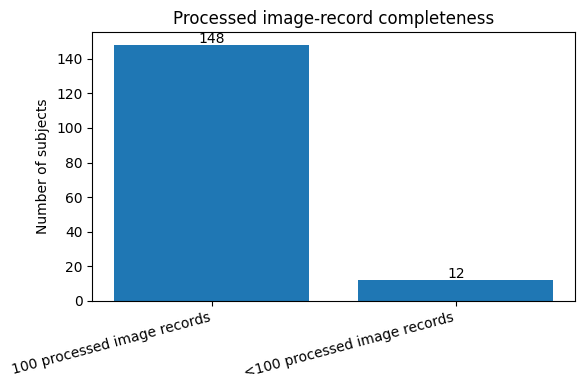

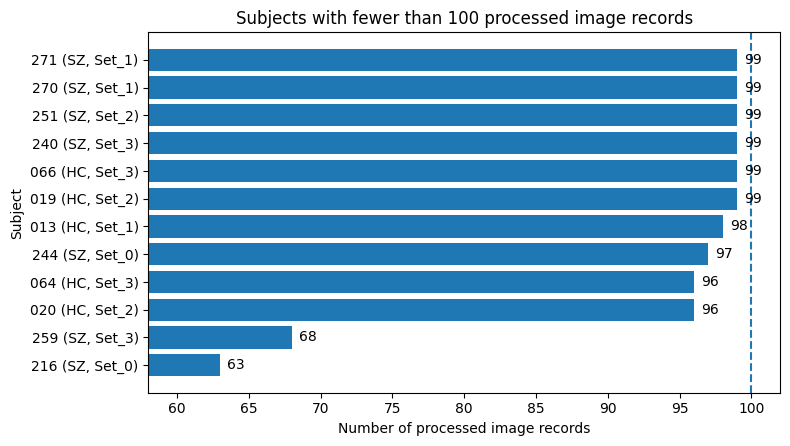

Processed subject completeness summary:


,item,value
0,Total subjects,160.00
1,Subjects with 100 processed image records,148.00
2,Subjects with fewer than 100 processed image r...,12.00
3,Minimum processed image records,63.00
4,Mean processed image records,99.45
5,Median processed image records,100.00



Subject(s) with minimum processed image records:


,subject_id,set_name,label,class_name,num_valid_images,num_total_fixations,mean_fixations_per_image
0,216,Set_0,1,SZ,63,740,11.746032



Subjects with fewer than 100 processed image records:


,subject_id,set_name,label,class_name,num_valid_images,num_total_fixations,mean_fixations_per_image
0,216,Set_0,1,SZ,63,740,11.746032
1,259,Set_3,1,SZ,68,1006,14.794118
2,020,Set_2,0,HC,96,1541,16.052083
3,064,Set_3,0,HC,96,1429,14.885417
4,244,Set_0,1,SZ,97,1241,12.793814
5,013,Set_1,0,HC,98,1217,12.418367
6,019,Set_2,0,HC,99,1152,11.636364
7,066,Set_3,0,HC,99,1294,13.070707
8,240,Set_3,1,SZ,99,1402,14.161616
9,251,Set_2,1,SZ,99,914,9.232323



Saved files:
C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\outputs\improve_behavioral/report_outputs/processed_subject_completeness_summary.csv
C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\outputs\improve_behavioral/report_outputs/processed_subjects_incomplete_images.csv
C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\outputs\improve_behavioral/report_outputs/processed_min_valid_image_subjects.csv
C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\outputs\improve_behavioral/report_outputs/data_completeness_note.txt

Saved figures:
C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\outputs\improve_behavioral/report_outputs/processed_full_vs_incomplete.png
C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\outputs\improve_behavioral/report_outputs/processed_incomplete_subjects_barplot.png

Report wording note:
Data completeness note

The proposed behavioral model was trained using the processed subject-level feature table.
Therefore, the main completeness statistic reporte

In [21]:
import os
import pandas as pd
import matplotlib.pyplot as plt

OUT_DIR = str(PROJECT_ROOT / "outputs" / "improve_behavioral")
REPORT_DIR = f"{OUT_DIR}/report_outputs"
os.makedirs(REPORT_DIR, exist_ok=True)

subject_feature_path = f"{OUT_DIR}/subject_behavior_features.csv"
assert os.path.exists(subject_feature_path), f"Missing: {subject_feature_path}"

subject_df = pd.read_csv(subject_feature_path)

subject_df["subject_id"] = (
    subject_df["subject_id"]
    .astype(str)
    .str.extract(r"(\d+)", expand=False)
    .astype(int)
    .map(lambda x: f"{x:03d}")
)

subject_df["class_name"] = subject_df["label"].map({0: "HC", 1: "SZ"})

processed_df = subject_df[
    [
        "subject_id",
        "set_name",
        "label",
        "class_name",
        "num_valid_images",
        "num_total_fixations",
        "mean_fixations_per_image",
    ]
].copy()

processed_df = processed_df.sort_values(["num_valid_images", "subject_id"]).reset_index(drop=True)

full_processed = processed_df[processed_df["num_valid_images"] == 100].copy()
incomplete_processed = processed_df[processed_df["num_valid_images"] < 100].copy()

summary = pd.DataFrame([
    {"item": "Total subjects", "value": len(processed_df)},
    {"item": "Subjects with 100 processed image records", "value": len(full_processed)},
    {"item": "Subjects with fewer than 100 processed image records", "value": len(incomplete_processed)},
    {"item": "Minimum processed image records", "value": int(processed_df["num_valid_images"].min())},
    {"item": "Mean processed image records", "value": round(float(processed_df["num_valid_images"].mean()), 4)},
    {"item": "Median processed image records", "value": round(float(processed_df["num_valid_images"].median()), 4)},
])

min_subjects = processed_df[
    processed_df["num_valid_images"] == processed_df["num_valid_images"].min()
].copy()

summary_path = f"{REPORT_DIR}/processed_subject_completeness_summary.csv"
incomplete_path = f"{REPORT_DIR}/processed_subjects_incomplete_images.csv"
min_subjects_path = f"{REPORT_DIR}/processed_min_valid_image_subjects.csv"

summary.to_csv(summary_path, index=False)
incomplete_processed.to_csv(incomplete_path, index=False)
min_subjects.to_csv(min_subjects_path, index=False)

counts_df = pd.DataFrame([
    {"group": "100 processed image records", "n_subjects": len(full_processed)},
    {"group": "<100 processed image records", "n_subjects": len(incomplete_processed)},
])

plt.figure(figsize=(6, 4))
plt.bar(counts_df["group"], counts_df["n_subjects"])
plt.ylabel("Number of subjects")
plt.title("Processed image-record completeness")
plt.xticks(rotation=15, ha="right")

for i, v in enumerate(counts_df["n_subjects"]):
    plt.text(i, v + 1, str(v), ha="center")

plt.tight_layout()
processed_full_vs_incomplete_plot = f"{REPORT_DIR}/processed_full_vs_incomplete.png"
plt.savefig(processed_full_vs_incomplete_plot, dpi=200)
plt.show()

plot_df = incomplete_processed.sort_values("num_valid_images", ascending=True).copy()

if len(plot_df) > 0:
    y_labels = (
        plot_df["subject_id"]
        + " ("
        + plot_df["class_name"]
        + ", "
        + plot_df["set_name"]
        + ")"
    )
    
    plt.figure(figsize=(8, max(4, len(plot_df) * 0.38)))
    plt.barh(y_labels, plot_df["num_valid_images"])
    plt.axvline(100, linestyle="--")
    plt.xlabel("Number of processed image records")
    plt.ylabel("Subject")
    plt.title("Subjects with fewer than 100 processed image records")
    plt.xlim(max(0, plot_df["num_valid_images"].min() - 5), 102)
    
    for i, v in enumerate(plot_df["num_valid_images"]):
        plt.text(v + 0.5, i, str(v), va="center")
    
    plt.tight_layout()
    incomplete_plot = f"{REPORT_DIR}/processed_incomplete_subjects_barplot.png"
    plt.savefig(incomplete_plot, dpi=200)
    plt.show()
else:
    incomplete_plot = None
    print("No incomplete processed subjects found.")

note = """Data completeness note

The proposed behavioral model was trained using the processed subject-level feature table.
Therefore, the main completeness statistic reported in the paper should be based on num_valid_images in subject_behavior_features.csv.

In this processed feature table:
- 148 out of 160 subjects have behavioral records for all 100 stimulus images.
- 12 out of 160 subjects have fewer than 100 processed image records.
- The most incomplete case is subject 216, an SZ subject in Set_0, with 63 processed image records.

A separate raw Excel audit was performed only for data-quality verification. It confirmed that subject 216 has only 63 unique image records in the public raw fixation file. This should be described as incomplete public fixation/image records, not as proof that the subject did not view the missing stimuli.
"""

note_path = f"{REPORT_DIR}/data_completeness_note.txt"
with open(note_path, "w", encoding="utf-8") as f:
    f.write(note)

print("Processed subject completeness summary:")
display(summary)

print("\nSubject(s) with minimum processed image records:")
display(min_subjects)

print("\nSubjects with fewer than 100 processed image records:")
display(incomplete_processed)

print("\nSaved files:")
print(summary_path)
print(incomplete_path)
print(min_subjects_path)
print(note_path)

print("\nSaved figures:")
print(processed_full_vs_incomplete_plot)
if incomplete_plot is not None:
    print(incomplete_plot)

print("\nReport wording note:")
print(note)

c:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Feature groups for UMAP:
duration_only: 60 features
pupil_only: 90 features
scanpath_only: 83 features
duration_pupil: 150 features
duration_scanpath: 143 features
pupil_scanpath: 173 features
all_behavior: 233 features

Running UMAP for: duration_only


c:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


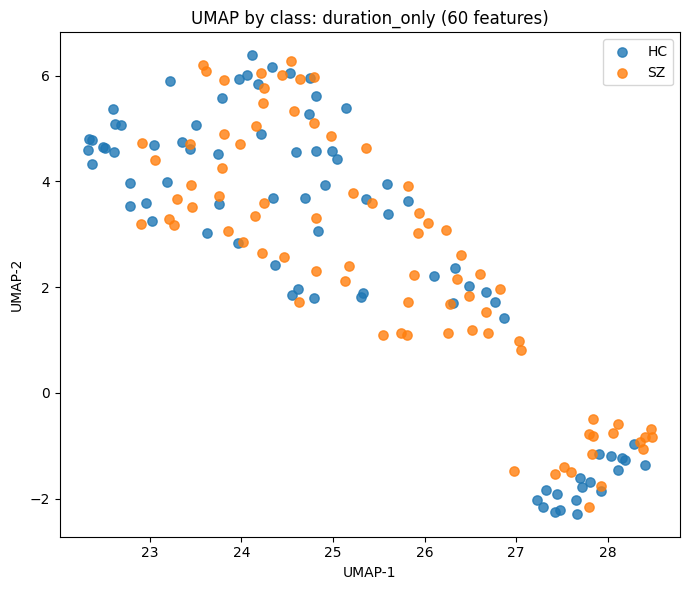


Running UMAP for: pupil_only


c:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


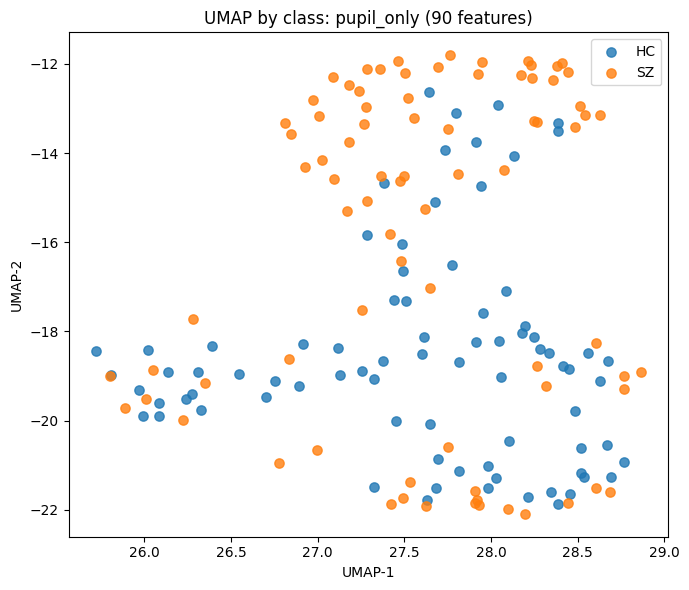


Running UMAP for: scanpath_only


c:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


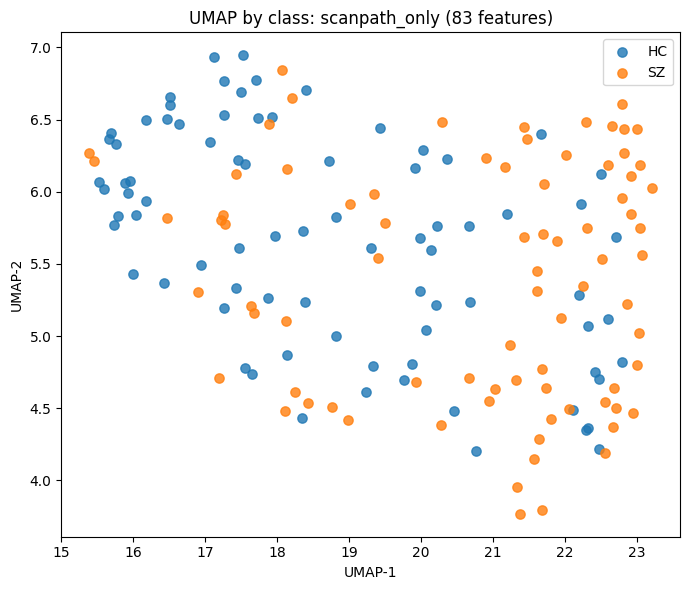


Running UMAP for: duration_pupil


c:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


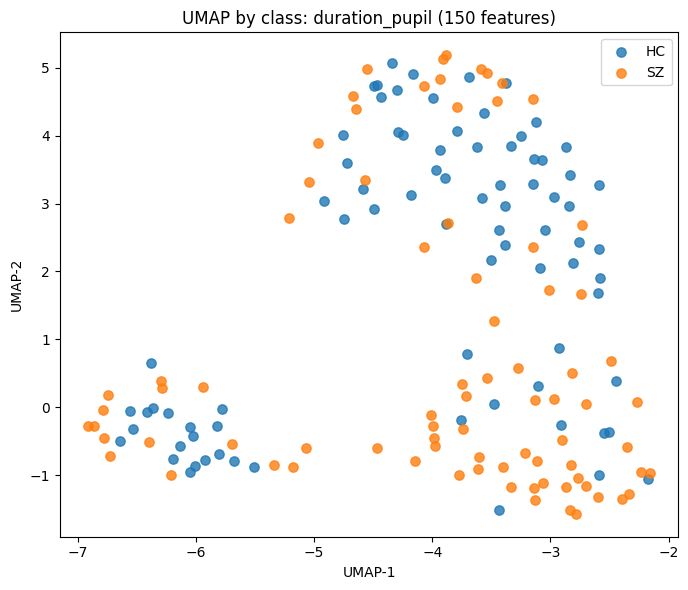


Running UMAP for: duration_scanpath


c:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


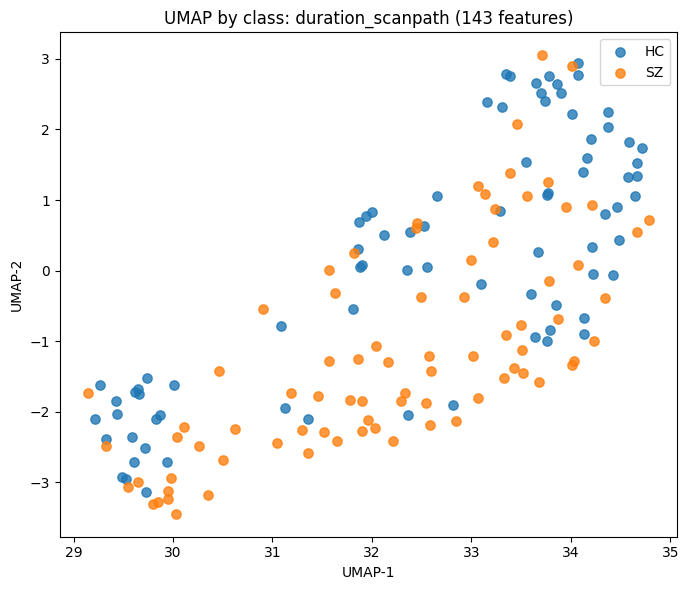


Running UMAP for: pupil_scanpath


c:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


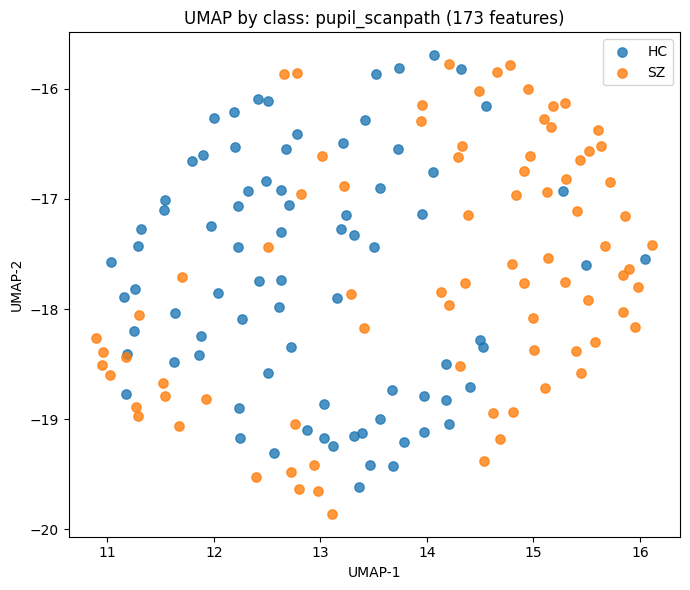


Running UMAP for: all_behavior


c:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


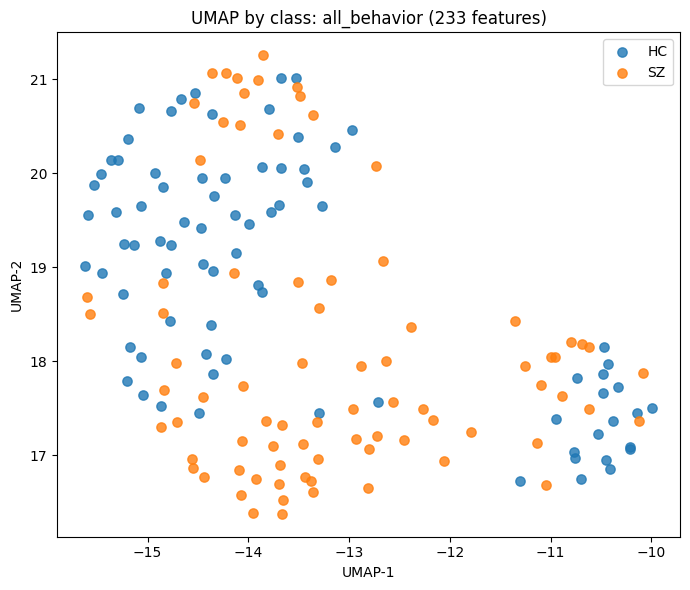

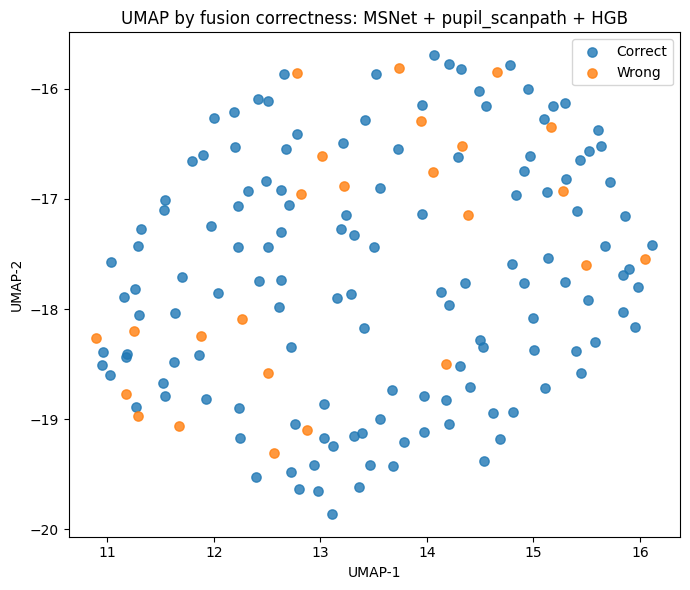


Saved UMAP embeddings:
C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\outputs\improve_behavioral/report_outputs/umap_all_feature_groups_embedding_clean.csv

Saved UMAP label plots:
C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\outputs\improve_behavioral/report_outputs/umap_duration_only_by_label_clean.png
C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\outputs\improve_behavioral/report_outputs/umap_pupil_only_by_label_clean.png
C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\outputs\improve_behavioral/report_outputs/umap_scanpath_only_by_label_clean.png
C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\outputs\improve_behavioral/report_outputs/umap_duration_pupil_by_label_clean.png
C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\outputs\improve_behavioral/report_outputs/umap_duration_scanpath_by_label_clean.png
C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\outputs\improve_behavioral/report_outputs/umap_pupil_scanpath_by_label_clean.png
C:\Users\hweem\Documents\

,count,count
0,HC,80
1,SZ,80



Fusion correctness counts:


,count,count
0,Correct,135
1,Wrong,25



Final-method UMAP table preview:


,subject_id,subject_int,set_name,label,class_name,num_valid_images,num_total_fixations,mean_fixations_per_image,feature_group,n_features,umap_1,umap_2,fused_prob,threshold,fusion_pred,fusion_correct,fusion_status
0,000,0,Set_1,0,HC,100,1550,15.50,pupil_scanpath,173,12.200718,-16.525587,0.139217,0.478431,0,True,Correct
1,001,1,Set_1,0,HC,100,1225,12.25,pupil_scanpath,173,13.210785,-16.495333,0.447548,0.478431,0,True,Correct
2,002,2,Set_0,0,HC,100,1532,15.32,pupil_scanpath,173,14.063152,-15.695247,0.294077,0.435294,0,True,Correct
3,003,3,Set_1,0,HC,100,1605,16.05,pupil_scanpath,173,12.780845,-16.408554,0.137834,0.478431,0,True,Correct
4,004,4,Set_1,0,HC,100,1296,12.96,pupil_scanpath,173,13.780784,-19.208601,0.151229,0.478431,0,True,Correct


In [22]:
import os
import json
import subprocess
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

try:
    import umap
except ImportError:
    print("Installing umap-learn if missing...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "umap-learn"])
    import umap

OUT_DIR = str(PROJECT_ROOT / "outputs" / "improve_behavioral")
REPORT_DIR = f"{OUT_DIR}/report_outputs"
os.makedirs(REPORT_DIR, exist_ok=True)

subject_path = f"{OUT_DIR}/subject_behavior_features.csv"
feature_sets_path = f"{OUT_DIR}/feature_sets_clean.json"
best_fusion_pred_path = f"{OUT_DIR}/best_fusion_prob_val.csv"
best_fusion_foldwise_path = f"{OUT_DIR}/best_fusion_foldwise_metrics.csv"

assert os.path.exists(subject_path), f"Missing: {subject_path}"
assert os.path.exists(feature_sets_path), f"Missing: {feature_sets_path}"

subject_df = pd.read_csv(subject_path)

with open(feature_sets_path, "r") as f:
    feature_sets = json.load(f)

subject_df["subject_id"] = (
    subject_df["subject_id"]
    .astype(str)
    .str.extract(r"(\d+)", expand=False)
    .astype(int)
    .map(lambda x: f"{x:03d}")
)

subject_df["class_name"] = subject_df["label"].map({0: "HC", 1: "SZ"})

feature_group_order = [
    "duration_only",
    "pupil_only",
    "scanpath_only",
    "duration_pupil",
    "duration_scanpath",
    "pupil_scanpath",
    "all_behavior",
]

feature_group_order = [g for g in feature_group_order if g in feature_sets]

print("Feature groups for UMAP:")
for g in feature_group_order:
    print(f"{g}: {len(feature_sets[g])} features")

has_fusion_pred = os.path.exists(best_fusion_pred_path) and os.path.exists(best_fusion_foldwise_path)

if has_fusion_pred:
    fusion_df = pd.read_csv(best_fusion_pred_path)
    fold_metrics = pd.read_csv(best_fusion_foldwise_path)
    
    fusion_df["subject_id"] = (
        fusion_df["subject_id"]
        .astype(str)
        .str.extract(r"(\d+)", expand=False)
        .astype(int)
        .map(lambda x: f"{x:03d}")
    )
    
    if "fused_prob" in fusion_df.columns:
        prob_col = "fused_prob"
    elif "prob" in fusion_df.columns:
        prob_col = "prob"
    elif "pred_prob" in fusion_df.columns:
        prob_col = "pred_prob"
    else:
        prob_candidates = [c for c in fusion_df.columns if "prob" in c.lower()]
        assert len(prob_candidates) > 0, f"Cannot find probability column in {fusion_df.columns.tolist()}"
        prob_col = prob_candidates[0]
    
    threshold_map = (
        fold_metrics[fold_metrics["set_name"] != "average"]
        .set_index("set_name")["threshold"]
        .to_dict()
    )
    
    fusion_df["threshold"] = fusion_df["set_name"].map(threshold_map)
    fusion_df["fusion_pred"] = (fusion_df[prob_col] >= fusion_df["threshold"]).astype(int)
    fusion_df["fusion_correct"] = fusion_df["fusion_pred"] == fusion_df["label"].astype(int)
    fusion_df["fusion_status"] = fusion_df["fusion_correct"].map({True: "Correct", False: "Wrong"})
    
    fusion_keep = fusion_df[
        ["subject_id", prob_col, "threshold", "fusion_pred", "fusion_correct", "fusion_status"]
    ].copy()
    fusion_keep = fusion_keep.rename(columns={prob_col: "fused_prob"})
else:
    fusion_keep = None
    print("Warning: best fusion prediction files not found. Correct/Wrong UMAP will be skipped.")

def run_umap_for_group(group_name, feature_cols):
    X = subject_df[feature_cols].copy()
    
    imputer = SimpleImputer(strategy="median")
    scaler = StandardScaler()
    
    X_imp = imputer.fit_transform(X)
    X_scaled = scaler.fit_transform(X_imp)
    
    reducer = umap.UMAP(
        n_neighbors=15,
        min_dist=0.1,
        n_components=2,
        metric="euclidean",
        random_state=42
    )
    
    emb = reducer.fit_transform(X_scaled)
    
    out_df = subject_df[
        [
            "subject_id",
            "subject_int",
            "set_name",
            "label",
            "class_name",
            "num_valid_images",
            "num_total_fixations",
            "mean_fixations_per_image",
        ]
    ].copy()
    
    out_df["feature_group"] = group_name
    out_df["n_features"] = len(feature_cols)
    out_df["umap_1"] = emb[:, 0]
    out_df["umap_2"] = emb[:, 1]
    
    return out_df

all_umap_rows = []
plot_paths = []

for group_name in feature_group_order:
    print("\nRunning UMAP for:", group_name)
    
    group_df = run_umap_for_group(group_name, feature_sets[group_name])
    all_umap_rows.append(group_df)
    
    group_csv_path = f"{REPORT_DIR}/umap_{group_name}_embedding.csv"
    group_df.to_csv(group_csv_path, index=False)
    
    plt.figure(figsize=(7, 6))
    
    for class_name in ["HC", "SZ"]:
        sub = group_df[group_df["class_name"] == class_name]
        plt.scatter(
            sub["umap_1"],
            sub["umap_2"],
            label=class_name,
            alpha=0.8,
            s=45
        )
    
    plt.xlabel("UMAP-1")
    plt.ylabel("UMAP-2")
    plt.title(f"UMAP by class: {group_name} ({len(feature_sets[group_name])} features)")
    plt.legend()
    plt.tight_layout()
    
    plot_path = f"{REPORT_DIR}/umap_{group_name}_by_label_clean.png"
    plt.savefig(plot_path, dpi=220)
    plt.show()
    
    plot_paths.append(plot_path)

all_umap_df = pd.concat(all_umap_rows, ignore_index=True)
all_umap_path = f"{REPORT_DIR}/umap_all_feature_groups_embedding_clean.csv"
all_umap_df.to_csv(all_umap_path, index=False)

correctness_plot_path = None
final_umap_df = None

if has_fusion_pred and "pupil_scanpath" in feature_group_order:
    final_umap_df = all_umap_df[all_umap_df["feature_group"] == "pupil_scanpath"].copy()
    final_umap_df = final_umap_df.merge(fusion_keep, on="subject_id", how="left")
    
    final_umap_correctness_path = f"{REPORT_DIR}/umap_pupil_scanpath_with_fusion_correctness_clean.csv"
    final_umap_df.to_csv(final_umap_correctness_path, index=False)
    
    plt.figure(figsize=(7, 6))
    
    for status in ["Correct", "Wrong"]:
        sub = final_umap_df[final_umap_df["fusion_status"] == status]
        plt.scatter(
            sub["umap_1"],
            sub["umap_2"],
            label=status,
            alpha=0.8,
            s=45
        )
    
    plt.xlabel("UMAP-1")
    plt.ylabel("UMAP-2")
    plt.title("UMAP by fusion correctness: MSNet + pupil_scanpath + HGB")
    plt.legend()
    plt.tight_layout()
    
    correctness_plot_path = f"{REPORT_DIR}/umap_pupil_scanpath_by_fusion_correctness_clean.png"
    plt.savefig(correctness_plot_path, dpi=220)
    plt.show()

print("\nSaved UMAP embeddings:")
print(all_umap_path)

print("\nSaved UMAP label plots:")
for p in plot_paths:
    print(p)

if correctness_plot_path is not None:
    print("\nSaved final-method Correct/Wrong UMAP:")
    print(correctness_plot_path)

print("\nLabel counts:")
display(
    subject_df["class_name"]
    .value_counts()
    .reset_index()
    .rename(columns={"index": "class_name", "class_name": "count"})
)

if final_umap_df is not None:
    print("\nFusion correctness counts:")
    display(
        final_umap_df["fusion_status"]
        .value_counts()
        .reset_index()
        .rename(columns={"index": "fusion_status", "fusion_status": "count"})
    )

    print("\nFinal-method UMAP table preview:")
    display(final_umap_df.head())

## 11. Alpha analysis and local XAI

Explain the selected alpha and run LIME for selected subject-level cases.

Original alpha file:


,val_set,chosen_alpha_msnet,chosen_behavior_weight,alpha_search_best_auc,alpha_search_best_f1,alpha_search_best_acc
0,Set_0,0.8,0.2,0.940405,0.829042,0.841667
1,Set_1,0.8,0.2,0.960581,0.858083,0.850000
2,Set_2,0.8,0.2,0.947838,0.840007,0.841667
3,Set_3,0.8,0.2,0.952190,0.834995,0.841667



Alpha map used by final fusion:
{'Set_0': 0.8, 'Set_1': 0.8, 'Set_2': 0.8, 'Set_3': 0.8}


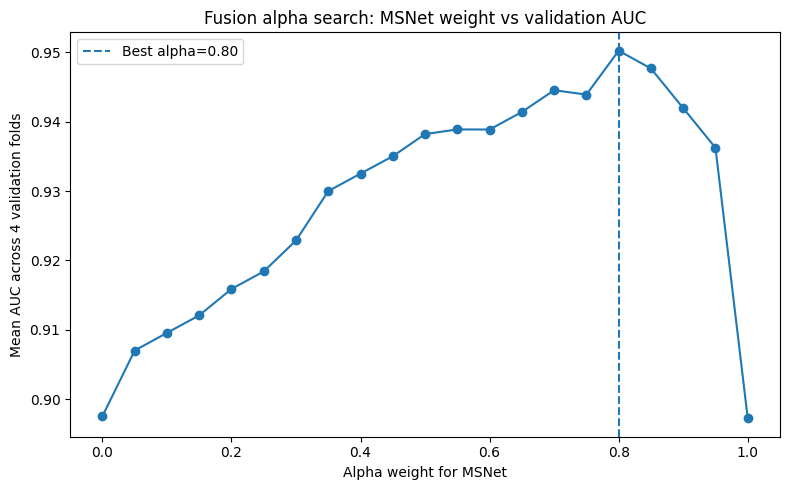


Recovered behavior_prob sanity check:


,subject_id,set_name,label,msnet_prob,behavior_prob_recovered,fused_prob,alpha_used
0,002,Set_0,0,0.347886,0.078841,0.294077,0.8
1,008,Set_0,0,0.349875,0.402358,0.360371,0.8
2,011,Set_0,0,0.350794,0.016516,0.283938,0.8
3,028,Set_0,0,0.350816,0.860524,0.452757,0.8
4,035,Set_0,0,0.360552,0.847989,0.458039,0.8



Average AUC by alpha:


,alpha_msnet,behavior_weight,set_name,auc
84,0.80,0.20,average,0.950253
89,0.85,0.15,average,0.947689
74,0.70,0.30,average,0.944552
79,0.75,0.25,average,0.943920
94,0.90,0.10,average,0.941974
69,0.65,0.35,average,0.941415
59,0.55,0.45,average,0.938897
64,0.60,0.40,average,0.938883
54,0.50,0.50,average,0.938228
99,0.95,0.05,average,0.936245



Nested alpha selection by validation fold:


,val_set,chosen_alpha_msnet,chosen_behavior_weight,train_folds_best_mean_auc
0,Set_0,0.8,0.2,0.940405
1,Set_1,0.8,0.2,0.960581
2,Set_2,0.8,0.2,0.947838
3,Set_3,0.8,0.2,0.952190



Saved files:
C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\outputs\improve_behavioral/report_outputs/alpha_grid_auc_curve.csv
C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\outputs\improve_behavioral/report_outputs/alpha_nested_selection_explanation.csv
C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\outputs\improve_behavioral/report_outputs/alpha_grid_auc_curve.png


In [23]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

OUT_DIR = str(PROJECT_ROOT / "outputs" / "improve_behavioral")
REPORT_DIR = f"{OUT_DIR}/report_outputs"
os.makedirs(REPORT_DIR, exist_ok=True)

best_fusion_pred_path = f"{OUT_DIR}/best_fusion_prob_val.csv"
best_fusion_alpha_path = f"{OUT_DIR}/best_fusion_alpha_by_fold.csv"
msnet_prob_path = f"{OUT_DIR}/msnet_prob_val.csv"

assert os.path.exists(best_fusion_pred_path), f"Missing: {best_fusion_pred_path}"
assert os.path.exists(msnet_prob_path), f"Missing: {msnet_prob_path}"

fusion_df = pd.read_csv(best_fusion_pred_path)
msnet_df = pd.read_csv(msnet_prob_path)

for df in [fusion_df, msnet_df]:
    df["subject_id"] = (
        df["subject_id"]
        .astype(str)
        .str.extract(r"(\d+)", expand=False)
        .astype(int)
        .map(lambda x: f"{x:03d}")
    )

if "fused_prob" in fusion_df.columns:
    fused_prob_col = "fused_prob"
else:
    candidates = [c for c in fusion_df.columns if "fused" in c.lower() and "prob" in c.lower()]
    if len(candidates) == 0:
        candidates = [c for c in fusion_df.columns if "prob" in c.lower()]
    assert len(candidates) > 0, f"Cannot find fused probability column: {fusion_df.columns.tolist()}"
    fused_prob_col = candidates[0]

if "msnet_prob" in msnet_df.columns:
    msnet_prob_col = "msnet_prob"
else:
    candidates = [c for c in msnet_df.columns if "prob" in c.lower()]
    assert len(candidates) > 0, f"Cannot find MSNet probability column: {msnet_df.columns.tolist()}"
    msnet_prob_col = candidates[0]

df = fusion_df[["subject_id", "set_name", "label", fused_prob_col]].merge(
    msnet_df[["subject_id", msnet_prob_col]],
    on="subject_id",
    how="left"
)

df = df.rename(columns={
    fused_prob_col: "fused_prob",
    msnet_prob_col: "msnet_prob"
})

assert df["msnet_prob"].notna().all(), "Some subjects have missing msnet_prob after merge."

if os.path.exists(best_fusion_alpha_path):
    alpha_df = pd.read_csv(best_fusion_alpha_path)
    print("Original alpha file:")
    display(alpha_df)
    
    if "chosen_alpha_msnet" in alpha_df.columns:
        alpha_col = "chosen_alpha_msnet"
    elif "alpha_msnet" in alpha_df.columns:
        alpha_col = "alpha_msnet"
    else:
        alpha_candidates = [c for c in alpha_df.columns if "alpha" in c.lower()]
        assert len(alpha_candidates) > 0, f"Cannot find alpha column: {alpha_df.columns.tolist()}"
        alpha_col = alpha_candidates[0]
    
    fold_col = "val_set" if "val_set" in alpha_df.columns else "set_name"
    alpha_map = alpha_df.set_index(fold_col)[alpha_col].to_dict()
else:
    alpha_map = {s: 0.8 for s in ["Set_0", "Set_1", "Set_2", "Set_3"]}

print("\nAlpha map used by final fusion:")
print(alpha_map)

df["alpha_used"] = df["set_name"].map(alpha_map).fillna(0.8)
df["behavior_weight_used"] = 1.0 - df["alpha_used"]

df["behavior_prob_recovered"] = (
    df["fused_prob"] - df["alpha_used"] * df["msnet_prob"]
) / df["behavior_weight_used"]

df["behavior_prob_recovered"] = df["behavior_prob_recovered"].clip(0, 1)

alpha_values = np.round(np.arange(0.0, 1.0001, 0.05), 2)

curve_rows = []

for alpha in alpha_values:
    tmp = df.copy()
    tmp["candidate_fused_prob"] = (
        alpha * tmp["msnet_prob"]
        + (1.0 - alpha) * tmp["behavior_prob_recovered"]
    )
    
    fold_aucs = []
    for set_name, g in tmp.groupby("set_name"):
        if g["label"].nunique() == 2:
            auc = roc_auc_score(g["label"], g["candidate_fused_prob"])
            fold_aucs.append(auc)
            curve_rows.append({
                "alpha_msnet": alpha,
                "behavior_weight": 1.0 - alpha,
                "set_name": set_name,
                "auc": auc,
            })
    
    curve_rows.append({
        "alpha_msnet": alpha,
        "behavior_weight": 1.0 - alpha,
        "set_name": "average",
        "auc": float(np.mean(fold_aucs)),
    })

curve_df = pd.DataFrame(curve_rows)

avg_curve = curve_df[curve_df["set_name"] == "average"].copy()
best_row = avg_curve.sort_values("auc", ascending=False).iloc[0]

nested_rows = []

for val_set in ["Set_0", "Set_1", "Set_2", "Set_3"]:
    train_like = df[df["set_name"] != val_set].copy()
    
    rows = []
    for alpha in alpha_values:
        tmp = train_like.copy()
        tmp["candidate_fused_prob"] = (
            alpha * tmp["msnet_prob"]
            + (1.0 - alpha) * tmp["behavior_prob_recovered"]
        )
        
        fold_aucs = []
        for train_fold_name, g in tmp.groupby("set_name"):
            auc = roc_auc_score(g["label"], g["candidate_fused_prob"])
            fold_aucs.append(auc)
        
        rows.append({
            "val_set": val_set,
            "alpha_msnet": alpha,
            "behavior_weight": 1.0 - alpha,
            "train_folds_mean_auc": float(np.mean(fold_aucs)),
        })
    
    rows_df = pd.DataFrame(rows)
    chosen = rows_df.sort_values("train_folds_mean_auc", ascending=False).iloc[0]
    
    nested_rows.append({
        "val_set": val_set,
        "chosen_alpha_msnet": chosen["alpha_msnet"],
        "chosen_behavior_weight": chosen["behavior_weight"],
        "train_folds_best_mean_auc": chosen["train_folds_mean_auc"],
    })

nested_df = pd.DataFrame(nested_rows)

curve_path = f"{REPORT_DIR}/alpha_grid_auc_curve.csv"
nested_path = f"{REPORT_DIR}/alpha_nested_selection_explanation.csv"
curve_df.to_csv(curve_path, index=False)
nested_df.to_csv(nested_path, index=False)

plt.figure(figsize=(8, 5))
plt.plot(avg_curve["alpha_msnet"], avg_curve["auc"], marker="o")
plt.axvline(float(best_row["alpha_msnet"]), linestyle="--", label=f"Best alpha={best_row['alpha_msnet']:.2f}")
plt.xlabel("Alpha weight for MSNet")
plt.ylabel("Mean AUC across 4 validation folds")
plt.title("Fusion alpha search: MSNet weight vs validation AUC")
plt.legend()
plt.tight_layout()

alpha_plot_path = f"{REPORT_DIR}/alpha_grid_auc_curve.png"
plt.savefig(alpha_plot_path, dpi=220)
plt.show()

print("\nRecovered behavior_prob sanity check:")
display(df[["subject_id", "set_name", "label", "msnet_prob", "behavior_prob_recovered", "fused_prob", "alpha_used"]].head())

print("\nAverage AUC by alpha:")
display(avg_curve.sort_values("auc", ascending=False).head(10))

print("\nNested alpha selection by validation fold:")
display(nested_df)

print("\nSaved files:")
print(curve_path)
print(nested_path)
print(alpha_plot_path)

Final fusion black-box:
Input = msnet_prob + 173 pupil_scanpath features
Output = fused probability for SZ
Alpha map: {'Set_0': 0.8, 'Set_1': 0.8, 'Set_2': 0.8, 'Set_3': 0.8}

Selected XAI cases:


,case_type,subject_id,set_name,class_name,label,num_valid_images,msnet_prob,msnet_threshold,msnet_pred,msnet_correct,fused_prob,fusion_threshold,fusion_pred,fusion_correct,fusion_status,fusion_margin
0,subject_216_incomplete_records,216,Set_0,SZ,1,63,0.572243,0.423529,1,True,0.656633,0.435294,1,True,Correct,0.221339
1,msnet_wrong_fusion_correct,021,Set_1,HC,0,100,0.342940,0.341176,1,False,0.282330,0.478431,0,True,Correct,0.196102
2,fusion_wrong_high_confidence,013,Set_1,HC,0,98,0.829764,0.341176,1,False,0.863368,0.478431,1,False,Wrong,0.384936
3,fusion_correct_high_confidence,248,Set_2,SZ,1,100,0.937735,0.270588,1,True,0.947797,0.415686,1,True,Correct,0.532111


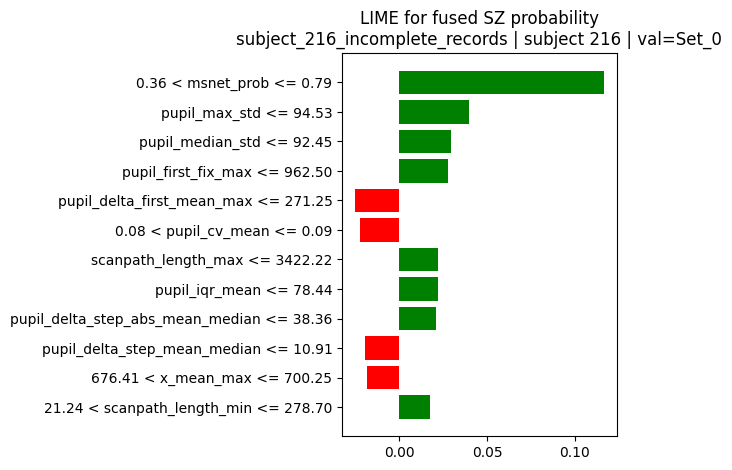

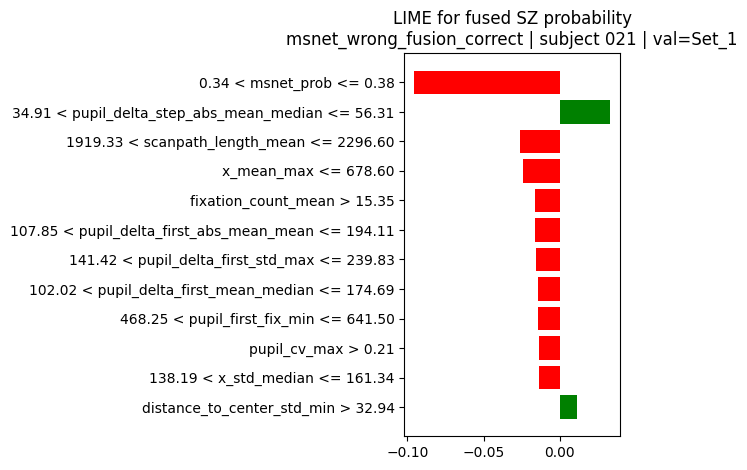

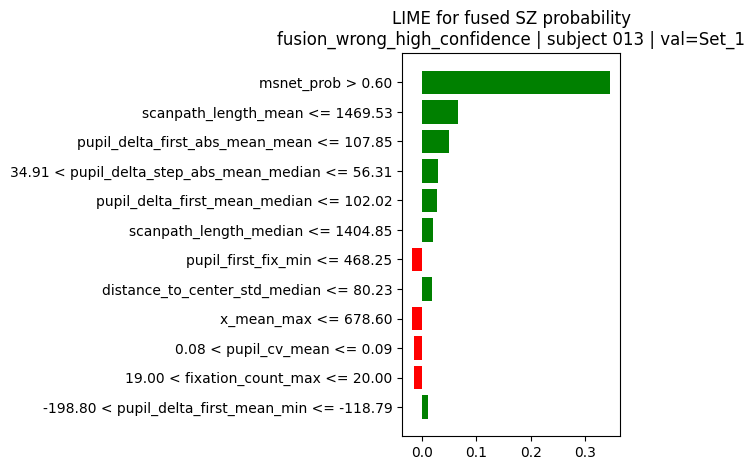

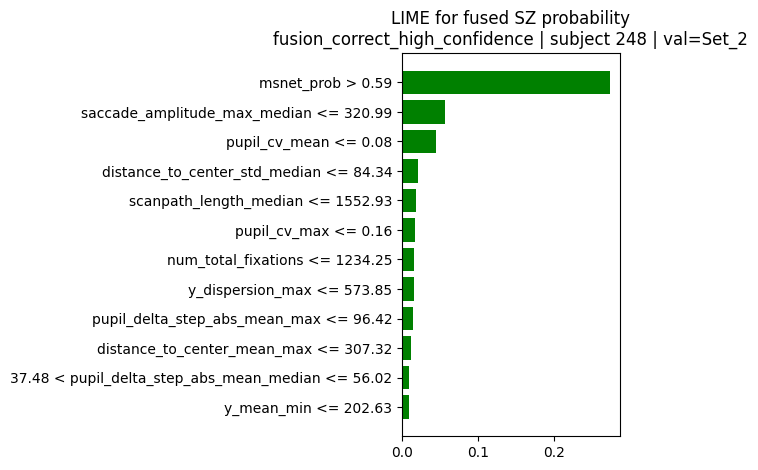


Saved XAI files:
C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\outputs\improve_behavioral/report_outputs/xai_selected_cases_lime_fusion_level.csv
C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\outputs\improve_behavioral/report_outputs/lime_fusion_level_local_explanations.csv

Generated LIME figures:
C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\outputs\improve_behavioral/report_outputs/lime_fusion_level_fusion_correct_high_confidence_248.png
C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\outputs\improve_behavioral/report_outputs/lime_fusion_level_fusion_wrong_high_confidence_013.png
C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\outputs\improve_behavioral/report_outputs/lime_fusion_level_msnet_wrong_fusion_correct_021.png
C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\outputs\improve_behavioral/report_outputs/lime_fusion_level_subject_216_incomplete_records_216.png

LIME explanation preview:


,case_type,subject_id,val_set,class_name,true_label,alpha_msnet,behavior_weight,msnet_prob,behavior_prob_fold_model,fused_prob_recomputed,fused_prob_saved,fusion_threshold,fusion_pred_saved,fusion_correct_saved,rank,feature_rule,lime_weight_for_fused_SZ,html_path,png_path
0,subject_216_incomplete_records,216,Set_0,SZ,1,0.8,0.2,0.572243,0.995467,0.656888,0.656633,0.435294,1,True,1,0.36 < msnet_prob <= 0.79,0.116694,C:\Users\hweem\Documents\dav\rvif-2026-dungmin...,C:\Users\hweem\Documents\dav\rvif-2026-dungmin...
1,subject_216_incomplete_records,216,Set_0,SZ,1,0.8,0.2,0.572243,0.995467,0.656888,0.656633,0.435294,1,True,2,pupil_max_std <= 94.53,0.039369,C:\Users\hweem\Documents\dav\rvif-2026-dungmin...,C:\Users\hweem\Documents\dav\rvif-2026-dungmin...
2,subject_216_incomplete_records,216,Set_0,SZ,1,0.8,0.2,0.572243,0.995467,0.656888,0.656633,0.435294,1,True,3,pupil_median_std <= 92.45,0.029303,C:\Users\hweem\Documents\dav\rvif-2026-dungmin...,C:\Users\hweem\Documents\dav\rvif-2026-dungmin...
3,subject_216_incomplete_records,216,Set_0,SZ,1,0.8,0.2,0.572243,0.995467,0.656888,0.656633,0.435294,1,True,4,pupil_first_fix_max <= 962.50,0.027447,C:\Users\hweem\Documents\dav\rvif-2026-dungmin...,C:\Users\hweem\Documents\dav\rvif-2026-dungmin...
4,subject_216_incomplete_records,216,Set_0,SZ,1,0.8,0.2,0.572243,0.995467,0.656888,0.656633,0.435294,1,True,5,pupil_delta_first_mean_max <= 271.25,-0.025602,C:\Users\hweem\Documents\dav\rvif-2026-dungmin...,C:\Users\hweem\Documents\dav\rvif-2026-dungmin...
5,subject_216_incomplete_records,216,Set_0,SZ,1,0.8,0.2,0.572243,0.995467,0.656888,0.656633,0.435294,1,True,6,0.08 < pupil_cv_mean <= 0.09,-0.022326,C:\Users\hweem\Documents\dav\rvif-2026-dungmin...,C:\Users\hweem\Documents\dav\rvif-2026-dungmin...
6,subject_216_incomplete_records,216,Set_0,SZ,1,0.8,0.2,0.572243,0.995467,0.656888,0.656633,0.435294,1,True,7,scanpath_length_max <= 3422.22,0.022027,C:\Users\hweem\Documents\dav\rvif-2026-dungmin...,C:\Users\hweem\Documents\dav\rvif-2026-dungmin...
7,subject_216_incomplete_records,216,Set_0,SZ,1,0.8,0.2,0.572243,0.995467,0.656888,0.656633,0.435294,1,True,8,pupil_iqr_mean <= 78.44,0.021772,C:\Users\hweem\Documents\dav\rvif-2026-dungmin...,C:\Users\hweem\Documents\dav\rvif-2026-dungmin...
8,subject_216_incomplete_records,216,Set_0,SZ,1,0.8,0.2,0.572243,0.995467,0.656888,0.656633,0.435294,1,True,9,pupil_delta_step_abs_mean_median <= 38.36,0.020665,C:\Users\hweem\Documents\dav\rvif-2026-dungmin...,C:\Users\hweem\Documents\dav\rvif-2026-dungmin...
9,subject_216_incomplete_records,216,Set_0,SZ,1,0.8,0.2,0.572243,0.995467,0.656888,0.656633,0.435294,1,True,10,pupil_delta_step_mean_median <= 10.91,-0.019857,C:\Users\hweem\Documents\dav\rvif-2026-dungmin...,C:\Users\hweem\Documents\dav\rvif-2026-dungmin...


In [24]:
import os
import json
import subprocess
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import HistGradientBoostingClassifier

try:
    from lime.lime_tabular import LimeTabularExplainer
except ImportError:
    print("Installing lime if missing...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "lime"])
    from lime.lime_tabular import LimeTabularExplainer

OUT_DIR = str(PROJECT_ROOT / "outputs" / "improve_behavioral")
REPORT_DIR = f"{OUT_DIR}/report_outputs"
os.makedirs(REPORT_DIR, exist_ok=True)

subject_path = f"{OUT_DIR}/subject_behavior_features.csv"
feature_sets_path = f"{OUT_DIR}/feature_sets_clean.json"

best_fusion_pred_path = f"{OUT_DIR}/best_fusion_prob_val.csv"
best_fusion_foldwise_path = f"{OUT_DIR}/best_fusion_foldwise_metrics.csv"
best_fusion_alpha_path = f"{OUT_DIR}/best_fusion_alpha_by_fold.csv"

msnet_prob_path = f"{OUT_DIR}/msnet_prob_val.csv"
baseline_foldwise_path = f"{OUT_DIR}/baseline_msnet_foldwise_metrics.csv"

subject_df = pd.read_csv(subject_path)

with open(feature_sets_path, "r") as f:
    feature_sets = json.load(f)

feature_cols = feature_sets["pupil_scanpath"]

subject_df["subject_id"] = (
    subject_df["subject_id"]
    .astype(str)
    .str.extract(r"(\d+)", expand=False)
    .astype(int)
    .map(lambda x: f"{x:03d}")
)

subject_df["class_name"] = subject_df["label"].map({0: "HC", 1: "SZ"})

fusion_raw = pd.read_csv(best_fusion_pred_path)
fusion_foldwise = pd.read_csv(best_fusion_foldwise_path)

fusion_raw["subject_id"] = (
    fusion_raw["subject_id"]
    .astype(str)
    .str.extract(r"(\d+)", expand=False)
    .astype(int)
    .map(lambda x: f"{x:03d}")
)

if "fused_prob" in fusion_raw.columns:
    fused_prob_col = "fused_prob"
else:
    candidates = [c for c in fusion_raw.columns if "fused" in c.lower() and "prob" in c.lower()]
    if len(candidates) == 0:
        candidates = [c for c in fusion_raw.columns if "prob" in c.lower()]
    assert len(candidates) > 0, f"Cannot find fused probability column: {fusion_raw.columns.tolist()}"
    fused_prob_col = candidates[0]

fusion_df = fusion_raw[["subject_id", "set_name", "label", fused_prob_col]].copy()
fusion_df = fusion_df.rename(columns={fused_prob_col: "fused_prob"})

fusion_threshold_map = (
    fusion_foldwise[fusion_foldwise["set_name"] != "average"]
    .set_index("set_name")["threshold"]
    .to_dict()
)

fusion_df["fusion_threshold"] = fusion_df["set_name"].map(fusion_threshold_map)
fusion_df["fusion_pred"] = (fusion_df["fused_prob"] >= fusion_df["fusion_threshold"]).astype(int)
fusion_df["fusion_correct"] = fusion_df["fusion_pred"] == fusion_df["label"].astype(int)
fusion_df["fusion_status"] = fusion_df["fusion_correct"].map({True: "Correct", False: "Wrong"})

alpha_df = pd.read_csv(best_fusion_alpha_path)

if "chosen_alpha_msnet" in alpha_df.columns:
    alpha_col = "chosen_alpha_msnet"
elif "alpha_msnet" in alpha_df.columns:
    alpha_col = "alpha_msnet"
else:
    alpha_candidates = [c for c in alpha_df.columns if "alpha" in c.lower()]
    assert len(alpha_candidates) > 0, f"Cannot find alpha column: {alpha_df.columns.tolist()}"
    alpha_col = alpha_candidates[0]

fold_col = "val_set" if "val_set" in alpha_df.columns else "set_name"
alpha_map = alpha_df.set_index(fold_col)[alpha_col].to_dict()

msnet_raw = pd.read_csv(msnet_prob_path)
baseline_foldwise = pd.read_csv(baseline_foldwise_path)

msnet_raw["subject_id"] = (
    msnet_raw["subject_id"]
    .astype(str)
    .str.extract(r"(\d+)", expand=False)
    .astype(int)
    .map(lambda x: f"{x:03d}")
)

if "msnet_prob" in msnet_raw.columns:
    msnet_prob_col = "msnet_prob"
else:
    candidates = [c for c in msnet_raw.columns if "prob" in c.lower()]
    assert len(candidates) > 0, f"Cannot find MSNet probability column: {msnet_raw.columns.tolist()}"
    msnet_prob_col = candidates[0]

msnet_df = msnet_raw[["subject_id", "set_name", "label", msnet_prob_col]].copy()
msnet_df = msnet_df.rename(columns={msnet_prob_col: "msnet_prob"})

msnet_threshold_map = (
    baseline_foldwise[baseline_foldwise["set_name"] != "average"]
    .set_index("set_name")["threshold"]
    .to_dict()
)

msnet_df["msnet_threshold"] = msnet_df["set_name"].map(msnet_threshold_map)
msnet_df["msnet_pred"] = (msnet_df["msnet_prob"] >= msnet_df["msnet_threshold"]).astype(int)
msnet_df["msnet_correct"] = msnet_df["msnet_pred"] == msnet_df["label"].astype(int)

meta_cols = [
    "subject_id",
    "set_name",
    "label",
    "class_name",
    "num_valid_images",
    "num_total_fixations",
    "mean_fixations_per_image",
]

meta_df = subject_df[meta_cols].copy()

case_df = fusion_df.merge(
    msnet_df[["subject_id", "msnet_prob", "msnet_threshold", "msnet_pred", "msnet_correct"]],
    on="subject_id",
    how="left"
)

case_df = case_df.merge(
    meta_df,
    on=["subject_id", "set_name", "label"],
    how="left"
)

case_df["fusion_margin"] = (case_df["fused_prob"] - case_df["fusion_threshold"]).abs()

assert "msnet_prob" in case_df.columns
assert case_df["msnet_prob"].notna().all(), "Some subjects missing msnet_prob."

print("Final fusion black-box:")
print("Input = msnet_prob +", len(feature_cols), "pupil_scanpath features")
print("Output = fused probability for SZ")
print("Alpha map:", alpha_map)

selected_rows = []

def add_case(case_type, df_case):
    if len(df_case) > 0:
        row = df_case.iloc[0].copy()
        row["case_type"] = case_type
        selected_rows.append(row)

add_case("subject_216_incomplete_records", case_df[case_df["subject_id"] == "216"])

fixed_df = case_df[
    (case_df["msnet_correct"] == False)
    & (case_df["fusion_correct"] == True)
].sort_values("fusion_margin", ascending=False)
add_case("msnet_wrong_fusion_correct", fixed_df)

wrong_df = case_df[
    case_df["fusion_correct"] == False
].sort_values("fusion_margin", ascending=False)
add_case("fusion_wrong_high_confidence", wrong_df)

correct_df = case_df[
    case_df["fusion_correct"] == True
].sort_values("fusion_margin", ascending=False)
add_case("fusion_correct_high_confidence", correct_df)

selected_cases = pd.DataFrame(selected_rows)
selected_cases = selected_cases.drop_duplicates(subset=["subject_id"], keep="first").reset_index(drop=True)

selected_cols = [
    "case_type",
    "subject_id",
    "set_name",
    "class_name",
    "label",
    "num_valid_images",
    "msnet_prob",
    "msnet_threshold",
    "msnet_pred",
    "msnet_correct",
    "fused_prob",
    "fusion_threshold",
    "fusion_pred",
    "fusion_correct",
    "fusion_status",
    "fusion_margin",
]

selected_cases_path = f"{REPORT_DIR}/xai_selected_cases_lime_fusion_level.csv"
selected_cases[selected_cols].to_csv(selected_cases_path, index=False)

print("\nSelected XAI cases:")
display(selected_cases[selected_cols])

lime_rows = []

X_behavior_all = subject_df[feature_cols].copy()
msnet_lookup = msnet_df.set_index("subject_id")["msnet_prob"]

for _, case in selected_cases.iterrows():
    sid = case["subject_id"]
    val_set = case["set_name"]
    alpha = float(alpha_map.get(val_set, 0.8))
    behavior_weight = 1.0 - alpha
    
    train_mask = subject_df["set_name"] != val_set
    case_mask = subject_df["subject_id"] == sid
    
    X_train_behavior = X_behavior_all.loc[train_mask].copy()
    y_train = subject_df.loc[train_mask, "label"].astype(int).values
    
    X_case_behavior = X_behavior_all.loc[case_mask].copy()
    assert len(X_case_behavior) == 1, f"Subject {sid} not found or duplicated."
    
    behavior_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", HistGradientBoostingClassifier(random_state=42))
    ])
    
    behavior_pipe.fit(X_train_behavior, y_train)
    
    train_subject_ids = subject_df.loc[train_mask, "subject_id"].values
    train_msnet = msnet_lookup.loc[train_subject_ids].values.reshape(-1, 1)
    
    X_train_behavior_imputed = behavior_pipe.named_steps["imputer"].transform(X_train_behavior)
    X_train_lime = np.hstack([train_msnet, X_train_behavior_imputed])
    
    case_msnet_prob = float(case["msnet_prob"])
    X_case_behavior_imputed = behavior_pipe.named_steps["imputer"].transform(X_case_behavior)
    X_case_lime = np.hstack([[case_msnet_prob], X_case_behavior_imputed[0]]).reshape(1, -1)
    
    lime_feature_names = ["msnet_prob"] + feature_cols
    
    explainer = LimeTabularExplainer(
        training_data=X_train_lime,
        feature_names=lime_feature_names,
        class_names=["HC", "SZ"],
        mode="classification",
        discretize_continuous=True,
        random_state=42
    )
    
    def fusion_blackbox_predict_fn(data):
        data = np.asarray(data)
        
        msnet_prob_perturbed = np.clip(data[:, 0], 0, 1)
        behavior_features_perturbed = data[:, 1:]
        
        behavior_df = pd.DataFrame(behavior_features_perturbed, columns=feature_cols)
        behavior_prob = behavior_pipe.predict_proba(behavior_df)[:, 1]
        
        fused_prob = alpha * msnet_prob_perturbed + behavior_weight * behavior_prob
        fused_prob = np.clip(fused_prob, 0, 1)
        
        return np.column_stack([1 - fused_prob, fused_prob])
    
    exp = explainer.explain_instance(
        data_row=X_case_lime[0],
        predict_fn=fusion_blackbox_predict_fn,
        num_features=12,
        labels=[1]
    )
    
    safe_case_type = str(case["case_type"]).replace("/", "_")
    
    html_path = f"{REPORT_DIR}/lime_fusion_level_{safe_case_type}_{sid}.html"
    png_path = f"{REPORT_DIR}/lime_fusion_level_{safe_case_type}_{sid}.png"
    
    exp.save_to_file(html_path)
    
    fig = exp.as_pyplot_figure(label=1)
    plt.title(
        f"LIME for fused SZ probability\n"
        f"{case['case_type']} | subject {sid} | val={val_set}"
    )
    plt.tight_layout()
    fig.savefig(png_path, dpi=220, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    
    behavior_prob_case = behavior_pipe.predict_proba(X_case_behavior)[0, 1]
    fused_prob_recomputed = alpha * case_msnet_prob + behavior_weight * behavior_prob_case
    
    for rank, (feature_rule, weight) in enumerate(exp.as_list(label=1), start=1):
        lime_rows.append({
            "case_type": case["case_type"],
            "subject_id": sid,
            "val_set": val_set,
            "class_name": case["class_name"],
            "true_label": int(case["label"]),
            "alpha_msnet": alpha,
            "behavior_weight": behavior_weight,
            "msnet_prob": case_msnet_prob,
            "behavior_prob_fold_model": behavior_prob_case,
            "fused_prob_recomputed": fused_prob_recomputed,
            "fused_prob_saved": float(case["fused_prob"]),
            "fusion_threshold": float(case["fusion_threshold"]),
            "fusion_pred_saved": int(case["fusion_pred"]),
            "fusion_correct_saved": bool(case["fusion_correct"]),
            "rank": rank,
            "feature_rule": feature_rule,
            "lime_weight_for_fused_SZ": weight,
            "html_path": html_path,
            "png_path": png_path,
        })

lime_df = pd.DataFrame(lime_rows)
lime_path = f"{REPORT_DIR}/lime_fusion_level_local_explanations.csv"
lime_df.to_csv(lime_path, index=False)

print("\nSaved XAI files:")
print(selected_cases_path)
print(lime_path)

print("\nGenerated LIME figures:")
for p in sorted(lime_df["png_path"].unique()):
    print(p)

print("\nLIME explanation preview:")
display(lime_df.head(40))

## 12. Instructor-requested comparisons, confusion matrices, and case analysis

This section produces the report-ready evidence requested by the instructor. All results in this section are **4-fold validation results** unless explicitly marked as published EMS test-set results. The proposed model is not assigned a held-out test metric until the EMS authors evaluate `prob_test.txt`.

Best result of each conventional ML classifier (4-fold validation):


,method,feature_set,n_features,acc,sensitivity,specificity,auc,precision,f1_score
0,Logistic Regression,duration_pupil,150,0.82500,0.822443,0.825694,0.904153,0.826144,0.820931
1,HistGradientBoosting,pupil_scanpath,173,0.83125,0.872443,0.789583,0.897521,0.806944,0.834722
2,Random Forest,all_behavior,233,0.80000,0.842614,0.760417,0.888702,0.777779,0.806385



Our experimental comparison (do not call these held-out test results):


,method,feature_set,acc,sensitivity,specificity,auc,precision,f1_score,evaluation
0,MSNet reproduced (official pretrained weights),RINet feature maps,0.83125,0.805114,0.870833,0.897217,0.857516,0.824385,4-fold validation
1,Logistic Regression,duration_pupil,0.82500,0.822443,0.825694,0.904153,0.826144,0.820931,4-fold validation
2,HistGradientBoosting,pupil_scanpath,0.83125,0.872443,0.789583,0.897521,0.806944,0.834722,4-fold validation
3,Random Forest,all_behavior,0.80000,0.842614,0.760417,0.888702,0.777779,0.806385,4-fold validation
4,MSNet + Behavioral Fusion (proposed),pupil_scanpath + MSNet,0.84375,0.846307,0.836111,0.950253,0.840322,0.840532,4-fold validation



Official EMS benchmark + our validation row:


,method,val_acc,val_sensitivity,val_specificity,val_auc,val_precision,val_f1,test_acc,test_sensitivity,test_specificity,test_auc,test_precision,test_f1,source
0,EDB_SVM,0.73130,0.715600,0.739600,0.808600,0.724000,0.719500,0.6875,0.6667,0.7083,0.7813,0.6957,0.6809,Reported in official EMS benchmark
1,EDB_QDA,0.70630,0.602600,0.799300,0.720500,0.740300,0.663800,0.7500,0.6667,0.8333,0.8073,0.8000,0.7273,Reported in official EMS benchmark
2,EDB_BYS,0.70000,0.606500,0.778500,0.798700,0.706100,0.651000,0.7292,0.5833,0.8750,0.7413,0.8235,0.6829,Reported in official EMS benchmark
3,ESR_SVM,0.79380,0.794600,0.784700,0.849800,0.785900,0.788900,0.7500,0.7083,0.7917,0.7760,0.7727,0.7391,Reported in official EMS benchmark
4,ESR_RF,0.76250,0.754000,0.763900,0.852100,0.754900,0.753800,0.7292,0.7083,0.7500,0.7760,0.7391,0.7234,Reported in official EMS benchmark
5,IAS,0.75630,0.763400,0.750000,0.818000,0.777000,0.757200,0.7500,0.6667,0.8333,0.8229,0.8000,0.7273,Reported in official EMS benchmark
6,LVA,0.81880,0.776600,0.858500,0.898700,0.855200,0.809600,0.7083,0.6667,0.7500,0.8038,0.7273,0.6957,Reported in official EMS benchmark
7,DDB_DoF,0.72500,0.787200,0.672700,0.764500,0.725400,0.744600,0.6667,0.8333,0.5000,0.7483,0.6250,0.7143,Reported in official EMS benchmark
8,DDB,0.73130,0.786600,0.687300,0.777200,0.739400,0.751200,0.7083,0.6667,0.7500,0.7882,0.7273,0.6957,Reported in official EMS benchmark
9,DVP,0.78750,0.754800,0.805600,0.851600,0.820600,0.776900,0.7500,0.7083,0.7917,0.8194,0.7727,0.7391,Reported in official EMS benchmark



EMS evaluation protocol note

Official EMS protocol:
- 160 subjects: 4-fold cross-validation -> reported as Validation Set.
- 48 subjects: held-out Test Set, whose labels are not used locally.

Official MSNet:
- Validation Specificity = 0.8708 (87.08%)
- Test Specificity       = 0.7917 (79.17%)

Our reproduced MSNet validation:
- Specificity = 0.8708

Our proposed fusion validation:
- Specificity = 0.8361
- AUC         = 0.9503

Therefore, the ~87% MSNet Specificity is a VALIDATION result, not a held-out TEST result.
Do not compare our validation value with the original test value as if they were measured on the same split.



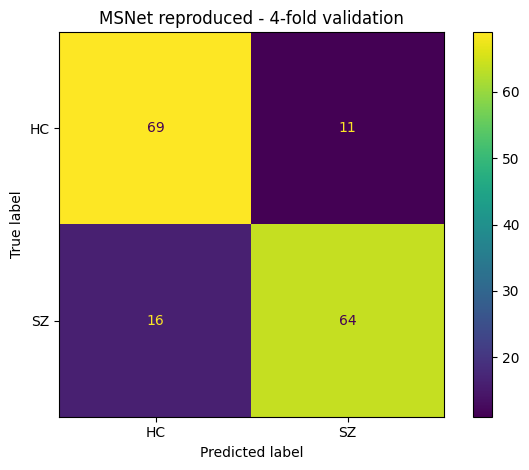

MSNet reproduced - 4-fold validation


,Pred_HC,Pred_SZ
Actual_HC,69,11
Actual_SZ,16,64


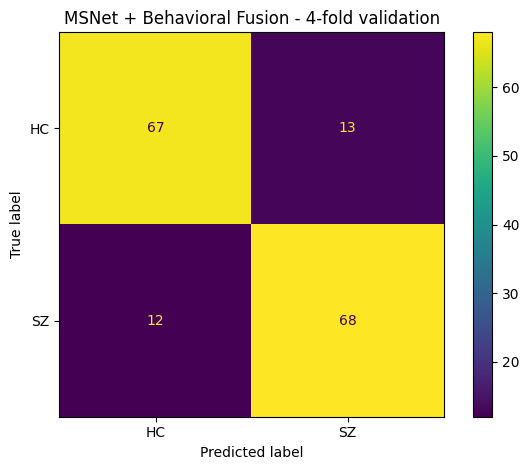

MSNet + Behavioral Fusion - 4-fold validation


,Pred_HC,Pred_SZ
Actual_HC,67,13
Actual_SZ,12,68



Case status counts:


,status,n_subjects
0,Both_correct,125
1,Both_wrong,17
2,Corrected_by_fusion,10
3,New_error_after_fusion,8



Examples: MSNet wrong -> Fusion correct


,subject_id,set_name,class_name,label,msnet_prob,msnet_threshold,msnet_pred,behavior_prob,fused_prob,fusion_threshold,fusion_pred,status
0,021,Set_1,HC,0,0.342940,0.341176,1,0.039888,0.282330,0.478431,0,Corrected_by_fusion
1,033,Set_3,HC,0,0.507003,0.435294,1,0.003022,0.406207,0.466667,0,Corrected_by_fusion
2,001,Set_1,HC,0,0.551617,0.341176,1,0.031274,0.447548,0.478431,0,Corrected_by_fusion
3,302,Set_0,SZ,1,0.410718,0.423529,0,0.994988,0.527572,0.435294,1,Corrected_by_fusion
4,213,Set_0,SZ,1,0.382214,0.423529,0,0.985581,0.502888,0.435294,1,Corrected_by_fusion
5,279,Set_0,SZ,1,0.376806,0.423529,0,0.998245,0.501093,0.435294,1,Corrected_by_fusion



Examples: Fusion still wrong


,subject_id,set_name,class_name,label,msnet_prob,msnet_threshold,msnet_pred,behavior_prob,fused_prob,fusion_threshold,fusion_pred,status
0,013,Set_1,HC,0,0.829764,0.341176,1,0.997781,0.863368,0.478431,1,Both_wrong
1,034,Set_2,HC,0,0.931247,0.270588,1,0.045687,0.754135,0.415686,1,Both_wrong
2,022,Set_1,HC,0,0.790496,0.341176,1,0.655250,0.763447,0.478431,1,Both_wrong
3,234,Set_2,SZ,1,0.064442,0.270588,0,0.134999,0.078553,0.415686,0,Both_wrong
4,212,Set_2,SZ,1,0.064703,0.270588,0,0.944713,0.240705,0.415686,0,Both_wrong
5,266,Set_2,SZ,1,0.061942,0.270588,0,0.960850,0.241724,0.415686,0,Both_wrong


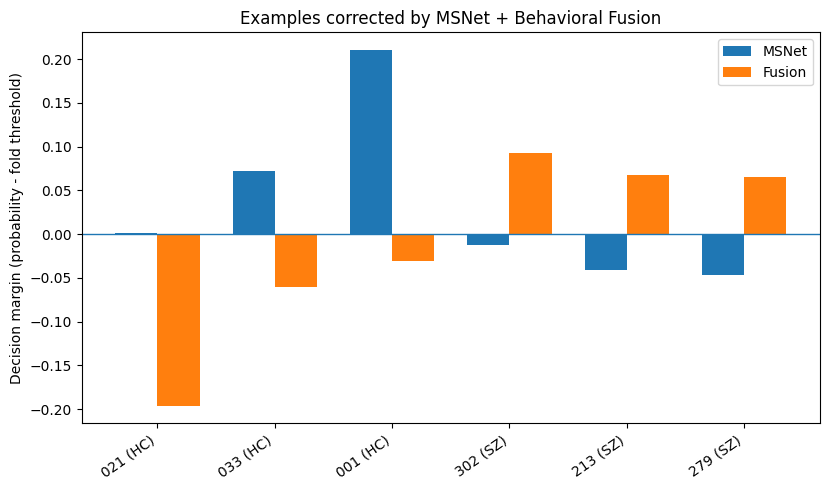

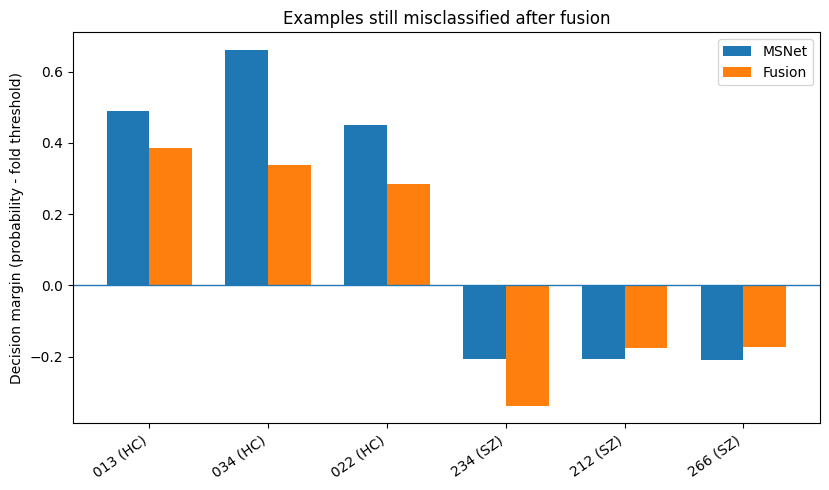


Validation confusion-matrix summary

MSNet reproduced:
TN=69, FP=11, FN=16, TP=64

Proposed fusion:
TN=67, FP=13, FN=12, TP=68

Changes after fusion:
- False negatives (SZ predicted as HC): 16 -> 12
- False positives (HC predicted as SZ): 11 -> 13
- Corrected-by-fusion subjects: 10
- New errors introduced by fusion: 8
- Both models wrong: 17
- Both models correct: 125

Interpretation:
The fusion improves SZ sensitivity by correcting a number of MSNet false negatives,
but it can introduce additional HC false positives. This trade-off explains why
the proposed model can improve overall AUC while Specificity does not necessarily increase.

Saved instructor-requested validation outputs to: C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\outputs\improve_behavioral/report_outputs


In [25]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

OUT_DIR = str(PROJECT_ROOT / "outputs" / "improve_behavioral")
REPORT_DIR = f"{OUT_DIR}/report_outputs"
os.makedirs(REPORT_DIR, exist_ok=True)

# ---------------------------------------------------------------------
# A. Conventional ML baselines actually run in this notebook
# ---------------------------------------------------------------------

behavior_metrics_path = f"{OUT_DIR}/behavior_only_metrics.csv"
assert os.path.exists(behavior_metrics_path), f"Missing {behavior_metrics_path}"

behavior_metrics_all = pd.read_csv(behavior_metrics_path)

model_display_names = {
    "logreg": "Logistic Regression",
    "rf": "Random Forest",
    "hgb": "HistGradientBoosting",
}

best_ml_rows = []
for model_name, g in behavior_metrics_all.groupby("model"):
    # Select the best feature set for each ML classifier by validation AUC.
    row = (
        g.sort_values(["auc", "f1_score", "acc"], ascending=False)
        .iloc[0]
        .copy()
    )
    row["method"] = model_display_names.get(model_name, model_name)
    best_ml_rows.append(row)

best_ml_table = pd.DataFrame(best_ml_rows)

best_ml_table = best_ml_table[
    [
        "method",
        "feature_set",
        "n_features",
        "acc",
        "sensitivity",
        "specificity",
        "auc",
        "precision",
        "f1_score",
    ]
].sort_values("auc", ascending=False).reset_index(drop=True)

best_ml_path = f"{REPORT_DIR}/ml_baseline_comparison_validation.csv"
best_ml_table.to_csv(best_ml_path, index=False)

print("Best result of each conventional ML classifier (4-fold validation):")
display(best_ml_table)


# ---------------------------------------------------------------------
# B. Our experimental comparison: reproduced MSNet + ML + final fusion
# ---------------------------------------------------------------------

baseline_foldwise = pd.read_csv(f"{OUT_DIR}/baseline_msnet_foldwise_metrics.csv")
fusion_foldwise = pd.read_csv(f"{OUT_DIR}/best_fusion_foldwise_metrics.csv")
fusion_summary = pd.read_csv(f"{OUT_DIR}/fusion_metrics_nested_alpha.csv")

baseline_avg = baseline_foldwise[baseline_foldwise["set_name"] == "average"].iloc[0]
fusion_avg = fusion_foldwise[fusion_foldwise["set_name"] == "average"].iloc[0]
best_fusion_config = fusion_summary.sort_values(
    ["auc", "f1_score", "acc"], ascending=False
).iloc[0]

our_rows = [
    {
        "method": "MSNet reproduced (official pretrained weights)",
        "feature_set": "RINet feature maps",
        "acc": baseline_avg["acc"],
        "sensitivity": baseline_avg["sensitivity"],
        "specificity": baseline_avg["specificity"],
        "auc": baseline_avg["auc"],
        "precision": baseline_avg["precision"],
        "f1_score": baseline_avg["f1_score"],
        "evaluation": "4-fold validation",
    }
]

for _, r in best_ml_table.iterrows():
    our_rows.append(
        {
            "method": r["method"],
            "feature_set": r["feature_set"],
            "acc": r["acc"],
            "sensitivity": r["sensitivity"],
            "specificity": r["specificity"],
            "auc": r["auc"],
            "precision": r["precision"],
            "f1_score": r["f1_score"],
            "evaluation": "4-fold validation",
        }
    )

our_rows.append(
    {
        "method": "MSNet + Behavioral Fusion (proposed)",
        "feature_set": f"{best_fusion_config['feature_set']} + MSNet",
        "acc": fusion_avg["acc"],
        "sensitivity": fusion_avg["sensitivity"],
        "specificity": fusion_avg["specificity"],
        "auc": fusion_avg["auc"],
        "precision": fusion_avg["precision"],
        "f1_score": fusion_avg["f1_score"],
        "evaluation": "4-fold validation",
    }
)

our_methods_table = pd.DataFrame(our_rows)
our_methods_path = f"{REPORT_DIR}/our_methods_comparison_validation.csv"
our_methods_table.to_csv(our_methods_path, index=False)

print("\nOur experimental comparison (do not call these held-out test results):")
display(our_methods_table)


# ---------------------------------------------------------------------
# C. Official EMS benchmark values
# Source:
# https://github.com/YingjieSong1/EMS
# These are reported values, not rerun by this notebook.
# ---------------------------------------------------------------------

benchmark_rows = [
    ["EDB_SVM", 0.7313, 0.7156, 0.7396, 0.8086, 0.7240, 0.7195, 0.6875, 0.6667, 0.7083, 0.7813, 0.6957, 0.6809],
    ["EDB_QDA", 0.7063, 0.6026, 0.7993, 0.7205, 0.7403, 0.6638, 0.7500, 0.6667, 0.8333, 0.8073, 0.8000, 0.7273],
    ["EDB_BYS", 0.7000, 0.6065, 0.7785, 0.7987, 0.7061, 0.6510, 0.7292, 0.5833, 0.8750, 0.7413, 0.8235, 0.6829],
    ["ESR_SVM", 0.7938, 0.7946, 0.7847, 0.8498, 0.7859, 0.7889, 0.7500, 0.7083, 0.7917, 0.7760, 0.7727, 0.7391],
    ["ESR_RF", 0.7625, 0.7540, 0.7639, 0.8521, 0.7549, 0.7538, 0.7292, 0.7083, 0.7500, 0.7760, 0.7391, 0.7234],
    ["IAS", 0.7563, 0.7634, 0.7500, 0.8180, 0.7770, 0.7572, 0.7500, 0.6667, 0.8333, 0.8229, 0.8000, 0.7273],
    ["LVA", 0.8188, 0.7766, 0.8585, 0.8987, 0.8552, 0.8096, 0.7083, 0.6667, 0.7500, 0.8038, 0.7273, 0.6957],
    ["DDB_DoF", 0.7250, 0.7872, 0.6727, 0.7645, 0.7254, 0.7446, 0.6667, 0.8333, 0.5000, 0.7483, 0.6250, 0.7143],
    ["DDB", 0.7313, 0.7866, 0.6873, 0.7772, 0.7394, 0.7512, 0.7083, 0.6667, 0.7500, 0.7882, 0.7273, 0.6957],
    ["DVP", 0.7875, 0.7548, 0.8056, 0.8516, 0.8206, 0.7769, 0.7500, 0.7083, 0.7917, 0.8194, 0.7727, 0.7391],
    ["GPI_LSTM", 0.7125, 0.6881, 0.7424, 0.7953, 0.7291, 0.6947, 0.6875, 0.7917, 0.5833, 0.7726, 0.6552, 0.7170],
    ["GPI_GRU", 0.7063, 0.7045, 0.7188, 0.7798, 0.7219, 0.6983, 0.7500, 0.7083, 0.7917, 0.8125, 0.7727, 0.7391],
    ["MSNet", 0.8313, 0.8051, 0.8708, 0.8972, 0.8575, 0.8244, 0.8125, 0.8333, 0.7917, 0.8854, 0.8000, 0.8163],
]

benchmark_cols = [
    "method",
    "val_acc", "val_sensitivity", "val_specificity", "val_auc", "val_precision", "val_f1",
    "test_acc", "test_sensitivity", "test_specificity", "test_auc", "test_precision", "test_f1",
]

ems_benchmark = pd.DataFrame(benchmark_rows, columns=benchmark_cols)
ems_benchmark["source"] = "Reported in official EMS benchmark"

# Add the proposed method's validation result only.
# Held-out test values intentionally remain NaN until returned by the EMS authors.
proposed_benchmark_row = {
    "method": "MSNet + Behavioral Fusion (proposed)",
    "val_acc": fusion_avg["acc"],
    "val_sensitivity": fusion_avg["sensitivity"],
    "val_specificity": fusion_avg["specificity"],
    "val_auc": fusion_avg["auc"],
    "val_precision": fusion_avg["precision"],
    "val_f1": fusion_avg["f1_score"],
    "test_acc": np.nan,
    "test_sensitivity": np.nan,
    "test_specificity": np.nan,
    "test_auc": np.nan,
    "test_precision": np.nan,
    "test_f1": np.nan,
    "source": "Our 4-fold validation; test pending author evaluation",
}

ems_benchmark_with_ours = pd.concat(
    [ems_benchmark, pd.DataFrame([proposed_benchmark_row])],
    ignore_index=True,
)

benchmark_path = f"{REPORT_DIR}/ems_official_benchmark_plus_ours.csv"
ems_benchmark_with_ours.to_csv(benchmark_path, index=False)

print("\nOfficial EMS benchmark + our validation row:")
display(ems_benchmark_with_ours)


# ---------------------------------------------------------------------
# D. Explicit note resolving the 87% vs 79% Specificity issue
# ---------------------------------------------------------------------

protocol_note = f"""EMS evaluation protocol note
============================

Official EMS protocol:
- 160 subjects: 4-fold cross-validation -> reported as Validation Set.
- 48 subjects: held-out Test Set, whose labels are not used locally.

Official MSNet:
- Validation Specificity = 0.8708 (87.08%)
- Test Specificity       = 0.7917 (79.17%)

Our reproduced MSNet validation:
- Specificity = {baseline_avg['specificity']:.4f}

Our proposed fusion validation:
- Specificity = {fusion_avg['specificity']:.4f}
- AUC         = {fusion_avg['auc']:.4f}

Therefore, the ~87% MSNet Specificity is a VALIDATION result, not a held-out TEST result.
Do not compare our validation value with the original test value as if they were measured on the same split.
"""

protocol_note_path = f"{REPORT_DIR}/validation_vs_test_protocol_note.txt"
with open(protocol_note_path, "w", encoding="utf-8") as f:
    f.write(protocol_note)

print("\n" + protocol_note)


# ---------------------------------------------------------------------
# E. Reconstruct fold-specific predictions and confusion matrices
# ---------------------------------------------------------------------

msnet_df = pd.read_csv(f"{OUT_DIR}/msnet_prob_val.csv")
fusion_df = pd.read_csv(f"{OUT_DIR}/best_fusion_prob_val.csv")

def normalize_train_subject_id(x):
    digits = pd.Series([str(x)]).str.extract(r"(\d+)", expand=False).iloc[0]
    return f"{int(digits):03d}"

msnet_df["subject_id"] = msnet_df["subject_id"].map(normalize_train_subject_id)
fusion_df["subject_id"] = fusion_df["subject_id"].map(normalize_train_subject_id)

baseline_threshold_map = (
    baseline_foldwise[baseline_foldwise["set_name"] != "average"]
    .set_index("set_name")["threshold"]
    .to_dict()
)

fusion_threshold_map = (
    fusion_foldwise[fusion_foldwise["set_name"] != "average"]
    .set_index("set_name")["threshold"]
    .to_dict()
)

msnet_df["msnet_threshold"] = msnet_df["set_name"].map(baseline_threshold_map)
msnet_df["msnet_pred"] = (
    msnet_df["msnet_prob"] >= msnet_df["msnet_threshold"]
).astype(int)

fusion_df["fusion_threshold"] = fusion_df["set_name"].map(fusion_threshold_map)
fusion_df["fusion_pred"] = (
    fusion_df["fused_prob"] >= fusion_df["fusion_threshold"]
).astype(int)

def save_confusion_outputs(df, pred_col, title, stem):
    cm = confusion_matrix(df["label"].astype(int), df[pred_col].astype(int), labels=[0, 1])
    cm_df = pd.DataFrame(
        cm,
        index=["Actual_HC", "Actual_SZ"],
        columns=["Pred_HC", "Pred_SZ"],
    )
    csv_path = f"{REPORT_DIR}/{stem}.csv"
    png_path = f"{REPORT_DIR}/{stem}.png"
    cm_df.to_csv(csv_path)

    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["HC", "SZ"])
    disp.plot(values_format="d")
    plt.title(title)
    plt.tight_layout()
    plt.savefig(png_path, dpi=220, bbox_inches="tight")
    plt.show()
    plt.close()

    print(title)
    display(cm_df)
    return cm_df, csv_path, png_path

cm_msnet, cm_msnet_csv, cm_msnet_png = save_confusion_outputs(
    msnet_df,
    "msnet_pred",
    "MSNet reproduced - 4-fold validation",
    "confusion_matrix_msnet_validation",
)

cm_fusion, cm_fusion_csv, cm_fusion_png = save_confusion_outputs(
    fusion_df,
    "fusion_pred",
    "MSNet + Behavioral Fusion - 4-fold validation",
    "confusion_matrix_fusion_validation",
)


# ---------------------------------------------------------------------
# F. Subject-level error analysis
# ---------------------------------------------------------------------

case_df = fusion_df[
    [
        "subject_int",
        "subject_id",
        "set_name",
        "label",
        "behavior_prob",
        "fused_prob",
        "fusion_threshold",
        "fusion_pred",
    ]
].copy()

case_df = case_df.merge(
    msnet_df[
        [
            "subject_id",
            "set_name",
            "msnet_prob",
            "msnet_threshold",
            "msnet_pred",
        ]
    ],
    on=["subject_id", "set_name"],
    how="left",
)

assert case_df["msnet_prob"].notna().all(), "Some MSNet probabilities are missing after merge."

case_df["class_name"] = case_df["label"].map({0: "HC", 1: "SZ"})
case_df["msnet_correct"] = case_df["msnet_pred"] == case_df["label"]
case_df["fusion_correct"] = case_df["fusion_pred"] == case_df["label"]

case_df["msnet_margin"] = case_df["msnet_prob"] - case_df["msnet_threshold"]
case_df["fusion_margin_signed"] = case_df["fused_prob"] - case_df["fusion_threshold"]
case_df["fusion_margin_abs"] = case_df["fusion_margin_signed"].abs()

def classify_case_status(r):
    if (not r["msnet_correct"]) and r["fusion_correct"]:
        return "Corrected_by_fusion"
    if r["msnet_correct"] and (not r["fusion_correct"]):
        return "New_error_after_fusion"
    if (not r["msnet_correct"]) and (not r["fusion_correct"]):
        return "Both_wrong"
    return "Both_correct"

case_df["status"] = case_df.apply(classify_case_status, axis=1)

all_cases_path = f"{REPORT_DIR}/validation_case_analysis_all.csv"
case_df.to_csv(all_cases_path, index=False)

status_counts = (
    case_df["status"]
    .value_counts()
    .rename_axis("status")
    .reset_index(name="n_subjects")
)
status_counts_path = f"{REPORT_DIR}/validation_case_status_counts.csv"
status_counts.to_csv(status_counts_path, index=False)

print("\nCase status counts:")
display(status_counts)


# Select several examples from both HC and SZ where possible.
corrected = case_df[case_df["status"] == "Corrected_by_fusion"].copy()
corrected = corrected.sort_values("fusion_margin_abs", ascending=False)

remaining_wrong = case_df[~case_df["fusion_correct"]].copy()
remaining_wrong = remaining_wrong.sort_values("fusion_margin_abs", ascending=False)

def select_examples_by_class(df, n_per_class=3):
    selected = []
    for label in [0, 1]:
        part = df[df["label"] == label].head(n_per_class)
        selected.append(part)
    return pd.concat(selected, ignore_index=True) if selected else pd.DataFrame()

corrected_examples = select_examples_by_class(corrected, n_per_class=3)
remaining_error_examples = select_examples_by_class(remaining_wrong, n_per_class=3)

example_cols = [
    "subject_id",
    "set_name",
    "class_name",
    "label",
    "msnet_prob",
    "msnet_threshold",
    "msnet_pred",
    "behavior_prob",
    "fused_prob",
    "fusion_threshold",
    "fusion_pred",
    "status",
]

corrected_path = f"{REPORT_DIR}/examples_corrected_by_fusion.csv"
remaining_path = f"{REPORT_DIR}/examples_remaining_errors.csv"

corrected_examples[example_cols].to_csv(corrected_path, index=False)
remaining_error_examples[example_cols].to_csv(remaining_path, index=False)

print("\nExamples: MSNet wrong -> Fusion correct")
display(corrected_examples[example_cols])

print("\nExamples: Fusion still wrong")
display(remaining_error_examples[example_cols])


# ---------------------------------------------------------------------
# G. Report-ready visualizations of the selected examples
# Decision margin > 0 -> predicted SZ; margin < 0 -> predicted HC.
# ---------------------------------------------------------------------

def plot_case_margins(example_df, title, output_path):
    if len(example_df) == 0:
        print("No examples available for:", title)
        return

    labels = [
        f"{sid} ({cls})"
        for sid, cls in zip(example_df["subject_id"], example_df["class_name"])
    ]
    x = np.arange(len(example_df))
    width = 0.36

    fig, ax = plt.subplots(figsize=(max(8, len(example_df) * 1.4), 5))
    ax.bar(x - width / 2, example_df["msnet_margin"], width, label="MSNet")
    ax.bar(x + width / 2, example_df["fusion_margin_signed"], width, label="Fusion")
    ax.axhline(0.0, linewidth=1)
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=35, ha="right")
    ax.set_ylabel("Decision margin (probability - fold threshold)")
    ax.set_title(title)
    ax.legend()
    plt.tight_layout()
    plt.savefig(output_path, dpi=220, bbox_inches="tight")
    plt.show()
    plt.close(fig)

corrected_plot_path = f"{REPORT_DIR}/examples_corrected_by_fusion.png"
remaining_plot_path = f"{REPORT_DIR}/examples_remaining_errors.png"

plot_case_margins(
    corrected_examples,
    "Examples corrected by MSNet + Behavioral Fusion",
    corrected_plot_path,
)

plot_case_margins(
    remaining_error_examples,
    "Examples still misclassified after fusion",
    remaining_plot_path,
)


# ---------------------------------------------------------------------
# H. Save a concise report note
# ---------------------------------------------------------------------

tn_m, fp_m, fn_m, tp_m = cm_msnet.values.ravel()
tn_f, fp_f, fn_f, tp_f = cm_fusion.values.ravel()

analysis_note = f"""Validation confusion-matrix summary
===================================

MSNet reproduced:
TN={tn_m}, FP={fp_m}, FN={fn_m}, TP={tp_m}

Proposed fusion:
TN={tn_f}, FP={fp_f}, FN={fn_f}, TP={tp_f}

Changes after fusion:
- False negatives (SZ predicted as HC): {fn_m} -> {fn_f}
- False positives (HC predicted as SZ): {fp_m} -> {fp_f}
- Corrected-by-fusion subjects: {(case_df['status'] == 'Corrected_by_fusion').sum()}
- New errors introduced by fusion: {(case_df['status'] == 'New_error_after_fusion').sum()}
- Both models wrong: {(case_df['status'] == 'Both_wrong').sum()}
- Both models correct: {(case_df['status'] == 'Both_correct').sum()}

Interpretation:
The fusion improves SZ sensitivity by correcting a number of MSNet false negatives,
but it can introduce additional HC false positives. This trade-off explains why
the proposed model can improve overall AUC while Specificity does not necessarily increase.
"""

analysis_note_path = f"{REPORT_DIR}/confusion_and_case_analysis_note.txt"
with open(analysis_note_path, "w", encoding="utf-8") as f:
    f.write(analysis_note)

print("\n" + analysis_note)

print("Saved instructor-requested validation outputs to:", REPORT_DIR)

## 13. Generate the proposed model prediction file for the hidden EMS test set

The official EMS benchmark keeps 48 subjects as a held-out test set. The public repository asks users to generate `prob_test.txt`, with each row containing `subject id, probability, binary prediction`, and email the file to the authors for evaluation.

This section selects the validation fold/model with the highest fusion AUC, runs the matching official pretrained MSNet on the hidden test subjects, extracts the same behavioral features from test fixation records, trains the selected behavioral component on the corresponding three training folds, performs the final probability fusion, and writes the submission file.

**Important:** the notebook does not invent test metrics because the hidden test labels are unavailable locally. Test Accuracy/Sensitivity/Specificity/AUC/F1 must be obtained from the EMS authors after sending `prob_test.txt`.

In [26]:
import os
import sys
import glob
import json
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd

OUT_DIR = str(PROJECT_ROOT / "outputs" / "improve_behavioral")
REPORT_DIR = f"{OUT_DIR}/report_outputs"
REPO_DIR = str(PROJECT_ROOT / "EMS_repo")
DATASET_DIR = str(PROJECT_ROOT / "EMS")
BASELINE_BACKUP_DIR = str(PROJECT_ROOT / "work" / "result_pretrained_backup")

os.makedirs(REPORT_DIR, exist_ok=True)

required_files = [
    f"{OUT_DIR}/best_fusion_foldwise_metrics.csv",
    f"{OUT_DIR}/best_fusion_alpha_by_fold.csv",
    f"{OUT_DIR}/fusion_metrics_nested_alpha.csv",
    f"{OUT_DIR}/subject_behavior_features.csv",
    f"{OUT_DIR}/stim_behavior_features.csv",
    f"{OUT_DIR}/feature_sets_clean.json",
]
for p in required_files:
    assert os.path.exists(p), f"Missing required output: {p}"

assert os.path.exists(f"{DATASET_DIR}/Test/Fixations"), "EMS Test/Fixations folder is missing."
assert os.path.exists(FEATURE_DICT), "feature_dict_RINet.npy is missing."
assert "compute_one_stimulus_features" in globals(), "Run the behavioral feature-engineering section first."
assert "make_behavior_model" in globals(), "Run the behavioral-model section first."


# ---------------------------------------------------------------------
# A. Select the candidate model according to validation AUC
# ---------------------------------------------------------------------

fusion_foldwise = pd.read_csv(f"{OUT_DIR}/best_fusion_foldwise_metrics.csv")
fusion_alpha_df = pd.read_csv(f"{OUT_DIR}/best_fusion_alpha_by_fold.csv")
fusion_summary = pd.read_csv(f"{OUT_DIR}/fusion_metrics_nested_alpha.csv")

fold_candidates = fusion_foldwise[fusion_foldwise["set_name"] != "average"].copy()
selected_fold_row = fold_candidates.sort_values(
    ["auc", "f1_score", "acc"], ascending=False
).iloc[0]

selected_set = str(selected_fold_row["set_name"])
selected_fusion_threshold = float(selected_fold_row["threshold"])
selected_validation_auc = float(selected_fold_row["auc"])

best_fusion_config = fusion_summary.sort_values(
    ["auc", "f1_score", "acc"], ascending=False
).iloc[0]

best_feature_set = str(best_fusion_config["feature_set"])
best_behavior_model = str(best_fusion_config["model"])

alpha_row = fusion_alpha_df[fusion_alpha_df["val_set"] == selected_set]
assert len(alpha_row) == 1, f"Cannot uniquely find alpha for {selected_set}"

alpha_msnet = float(alpha_row.iloc[0]["chosen_alpha_msnet"])
behavior_weight = 1.0 - alpha_msnet

with open(f"{OUT_DIR}/feature_sets_clean.json", "r", encoding="utf-8") as f:
    feature_sets = json.load(f)

assert best_feature_set in feature_sets, f"Unknown feature set: {best_feature_set}"
selected_feature_cols = feature_sets[best_feature_set]

print("Selected final candidate for hidden test:")
print("  validation fold:", selected_set)
print("  fold validation AUC:", selected_validation_auc)
print("  behavior feature set:", best_feature_set)
print("  behavior classifier:", best_behavior_model)
print("  MSNet alpha:", alpha_msnet)
print("  behavior weight:", behavior_weight)
print("  fusion threshold:", selected_fusion_threshold)


# ---------------------------------------------------------------------
# B. Run official pretrained MSNet on the 48 EMS test subjects
# ---------------------------------------------------------------------

selected_model_dir = f"{BASELINE_BACKUP_DIR}/{selected_set}"
assert os.path.exists(f"{selected_model_dir}/best_model.pt"), (
    f"Missing pretrained MSNet weight: {selected_model_dir}/best_model.pt"
)
assert os.path.exists(f"{selected_model_dir}/threshold.txt"), (
    f"Missing MSNet threshold file: {selected_model_dir}/threshold.txt"
)

cmd = [
    sys.executable,
    str(Path(REPO_DIR) / "test.py"),
    "--dataset_dir", DATASET_DIR,
    "--set_name", selected_set,
    "--result_root", BASELINE_BACKUP_DIR,
    "--feature_dict", FEATURE_DICT,
    "--no_workers", "0",
]

print("\nRunning official MSNet test command:")
print(" ".join(cmd))
subprocess.run(cmd, cwd=PROJECT_ROOT, check=True)

msnet_test_path = f"{selected_model_dir}/prob_test.txt"
assert os.path.exists(msnet_test_path), f"MSNet did not create {msnet_test_path}"

msnet_test = pd.read_csv(
    msnet_test_path,
    header=None,
    names=["subject_id", "msnet_prob", "msnet_binary_original"],
)

msnet_test["subject_id"] = msnet_test["subject_id"].astype(str).str.strip()
msnet_test["msnet_prob"] = pd.to_numeric(msnet_test["msnet_prob"], errors="raise")

print("\nMSNet hidden-test predictions:", msnet_test.shape)
display(msnet_test.head())


# ---------------------------------------------------------------------
# C. Extract exactly the same behavioral features from Test/Fixations
# ---------------------------------------------------------------------

TEST_FIX_DIR = f"{DATASET_DIR}/Test/Fixations"
test_fix_files = sorted(glob.glob(f"{TEST_FIX_DIR}/*.xlsx"))

assert len(test_fix_files) > 0, f"No XLSX files found in {TEST_FIX_DIR}"

test_stim_rows = []

required_fix_cols = [
    "IMAGE",
    "FIX_INDEX",
    "FIX_DURATION",
    "FIX_X",
    "FIX_Y",
    "FIX_PUPIL",
]

for path in test_fix_files:
    test_subject_id = Path(path).stem
    raw = pd.read_excel(path)

    missing = [c for c in required_fix_cols if c not in raw.columns]
    if missing:
        raise ValueError(f"{path} is missing columns: {missing}")

    for image_name, g in raw.groupby("IMAGE"):
        feat = compute_one_stimulus_features(g)
        feat["subject_id"] = test_subject_id
        feat["image"] = image_name
        test_stim_rows.append(feat)

test_stim_features = pd.DataFrame(test_stim_rows)
assert len(test_stim_features) > 0, "No test behavioral features were generated."

test_stim_path = f"{OUT_DIR}/test_stim_behavior_features.csv"
test_stim_features.to_csv(test_stim_path, index=False)

print("\nTest stimulus-level behavioral features:", test_stim_features.shape)


# ---------------------------------------------------------------------
# D. Aggregate test features exactly as in the training pipeline
# ---------------------------------------------------------------------

train_stim = pd.read_csv(f"{OUT_DIR}/stim_behavior_features.csv")
train_meta_cols = ["subject_int", "subject_id", "set_name", "label", "image"]
numeric_stim_cols = [c for c in train_stim.columns if c not in train_meta_cols]

# Guarantee identical feature columns/order before aggregation.
for c in numeric_stim_cols:
    if c not in test_stim_features.columns:
        test_stim_features[c] = np.nan

test_stim_features = test_stim_features[
    ["subject_id", "image"] + numeric_stim_cols
].copy()

agg_funcs = ["mean", "std", "median", "min", "max"]

test_subject_agg = (
    test_stim_features
    .groupby("subject_id")[numeric_stim_cols]
    .agg(agg_funcs)
)

test_subject_agg.columns = [
    f"{col}_{func}" for col, func in test_subject_agg.columns
]
test_subject_agg = test_subject_agg.reset_index()

test_num_valid_images = (
    test_stim_features
    .groupby("subject_id")["image"]
    .nunique()
    .reset_index(name="num_valid_images")
)

test_num_total_fixations = (
    test_stim_features
    .groupby("subject_id")["fixation_count"]
    .sum()
    .reset_index(name="num_total_fixations")
)

test_mean_fix_per_image = (
    test_stim_features
    .groupby("subject_id")["fixation_count"]
    .mean()
    .reset_index(name="mean_fixations_per_image")
)

test_subject_features = (
    test_subject_agg
    .merge(test_num_valid_images, on="subject_id", how="left")
    .merge(test_num_total_fixations, on="subject_id", how="left")
    .merge(test_mean_fix_per_image, on="subject_id", how="left")
)

test_subject_path = f"{OUT_DIR}/test_subject_behavior_features.csv"
test_subject_features.to_csv(test_subject_path, index=False)

print("Test subject-level behavioral features:", test_subject_features.shape)
display(test_subject_features.head())


# ---------------------------------------------------------------------
# E. Train the selected behavioral component on the corresponding
#    three training folds, then predict hidden test subjects
# ---------------------------------------------------------------------

train_subject_features = pd.read_csv(f"{OUT_DIR}/subject_behavior_features.csv")

train_for_selected_model = train_subject_features[
    train_subject_features["set_name"] != selected_set
].copy()

missing_test_features = [
    c for c in selected_feature_cols
    if c not in test_subject_features.columns
]
for c in missing_test_features:
    test_subject_features[c] = np.nan

behavior_model = make_behavior_model(best_behavior_model)

behavior_model.fit(
    train_for_selected_model[selected_feature_cols],
    train_for_selected_model["label"].astype(int),
)

behavior_test_prob = behavior_model.predict_proba(
    test_subject_features[selected_feature_cols]
)[:, 1]

behavior_test = test_subject_features[["subject_id"]].copy()
behavior_test["behavior_prob"] = behavior_test_prob


# ---------------------------------------------------------------------
# F. Merge MSNet and behavioral test predictions robustly
# ---------------------------------------------------------------------

def normalize_test_id(x):
    s = str(x).strip()
    digits = "".join(ch for ch in s if ch.isdigit())
    if digits == "":
        return s
    return f"Test_{int(digits):03d}"

msnet_test["merge_id"] = msnet_test["subject_id"].map(normalize_test_id)
behavior_test["merge_id"] = behavior_test["subject_id"].map(normalize_test_id)

final_test = msnet_test.merge(
    behavior_test[["merge_id", "behavior_prob"]],
    on="merge_id",
    how="inner",
    validate="one_to_one",
)

if len(final_test) != len(msnet_test):
    missing_ids = sorted(set(msnet_test["merge_id"]) - set(final_test["merge_id"]))
    raise RuntimeError(
        f"Behavior/MSNet hidden-test merge mismatch: "
        f"{len(final_test)} merged vs {len(msnet_test)} MSNet rows. "
        f"Missing IDs: {missing_ids}"
    )

final_test["fused_prob"] = (
    alpha_msnet * final_test["msnet_prob"]
    + behavior_weight * final_test["behavior_prob"]
)

final_test["fused_prob"] = final_test["fused_prob"].clip(0.0, 1.0)

final_test["fused_pred"] = (
    final_test["fused_prob"] >= selected_fusion_threshold
).astype(int)

# Use the subject IDs exactly as emitted by the official MSNet loader.
final_test["submission_subject_id"] = final_test["subject_id"]


# ---------------------------------------------------------------------
# G. Sanity checks and official submission file
# ---------------------------------------------------------------------

expected_n_test = 48

assert len(final_test) == expected_n_test, (
    f"Expected {expected_n_test} EMS test subjects, got {len(final_test)}. "
    "Do not submit until this is resolved."
)
assert final_test["fused_prob"].between(0, 1).all()
assert final_test["fused_pred"].isin([0, 1]).all()
assert final_test["submission_subject_id"].nunique() == expected_n_test

audit_cols = [
    "submission_subject_id",
    "merge_id",
    "msnet_prob",
    "behavior_prob",
    "fused_prob",
    "fused_pred",
]

audit_path = f"{OUT_DIR}/test_fusion_predictions_audit.csv"
final_test[audit_cols].to_csv(audit_path, index=False)

submission_path = f"{OUT_DIR}/prob_test.txt"
final_test[
    ["submission_subject_id", "fused_prob", "fused_pred"]
].to_csv(
    submission_path,
    index=False,
    header=False,
)

with open(submission_path, "r", encoding="utf-8") as f:
    submission_lines = [line.rstrip("\n") for line in f]

assert len(submission_lines) == expected_n_test
assert all(len(line.split(",")) == 3 for line in submission_lines)

print("\nFinal proposed-model hidden-test submission created:")
print(submission_path)
print("Rows:", len(submission_lines))
print("\nFirst 10 rows:")
for line in submission_lines[:10]:
    print(line)


# ---------------------------------------------------------------------
# H. Save metadata and an email template for the EMS authors
# ---------------------------------------------------------------------

validation_avg = fusion_foldwise[fusion_foldwise["set_name"] == "average"].iloc[0]

metadata_text = f"""EMS hidden-test submission metadata
==================================

Model name:
MSNet + Behavioral Fusion ({best_feature_set}, {best_behavior_model})

Candidate selected for hidden test:
Validation fold = {selected_set}
Validation AUC of selected fold = {selected_validation_auc:.6f}
MSNet fusion weight = {alpha_msnet:.4f}
Behavior fusion weight = {behavior_weight:.4f}
Fusion threshold = {selected_fusion_threshold:.6f}

Four-fold validation average:
Accuracy = {validation_avg['acc']:.6f}
Sensitivity = {validation_avg['sensitivity']:.6f}
Specificity = {validation_avg['specificity']:.6f}
AUC = {validation_avg['auc']:.6f}
Precision = {validation_avg['precision']:.6f}
F1-score = {validation_avg['f1_score']:.6f}

Submission:
prob_test.txt rows = {len(submission_lines)}

Important:
These validation metrics are NOT held-out test metrics.
The test metrics must be returned by the EMS authors after evaluating prob_test.txt.
"""

metadata_path = f"{REPORT_DIR}/ems_test_submission_metadata.txt"
with open(metadata_path, "w", encoding="utf-8") as f:
    f.write(metadata_text)

email_text = f"""Subject: EMS test-set evaluation request - MSNet + Behavioral Fusion

Dear Dr. Song,

We are evaluating a model on the EMS dataset for an academic project.

Model name:
MSNet + Behavioral Fusion ({best_feature_set}, {best_behavior_model})

Four-fold validation results:
Accuracy: {validation_avg['acc']:.4f}
Sensitivity: {validation_avg['sensitivity']:.4f}
Specificity: {validation_avg['specificity']:.4f}
AUC: {validation_avg['auc']:.4f}
Precision: {validation_avg['precision']:.4f}
F1-score: {validation_avg['f1_score']:.4f}

The attached prob_test.txt contains predictions for the 48 EMS test subjects
in the format requested by the official EMS repository:
subject id, probability, probability after binarization.

Could you please provide the held-out test-set evaluation metrics?

If possible, could you also provide TP, TN, FP, and FN counts so that we can
report the test-set confusion matrix correctly?

Best regards,
Group 7
"""

email_path = f"{REPORT_DIR}/email_to_ems_author.txt"
with open(email_path, "w", encoding="utf-8") as f:
    f.write(email_text)

print("\n" + metadata_text)
print("\nEmail template saved to:", email_path)
print("\nIMPORTANT: send prob_test.txt to the EMS author; do not fill in test metrics yourself.")

Selected final candidate for hidden test:
  validation fold: Set_0
  fold validation AUC: 0.97979797979798
  behavior feature set: pupil_scanpath
  behavior classifier: hgb
  MSNet alpha: 0.8
  behavior weight: 0.19999999999999996
  fusion threshold: 0.4352941176470588

Running official MSNet test command:
c:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\.venv\Scripts\python.exe C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\EMS_repo\test.py --dataset_dir C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\EMS --set_name Set_0 --result_root C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\work\result_pretrained_backup --feature_dict C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\feature_dict_RINet.npy --no_workers 0

MSNet hidden-test predictions: (48, 3)


,subject_id,msnet_prob,msnet_binary_original
0,Test_000,0.429537,1
1,Test_001,0.436326,1
2,Test_002,0.477561,1
3,Test_003,0.387483,0
4,Test_004,0.352218,0



Test stimulus-level behavioral features: (4792, 48)
Test subject-level behavioral features: (48, 234)


,subject_id,fixation_count_mean,fixation_count_std,fixation_count_median,fixation_count_min,fixation_count_max,duration_mean_mean,duration_mean_std,duration_mean_median,duration_mean_min,...,saccade_amplitude_median_min,saccade_amplitude_median_max,saccade_amplitude_max_mean,saccade_amplitude_max_std,saccade_amplitude_max_median,saccade_amplitude_max_min,saccade_amplitude_max_max,num_valid_images,num_total_fixations,mean_fixations_per_image
0,Test_000,15.85,2.090744,16.0,7,21,266.495657,34.861034,263.149020,190.333333,...,39.674706,213.611613,337.402157,126.587920,314.546838,101.925169,708.895310,100,1585,15.85
1,Test_001,11.77,2.647106,12.0,5,18,395.617352,122.768829,370.583333,159.571429,...,45.506956,352.560314,336.055896,129.851150,336.404566,68.095007,663.635299,100,1177,11.77
2,Test_002,12.40,2.518618,13.0,1,18,386.278367,471.007434,336.932692,229.166667,...,0.000000,238.412615,348.711393,134.733707,329.189614,0.000000,736.898996,100,1240,12.40
3,Test_003,12.51,3.211391,13.0,4,18,284.646744,117.309148,261.892857,158.916667,...,13.875158,244.840177,361.727711,161.182041,336.962590,30.577279,730.415348,100,1251,12.51
4,Test_004,14.06,2.987584,14.5,3,19,271.635295,41.046876,265.868750,142.857143,...,29.871277,347.778105,419.969431,154.399224,389.212661,146.229546,884.058465,100,1406,14.06



Final proposed-model hidden-test submission created:
C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\outputs\improve_behavioral/prob_test.txt
Rows: 48

First 10 rows:
Test_000,0.4823504692502004,1
Test_001,0.4864656717734537,1
Test_002,0.545587653152521,1
Test_003,0.3135787803227813,0
Test_004,0.28608690278710963,0
Test_005,0.6516514474697297,1
Test_006,0.6565422924588602,1
Test_007,0.5655277183364685,1
Test_008,0.289109206304382,0
Test_009,0.5432471860833776,1

EMS hidden-test submission metadata

Model name:
MSNet + Behavioral Fusion (pupil_scanpath, hgb)

Candidate selected for hidden test:
Validation fold = Set_0
Validation AUC of selected fold = 0.979798
MSNet fusion weight = 0.8000
Behavior fusion weight = 0.2000
Fusion threshold = 0.435294

Four-fold validation average:
Accuracy = 0.843750
Sensitivity = 0.846307
Specificity = 0.836111
AUC = 0.950253
Precision = 0.840322
F1-score = 0.840532

Submission:
prob_test.txt rows = 48

Important:
These validation metrics are NOT held

## 14. Package all final outputs

This final package includes the original experimental outputs plus the instructor-requested comparison tables, confusion matrices, corrected/error examples, and the hidden-test `prob_test.txt` submission file.

In [27]:
import os
import shutil
import glob
from pathlib import Path
from IPython.display import FileLink, display

OUT_DIR = str(PROJECT_ROOT / "outputs" / "improve_behavioral")
REPORT_DIR = f"{OUT_DIR}/report_outputs"

assert os.path.exists(OUT_DIR), f"Missing OUT_DIR: {OUT_DIR}"
os.makedirs(REPORT_DIR, exist_ok=True)

PACKAGE_BASE = str(PROJECT_ROOT / "outputs" / "improve_behavioral_final_results")
ZIP_PATH = PACKAGE_BASE + ".zip"

if os.path.exists(ZIP_PATH):
    os.remove(ZIP_PATH)

important_files = [
    # Core experiment results
    f"{OUT_DIR}/final_comparison_metrics_rounded.csv",
    f"{OUT_DIR}/behavior_only_metrics.csv",
    f"{OUT_DIR}/fusion_metrics_nested_alpha.csv",
    f"{OUT_DIR}/baseline_msnet_foldwise_metrics.csv",
    f"{OUT_DIR}/best_behavior_foldwise_metrics.csv",
    f"{OUT_DIR}/best_fusion_foldwise_metrics.csv",
    f"{OUT_DIR}/best_fusion_alpha_by_fold.csv",

    # Instructor-requested tables
    f"{REPORT_DIR}/ml_baseline_comparison_validation.csv",
    f"{REPORT_DIR}/our_methods_comparison_validation.csv",
    f"{REPORT_DIR}/ems_official_benchmark_plus_ours.csv",
    f"{REPORT_DIR}/validation_vs_test_protocol_note.txt",

    # Confusion matrices
    f"{REPORT_DIR}/confusion_matrix_msnet_validation.csv",
    f"{REPORT_DIR}/confusion_matrix_msnet_validation.png",
    f"{REPORT_DIR}/confusion_matrix_fusion_validation.csv",
    f"{REPORT_DIR}/confusion_matrix_fusion_validation.png",

    # Corrected / failure cases
    f"{REPORT_DIR}/validation_case_analysis_all.csv",
    f"{REPORT_DIR}/validation_case_status_counts.csv",
    f"{REPORT_DIR}/examples_corrected_by_fusion.csv",
    f"{REPORT_DIR}/examples_corrected_by_fusion.png",
    f"{REPORT_DIR}/examples_remaining_errors.csv",
    f"{REPORT_DIR}/examples_remaining_errors.png",
    f"{REPORT_DIR}/confusion_and_case_analysis_note.txt",

    # XAI / alpha outputs
    f"{REPORT_DIR}/alpha_grid_auc_curve.csv",
    f"{REPORT_DIR}/alpha_grid_auc_curve.png",
    f"{REPORT_DIR}/xai_selected_cases_lime_fusion_level.csv",
    f"{REPORT_DIR}/lime_fusion_level_local_explanations.csv",

    # Hidden EMS test submission
    f"{OUT_DIR}/test_stim_behavior_features.csv",
    f"{OUT_DIR}/test_subject_behavior_features.csv",
    f"{OUT_DIR}/test_fusion_predictions_audit.csv",
    f"{OUT_DIR}/prob_test.txt",
    f"{REPORT_DIR}/ems_test_submission_metadata.txt",
    f"{REPORT_DIR}/email_to_ems_author.txt",
]

missing_important = [p for p in important_files if not os.path.exists(p)]

manifest_path = f"{REPORT_DIR}/final_results_manifest.txt"
with open(manifest_path, "w", encoding="utf-8") as f:
    f.write("Final improvement results manifest\n")
    f.write("==================================\n\n")
    f.write(f"OUT_DIR: {OUT_DIR}\n")
    f.write(f"REPORT_DIR: {REPORT_DIR}\n\n")

    f.write("Important files:\n")
    for p in important_files:
        f.write(f"- {p} | exists={os.path.exists(p)}\n")

    f.write("\nMissing important files:\n")
    if missing_important:
        for p in missing_important:
            f.write(f"- {p}\n")
    else:
        f.write("- None\n")

    f.write("\nAll report output files:\n")
    for p in sorted(glob.glob(f"{REPORT_DIR}/*")):
        size_kb = os.path.getsize(p) / 1024
        f.write(f"- {p} | {size_kb:.2f} KB\n")

if missing_important:
    print("WARNING: some expected files are missing:")
    for p in missing_important:
        print(" -", p)
    print("Run the preceding cells before submitting the package.")
else:
    print("All expected final files are present.")

shutil.make_archive(PACKAGE_BASE, "zip", OUT_DIR)

print("\nPackage created:")
print(ZIP_PATH)
print("Package size:", os.path.getsize(ZIP_PATH) / (1024 * 1024), "MB")

print("\nDownload final ZIP:")
display(FileLink(ZIP_PATH))

prob_test_path = f"{OUT_DIR}/prob_test.txt"
if os.path.exists(prob_test_path):
    print("\nDownload prob_test.txt separately for emailing to the EMS authors:")
    display(FileLink(prob_test_path))

All expected final files are present.

Package created:
C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\outputs\improve_behavioral_final_results.zip
Package size: 8.087068557739258 MB

Download final ZIP:


C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\outputs\improve_behavioral_final_results.zip


Download prob_test.txt separately for emailing to the EMS authors:


C:\Users\hweem\Documents\dav\rvif-2026-dungminhhuy\outputs\improve_behavioral\prob_test.txt